In [3]:
# from pathlib import Path

# data_path = Path("../data").resolve()

# print(f"Searching in: {data_path}\n")

# if data_path.exists():
#     for path in sorted(data_path.rglob("*")):
#         if path.is_file():
#             print(path)
# else:
#     print("Directory does not exist:", data_path)

In [4]:
from pathlib import Path
import sys
import os

# ------------------------------------------------------------
# Project root
# ------------------------------------------------------------
PROJECT_ROOT = Path(r"C:\Users\Akhila  Dogga\Desktop\Lidar")

# Make src/ importable
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

# ------------------------------------------------------------
# nuScenes dataset root
# ------------------------------------------------------------
DATASET_ROOT = PROJECT_ROOT / "data"

VERSION = "v1.0-mini"

print("Project root:")
print(PROJECT_ROOT)

print("\nDataset root:")
print(DATASET_ROOT)

print("\nDataset root exists:", DATASET_ROOT.exists())
print("Dataset root is directory:", DATASET_ROOT.is_dir())

print("\nFiles currently in dataset root:")
for item in sorted(DATASET_ROOT.iterdir()):
    print(" -", item.name)

Project root:
C:\Users\Akhila  Dogga\Desktop\Lidar

Dataset root:
C:\Users\Akhila  Dogga\Desktop\Lidar\data

Dataset root exists: True
Dataset root is directory: True

Files currently in dataset root:
 - .ipynb_checkpoints
 - .v1.0-mini.txt
 - __pycache__
 - lidarseg
 - maps
 - nuScenes-lidarseg-mini-v1.0.tar.bz2
 - nuscenes_adapter.py
 - nuscenes_class_mapping.py
 - samples
 - sweeps
 - Untitled.ipynb
 - v1.0-mini
 - v1.0-mini.tgz


In [5]:
# Cell 2 — Verify nuScenes extraction status

required_paths = {
    "maps": DATASET_ROOT / "maps",
    "samples": DATASET_ROOT / "samples",
    "sweeps": DATASET_ROOT / "sweeps",
    "metadata": DATASET_ROOT / VERSION,
    "lidarseg": DATASET_ROOT / "lidarseg" / VERSION,
}

print("nuScenes-mini extraction check")
print("=" * 50)

for name, path in required_paths.items():
    print(f"{name:10s}: {'FOUND' if path.exists() else 'MISSING'}")
    print(f"             {path}")

print("\nArchives")
print("=" * 50)

for archive in [
    DATASET_ROOT / "v1.0-mini.tgz",
    DATASET_ROOT / "nuScenes-lidarseg-mini-v1.0.tar.bz2",
]:
    if archive.exists():
        size_gb = archive.stat().st_size / (1024 ** 3)
        print(f"{archive.name}: {size_gb:.2f} GB")
    else:
        print(f"{archive.name}: NOT FOUND")

nuScenes-mini extraction check
maps      : FOUND
             C:\Users\Akhila  Dogga\Desktop\Lidar\data\maps
samples   : FOUND
             C:\Users\Akhila  Dogga\Desktop\Lidar\data\samples
sweeps    : FOUND
             C:\Users\Akhila  Dogga\Desktop\Lidar\data\sweeps
metadata  : FOUND
             C:\Users\Akhila  Dogga\Desktop\Lidar\data\v1.0-mini
lidarseg  : FOUND
             C:\Users\Akhila  Dogga\Desktop\Lidar\data\lidarseg\v1.0-mini

Archives
v1.0-mini.tgz: 3.88 GB
nuScenes-lidarseg-mini-v1.0.tar.bz2: 0.00 GB


In [6]:
# Cell 3 — Fast archive verification
# Does NOT scan/extract the entire archives.

import tarfile

archives = [
    DATASET_ROOT / "v1.0-mini.tgz",
    DATASET_ROOT / "nuScenes-lidarseg-mini-v1.0.tar.bz2",
]

print("Archive verification")
print("=" * 60)

for archive in archives:
    print(f"\nFile: {archive.name}")

    if not archive.exists():
        print("  STATUS: MISSING")
        continue

    size_bytes = archive.stat().st_size
    size_mb = size_bytes / (1024 ** 2)
    size_gb = size_bytes / (1024 ** 3)

    print(f"  Size: {size_bytes:,} bytes")
    print(f"        {size_mb:.2f} MB")
    print(f"        {size_gb:.4f} GB")

    try:
        with tarfile.open(archive, mode="r:*") as tar:
            print("  TAR readable: YES")

            # Read only a small number of headers.
            first_entries = []
            for i, member in enumerate(tar):
                first_entries.append(member.name)
                if i >= 4:
                    break

            print("  First entries:")
            for name in first_entries:
                print(f"    - {name}")

    except Exception as e:
        print("  TAR readable: NO")
        print(f"  Error: {type(e).__name__}: {e}")

Archive verification

File: v1.0-mini.tgz
  Size: 4,167,696,325 bytes
        3974.62 MB
        3.8815 GB
  TAR readable: YES
  First entries:
    - maps
    - maps/93406b464a165eaba6d9de76ca09f5da.png
    - maps/53992ee3023e5494b90c316c183be829.png
    - maps/37819e65e09e5547b8a3ceaefba56bb2.png
    - maps/36092f0b03a857c6a3403e25b4b7aab3.png

File: nuScenes-lidarseg-mini-v1.0.tar.bz2
  Size: 1,819,477 bytes
        1.74 MB
        0.0017 GB
  TAR readable: YES
  First entries:
    - .
    - ./lidarseg
    - ./lidarseg/v1.0-mini
    - ./lidarseg/v1.0-mini/008228ec292d4853af0bcd290e50482d_lidarseg.bin
    - ./lidarseg/v1.0-mini/00d437419bec4cb48b8feac9a77875c8_lidarseg.bin


In [7]:
# Cell 4 — Extract nuScenes-mini archives

import tarfile
from pathlib import Path

base_archive = DATASET_ROOT / "v1.0-mini.tgz"
lidarseg_archive = DATASET_ROOT / "nuScenes-lidarseg-mini-v1.0.tar.bz2"

print("Starting nuScenes-mini extraction")
print("=" * 70)

# ------------------------------------------------------------
# 1. Extract base nuScenes-mini archive
# ------------------------------------------------------------

metadata_dir = DATASET_ROOT / VERSION

if metadata_dir.exists():
    print(f"\n[1/2] Base dataset already appears extracted:")
    print(f"      {metadata_dir}")
else:
    print("\n[1/2] Extracting base nuScenes-mini dataset...")
    print("      This is approximately 3.9 GB compressed.")
    print("      Please wait; do not close Jupyter.")

    with tarfile.open(base_archive, mode="r:gz") as tar:
        tar.extractall(path=DATASET_ROOT)

    print("      Base dataset extraction complete.")

# ------------------------------------------------------------
# 2. Extract LiDAR segmentation labels
# ------------------------------------------------------------

lidarseg_dir = DATASET_ROOT / "lidarseg" / VERSION

if lidarseg_dir.exists():
    print(f"\n[2/2] LiDAR segmentation already appears extracted:")
    print(f"      {lidarseg_dir}")
else:
    print("\n[2/2] Extracting LiDAR segmentation labels...")

    with tarfile.open(lidarseg_archive, mode="r:bz2") as tar:
        tar.extractall(path=DATASET_ROOT)

    print("      LiDAR segmentation extraction complete.")

# ------------------------------------------------------------
# 3. Final status
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("Extraction status")
print("=" * 70)

required_paths = {
    "maps": DATASET_ROOT / "maps",
    "samples": DATASET_ROOT / "samples",
    "sweeps": DATASET_ROOT / "sweeps",
    "metadata": DATASET_ROOT / VERSION,
    "lidarseg": DATASET_ROOT / "lidarseg" / VERSION,
}

for name, path in required_paths.items():
    print(f"{name:10s}: {'FOUND' if path.exists() else 'MISSING'}")

Starting nuScenes-mini extraction

[1/2] Base dataset already appears extracted:
      C:\Users\Akhila  Dogga\Desktop\Lidar\data\v1.0-mini

[2/2] LiDAR segmentation already appears extracted:
      C:\Users\Akhila  Dogga\Desktop\Lidar\data\lidarseg\v1.0-mini

Extraction status
maps      : FOUND
samples   : FOUND
sweeps    : FOUND
metadata  : FOUND
lidarseg  : FOUND


In [8]:
# Cell 5 — Inspect extracted nuScenes-mini structure

from pathlib import Path

print("Extracted nuScenes-mini structure")
print("=" * 70)

# Top-level directories/files
print("\nTop-level contents:")
for item in sorted(DATASET_ROOT.iterdir()):
    if item.name == ".ipynb_checkpoints":
        continue

    kind = "DIR " if item.is_dir() else "FILE"
    print(f"  [{kind}] {item.name}")

# ------------------------------------------------------------
# Check metadata files
# ------------------------------------------------------------

metadata_dir = DATASET_ROOT / VERSION

print(f"\nMetadata directory: {metadata_dir}")
print("-" * 70)

if metadata_dir.exists():
    metadata_files = sorted(metadata_dir.iterdir())

    for item in metadata_files:
        print(f"  {item.name}")

    print(f"\nMetadata file count: {len(metadata_files)}")
else:
    print("ERROR: metadata directory not found.")

# ------------------------------------------------------------
# Check LiDAR segmentation labels
# ------------------------------------------------------------

lidarseg_dir = DATASET_ROOT / "lidarseg" / VERSION

print(f"\nLiDAR segmentation directory: {lidarseg_dir}")
print("-" * 70)

if lidarseg_dir.exists():
    lidarseg_files = list(lidarseg_dir.glob("*.bin"))

    print(f"LiDAR segmentation .bin files: {len(lidarseg_files):,}")

    if lidarseg_files:
        print("\nFirst 5 label files:")
        for path in sorted(lidarseg_files)[:5]:
            print(f"  {path.name}")
else:
    print("ERROR: lidarseg directory not found.")

# ------------------------------------------------------------
# Check LiDAR sample files
# ------------------------------------------------------------

lidar_sample_dir = DATASET_ROOT / "samples" / "LIDAR_TOP"

print(f"\nLiDAR sample directory: {lidar_sample_dir}")
print("-" * 70)

if lidar_sample_dir.exists():
    sample_files = list(lidar_sample_dir.glob("*.pcd.bin"))

    print(f"LiDAR sample files: {len(sample_files):,}")

    if sample_files:
        print("\nFirst 5 LiDAR files:")
        for path in sorted(sample_files)[:5]:
            print(f"  {path.name}")
else:
    print("ERROR: samples/LIDAR_TOP directory not found.")

Extracted nuScenes-mini structure

Top-level contents:
  [FILE] .v1.0-mini.txt
  [DIR ] __pycache__
  [DIR ] lidarseg
  [DIR ] maps
  [FILE] nuScenes-lidarseg-mini-v1.0.tar.bz2
  [FILE] nuscenes_adapter.py
  [FILE] nuscenes_class_mapping.py
  [DIR ] samples
  [DIR ] sweeps
  [FILE] Untitled.ipynb
  [DIR ] v1.0-mini
  [FILE] v1.0-mini.tgz

Metadata directory: C:\Users\Akhila  Dogga\Desktop\Lidar\data\v1.0-mini
----------------------------------------------------------------------
  attribute.json
  calibrated_sensor.json
  category.json
  ego_pose.json
  instance.json
  lidarseg.json
  log.json
  map.json
  sample.json
  sample_annotation.json
  sample_data.json
  scene.json
  sensor.json
  visibility.json

Metadata file count: 14

LiDAR segmentation directory: C:\Users\Akhila  Dogga\Desktop\Lidar\data\lidarseg\v1.0-mini
----------------------------------------------------------------------
LiDAR segmentation .bin files: 404

First 5 label files:
  008228ec292d4853af0bcd290e50482d_lidar

In [9]:
# # Cell 6A — Check the active Jupyter Python environment

# import sys
# import platform

# print("Python executable:")
# print(sys.executable)

# print("\nPython version:")
# print(sys.version)

# print("\nPlatform:")
# print(platform.platform())

In [10]:
# Cell 6B — Install the official nuScenes devkit
#
# Using sys.executable guarantees that pip installs into
# the Python environment running this notebook.

import sys
import subprocess

print("Installing nuscenes-devkit into:")
print(sys.executable)
print()

result = subprocess.run(
    [
        sys.executable,
        "-m",
        "pip",
        "install",
        "nuscenes-devkit"
    ],
    check=False
)

print("\nInstallation command finished.")
print("Return code:", result.returncode)

Installing nuscenes-devkit into:
C:\Users\24211\.conda\envs\lidar-nuscenes\python.exe


Installation command finished.
Return code: 0


In [11]:
# Cell 6C — Diagnose nuscenes-devkit installation

import sys
import subprocess

print("Python:")
print(sys.executable)

print("\nAttempting installation with full output...\n")

result = subprocess.run(
    [
        sys.executable,
        "-m",
        "pip",
        "install",
        "nuscenes-devkit",
    ],
    text=True,
)

print("\n" + "=" * 70)
print("pip return code:", result.returncode)
print("=" * 70)

Python:
C:\Users\24211\.conda\envs\lidar-nuscenes\python.exe

Attempting installation with full output...


pip return code: 0


In [12]:
# Cell 6D — Check Python/pip environment

# import sys
# import subprocess

# print("Python executable:")
# print(sys.executable)

# print("\nPython version:")
# print(sys.version)

# print("\nPip version:")
# subprocess.run(
#     [sys.executable, "-m", "pip", "--version"],
#     capture_output=False
# )

# print("\nChecking whether nuscenes-devkit is visible to pip:")
# subprocess.run(
#     [
#         sys.executable,
#         "-m",
#         "pip",
#         "show",
#         "nuscenes-devkit"
#     ],
#     capture_output=False
# )

# print("\nChecking pip configuration:")
# subprocess.run(
#     [
#         sys.executable,
#         "-m",
#         "pip",
#         "config",
#         "list"
#     ],
#     capture_output=False
# )

In [13]:
# # Cell 6E — Check whether Conda is available

# import shutil
# import subprocess

# conda_exe = shutil.which("conda")

# print("Conda executable:")
# print(conda_exe)

# if conda_exe:
#     print("\nConda version:")
#     subprocess.run(
#         [conda_exe, "--version"],
#         check=False
#     )
# else:
#     print("\nConda was not found on the current PATH.")

In [14]:
# # Cell 6F — List existing Conda environments

# import subprocess
# import os

# conda_exe = r"C:\ProgramData\anaconda3\Scripts\conda.exe"

# result = subprocess.run(
#     [conda_exe, "env", "list"],
#     capture_output=True,
#     text=True
# )

# print(result.stdout)

# if result.stderr:
#     print("Conda messages:")
#     print(result.stderr)

In [15]:
# Cell 6G — Create a dedicated Python 3.11 environment
# for the SIH26053 nuScenes project.

# import subprocess

# CONDA_EXE = r"C:\ProgramData\anaconda3\Scripts\conda.exe"
# ENV_NAME = "lidar-nuscenes"

# print(f"Creating Conda environment: {ENV_NAME}")
# print("Python version: 3.11")
# print("=" * 70)

# result = subprocess.run(
#     [
#         CONDA_EXE,
#         "create",
#         "-n",
#         ENV_NAME,
#         "python=3.11",
#         "-y"
#     ],
#     check=False
# )

# print("\n" + "=" * 70)
# print("Conda return code:", result.returncode)

# if result.returncode == 0:
#     print("Environment created successfully.")
# else:
#     print("Environment creation failed.")
#     print("Paste the output above before doing anything else.")

In [16]:
# Cell 6H — Install nuScenes devkit in the dedicated environment

# import subprocess

# CONDA_EXE = r"C:\ProgramData\anaconda3\Scripts\conda.exe"
# ENV_NAME = "lidar-nuscenes"

# print("Installing nuscenes-devkit")
# print(f"Environment: {ENV_NAME}")
# print("=" * 70)

# result = subprocess.run(
#     [
#         CONDA_EXE,
#         "run",
#         "-n",
#         ENV_NAME,
#         "python",
#         "-m",
#         "pip",
#         "install",
#         "nuscenes-devkit"
#     ],
#     check=False
# )

# print("\n" + "=" * 70)
# print("pip return code:", result.returncode)

# if result.returncode == 0:
#     print("nuscenes-devkit installed successfully.")
# else:
#     print("Installation failed.")
#     print("Paste the complete output above.")

In [17]:
# Cell 6I — Register lidar-nuscenes as a Jupyter kernel

import subprocess

CONDA_EXE = r"C:\ProgramData\anaconda3\Scripts\conda.exe"
ENV_NAME = "lidar-nuscenes"

print("Installing ipykernel into:", ENV_NAME)
print("=" * 70)

result = subprocess.run(
    [
        CONDA_EXE,
        "run",
        "-n",
        ENV_NAME,
        "python",
        "-m",
        "pip",
        "install",
        "ipykernel"
    ],
    check=False
)

print("\nInstallation return code:", result.returncode)

if result.returncode != 0:
    print("ipykernel installation failed.")
else:
    print("ipykernel installed successfully.")

print("\nRegistering Jupyter kernel...")
print("=" * 70)

result = subprocess.run(
    [
        CONDA_EXE,
        "run",
        "-n",
        ENV_NAME,
        "python",
        "-m",
        "ipykernel",
        "install",
        "--user",
        "--name",
        ENV_NAME,
        "--display-name",
        "Python 3.11 (Lidar - nuScenes)"
    ],
    check=False
)

print("\nKernel registration return code:", result.returncode)

if result.returncode == 0:
    print("\nSUCCESS")
    print("Jupyter kernel registered as:")
    print("Python 3.11 (Lidar - nuScenes)")
else:
    print("\nKernel registration failed.")

Installing ipykernel into: lidar-nuscenes

Installation return code: 0
ipykernel installed successfully.

Registering Jupyter kernel...

Kernel registration return code: 0

SUCCESS
Jupyter kernel registered as:
Python 3.11 (Lidar - nuScenes)


In [18]:
# Cell 6J — Verify project environment

# import sys
# import numpy as np

# print("Python executable:")
# print(sys.executable)

# print("\nPython version:")
# print(sys.version)

# print("\nNumPy version:")
# print(np.__version__)

# # Verify nuScenes devkit
# from nuscenes.nuscenes import NuScenes

# print("\nnuScenes devkit:")
# print("IMPORT SUCCESS")

# print("\nExpected environment:")
# print("Python 3.11")
# print("Environment: lidar-nuscenes")

In [19]:
# Cell 7 — Initialize nuScenes-mini using the real dataset

from nuscenes.nuscenes import NuScenes

print("Initializing nuScenes-mini...")
print("=" * 70)

nusc = NuScenes(
    version=VERSION,
    dataroot=str(DATASET_ROOT),
    verbose=True
)

print("\n" + "=" * 70)
print("nuScenes initialization successful")
print("=" * 70)

print(f"Version  : {nusc.version}")
print(f"Dataroot : {nusc.dataroot}")

print("\nDataset statistics:")
print(f"Scenes           : {len(nusc.scene)}")
print(f"Samples          : {len(nusc.sample)}")
print(f"Sample data      : {len(nusc.sample_data)}")
print(f"Annotations      : {len(nusc.sample_annotation)}")
print(f"Categories       : {len(nusc.category)}")
print(f"Sensors          : {len(nusc.sensor)}")

Initializing nuScenes-mini...
Loading NuScenes tables for version v1.0-mini...
Loading nuScenes-lidarseg...
32 category,
8 attribute,
4 visibility,
911 instance,
12 sensor,
120 calibrated_sensor,
31206 ego_pose,
8 log,
10 scene,
404 sample,
31206 sample_data,
18538 sample_annotation,
4 map,
404 lidarseg,
Done loading in 1.815 seconds.
Reverse indexing ...
Done reverse indexing in 0.5 seconds.

nuScenes initialization successful
Version  : v1.0-mini
Dataroot : C:\Users\Akhila  Dogga\Desktop\Lidar\data

Dataset statistics:
Scenes           : 10
Samples          : 404
Sample data      : 31206
Annotations      : 18538
Categories       : 32
Sensors          : 12


In [20]:
# Cell 8 — Inspect one real LiDAR scan and its semantic labels

from pathlib import Path
import numpy as np

print("Inspecting first nuScenes LiDAR sample")
print("=" * 70)

# ------------------------------------------------------------
# Get first sample
# ------------------------------------------------------------

sample = nusc.sample[0]

print("Sample token:")
print(sample["token"])

# ------------------------------------------------------------
# Get LIDAR_TOP sensor record
# ------------------------------------------------------------

lidar_token = sample["data"]["LIDAR_TOP"]

sample_data = nusc.get("sample_data", lidar_token)

print("\nLiDAR sample data:")
print(f"  token       : {sample_data['token']}")
print(f"  filename    : {sample_data['filename']}")
print(f"  is_key_frame: {sample_data['is_key_frame']}")

# ------------------------------------------------------------
# Locate actual .pcd.bin file
# ------------------------------------------------------------

lidar_path = DATASET_ROOT / sample_data["filename"]

print("\nLiDAR file:")
print(lidar_path)

print("Exists:", lidar_path.exists())

# ------------------------------------------------------------
# Read raw nuScenes LiDAR
# ------------------------------------------------------------

points = np.fromfile(lidar_path, dtype=np.float32)

print("\nRaw binary:")
print(f"  float32 values: {points.size:,}")

# nuScenes LiDAR format:
# x, y, z, intensity, ring_index
#
# Therefore each point contains 5 values.

if points.size % 5 != 0:
    raise ValueError(
        f"Unexpected LiDAR binary size: {points.size} "
        "float32 values is not divisible by 5."
    )

points = points.reshape(-1, 5)

print("\nReshaped point cloud:")
print(f"  points : {points.shape[0]:,}")
print(f"  fields : {points.shape[1]}")

print("\nFields:")
print("  [0] x")
print("  [1] y")
print("  [2] z")
print("  [3] intensity")
print("  [4] ring")

# ------------------------------------------------------------
# Get corresponding lidarseg record
# ------------------------------------------------------------

try:
    lidarseg_record = nusc.get("lidarseg", sample_data["token"])

    label_filename = lidarseg_record["filename"]
    label_path = DATASET_ROOT / label_filename

    print("\nSemantic label:")
    print(f"  filename: {label_filename}")
    print(f"  path    : {label_path}")
    print(f"  exists  : {label_path.exists()}")

    labels = np.fromfile(label_path, dtype=np.uint8)

    print(f"\nLabel count: {labels.size:,}")
    print(f"Point count: {points.shape[0]:,}")

    print("\nPoint/label alignment:")
    print("  MATCH" if labels.size == points.shape[0] else "  MISMATCH")

except Exception as e:
    print("\nCould not load lidarseg record.")
    print(type(e).__name__, ":", e)

Inspecting first nuScenes LiDAR sample
Sample token:
ca9a282c9e77460f8360f564131a8af5

LiDAR sample data:
  token       : 9d9bf11fb0e144c8b446d54a8a00184f
  filename    : samples/LIDAR_TOP/n015-2018-07-24-11-22-45+0800__LIDAR_TOP__1532402927647951.pcd.bin
  is_key_frame: True

LiDAR file:
C:\Users\Akhila  Dogga\Desktop\Lidar\data\samples\LIDAR_TOP\n015-2018-07-24-11-22-45+0800__LIDAR_TOP__1532402927647951.pcd.bin
Exists: True

Raw binary:
  float32 values: 173,440

Reshaped point cloud:
  points : 34,688
  fields : 5

Fields:
  [0] x
  [1] y
  [2] z
  [3] intensity
  [4] ring

Semantic label:
  filename: lidarseg/v1.0-mini/9d9bf11fb0e144c8b446d54a8a00184f_lidarseg.bin
  path    : C:\Users\Akhila  Dogga\Desktop\Lidar\data\lidarseg\v1.0-mini\9d9bf11fb0e144c8b446d54a8a00184f_lidarseg.bin
  exists  : True

Label count: 34,688
Point count: 34,688

Point/label alignment:
  MATCH


In [21]:
# Cell 9 — Analyze spatial characteristics of the first LiDAR scan

# ------------------------------------------------------------
# Extract XYZ and intensity
# ------------------------------------------------------------

xyz = points[:, :3]
intensity = points[:, 3]

x = xyz[:, 0]
y = xyz[:, 1]
z = xyz[:, 2]

# Planar distance from LiDAR sensor
range_xy = np.sqrt(x**2 + y**2)

# Full 3D distance
range_3d = np.sqrt(x**2 + y**2 + z**2)

# ------------------------------------------------------------
# Basic spatial statistics
# ------------------------------------------------------------

print("FIRST LiDAR SCAN — SPATIAL ANALYSIS")
print("=" * 70)

print("\nPoint count:")
print(f"  {len(points):,}")

print("\nXYZ bounds:")
print(f"  X: {x.min():8.2f} m → {x.max():8.2f} m")
print(f"  Y: {y.min():8.2f} m → {y.max():8.2f} m")
print(f"  Z: {z.min():8.2f} m → {z.max():8.2f} m")

print("\n3D range:")
print(f"  minimum: {range_3d.min():.2f} m")
print(f"  maximum: {range_3d.max():.2f} m")
print(f"  mean   : {range_3d.mean():.2f} m")
print(f"  median : {np.median(range_3d):.2f} m")

print("\nPlanar range:")
print(f"  minimum: {range_xy.min():.2f} m")
print(f"  maximum: {range_xy.max():.2f} m")
print(f"  mean   : {range_xy.mean():.2f} m")
print(f"  median : {np.median(range_xy):.2f} m")

# ------------------------------------------------------------
# SIH26053 proposed distance bands
# ------------------------------------------------------------

print("\n" + "=" * 70)
print("SIH26053 DISTANCE BANDS")
print("=" * 70)

bands = [
    (0, 10),
    (10, 30),
    (30, 60),
    (60, 100),
    (100, np.inf),
]

for lo, hi in bands:

    mask = (range_xy >= lo) & (range_xy < hi)
    count = mask.sum()
    percentage = 100 * count / len(points)

    if np.isinf(hi):
        label = f"{lo:3d}m+"
    else:
        label = f"{lo:3d}-{hi:3d}m"

    print(
        f"{label:10s}: "
        f"{count:7,} points "
        f"({percentage:6.2f}%)"
    )

# ------------------------------------------------------------
# 0–100 m usable region
# ------------------------------------------------------------

within_100 = range_xy <= 100

print("\n" + "=" * 70)
print("100 m OPERATING REGION")
print("=" * 70)

print(
    f"Points ≤ 100 m: "
    f"{within_100.sum():,} / {len(points):,}"
)

print(
    f"Percentage ≤ 100 m: "
    f"{100 * within_100.mean():.2f}%"
)

print(
    f"Points > 100 m: "
    f"{(~within_100).sum():,}"
)

# ------------------------------------------------------------
# Height statistics inside 100 m
# ------------------------------------------------------------

z_100 = z[within_100]

print("\nHeight within 100 m:")
print(f"  minimum: {z_100.min():.2f} m")
print(f"  maximum: {z_100.max():.2f} m")
print(f"  mean   : {z_100.mean():.2f} m")
print(f"  median : {np.median(z_100):.2f} m")

# ------------------------------------------------------------
# Intensity
# ------------------------------------------------------------

print("\nIntensity:")
print(f"  minimum: {intensity.min():.4f}")
print(f"  maximum: {intensity.max():.4f}")
print(f"  mean   : {intensity.mean():.4f}")
print(f"  median : {np.median(intensity):.4f}")

FIRST LiDAR SCAN — SPATIAL ANALYSIS

Point count:
  34,688

XYZ bounds:
  X:   -58.00 m →    96.85 m
  Y:   -96.29 m →    98.59 m
  Z:    -3.42 m →    19.03 m

3D range:
  minimum: 0.00 m
  maximum: 102.88 m
  mean   : 11.47 m
  median : 6.65 m

Planar range:
  minimum: 0.00 m
  maximum: 101.10 m
  mean   : 11.30 m
  median : 6.44 m

SIH26053 DISTANCE BANDS
  0- 10m  :  22,401 points ( 64.58%)
 10- 30m  :   8,987 points ( 25.91%)
 30- 60m  :   2,641 points (  7.61%)
 60-100m  :     650 points (  1.87%)
100m+     :       9 points (  0.03%)

100 m OPERATING REGION
Points ≤ 100 m: 34,679 / 34,688
Percentage ≤ 100 m: 99.97%
Points > 100 m: 9

Height within 100 m:
  minimum: -3.42 m
  maximum: 17.76 m
  mean   : -0.51 m
  median : -1.18 m

Intensity:
  minimum: 0.0000
  maximum: 255.0000
  mean   : 19.8512
  median : 12.0000


In [22]:
# Cell 10A — Repair Jupyter/Matplotlib dependencies

# import sys
# import subprocess

# packages = [
#     "matplotlib",
#     "matplotlib-inline",
#     "ipython",
#     "ipykernel",
#     "pygments",
# ]

# print("Installing/updating notebook visualization dependencies...")
# print("=" * 70)

# result = subprocess.run(
#     [
#         sys.executable,
#         "-m",
#         "pip",
#         "install",
#         "--upgrade",
#         *packages
#     ],
#     check=False
# )

# print("\n" + "=" * 70)
# print("pip return code:", result.returncode)

# if result.returncode == 0:
#     print("Dependencies installed successfully.")
# else:
#     print("Installation failed.")
#     print("Paste the complete output.")

Visualization dataset
Points used: 34,679
Range     : <= 100 m


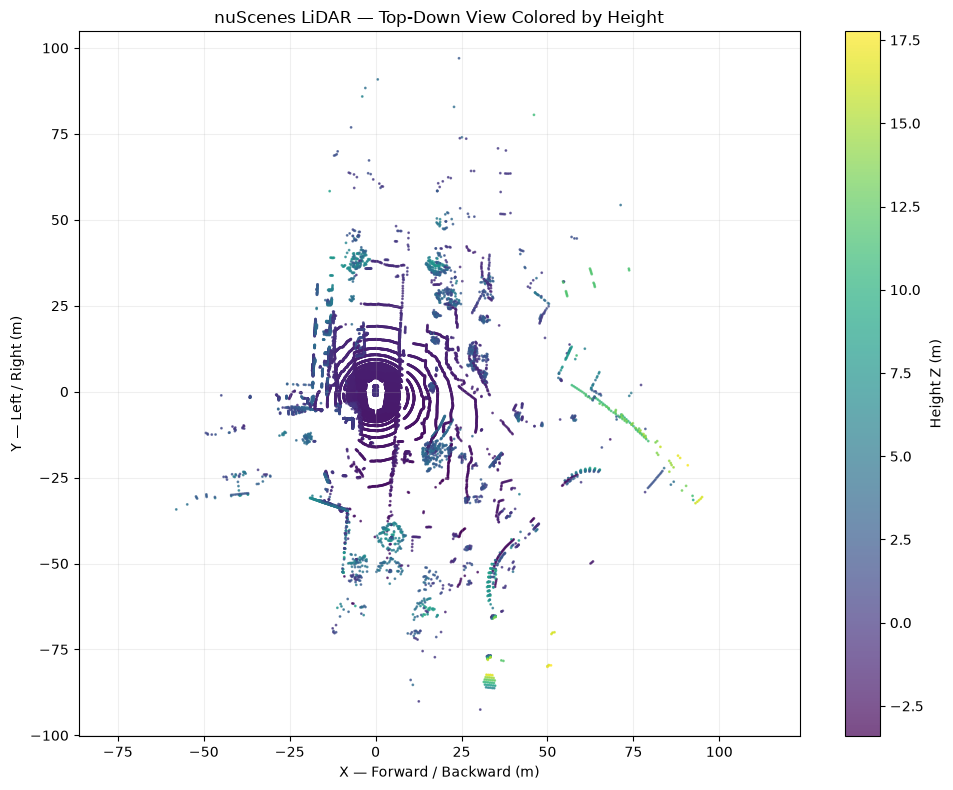

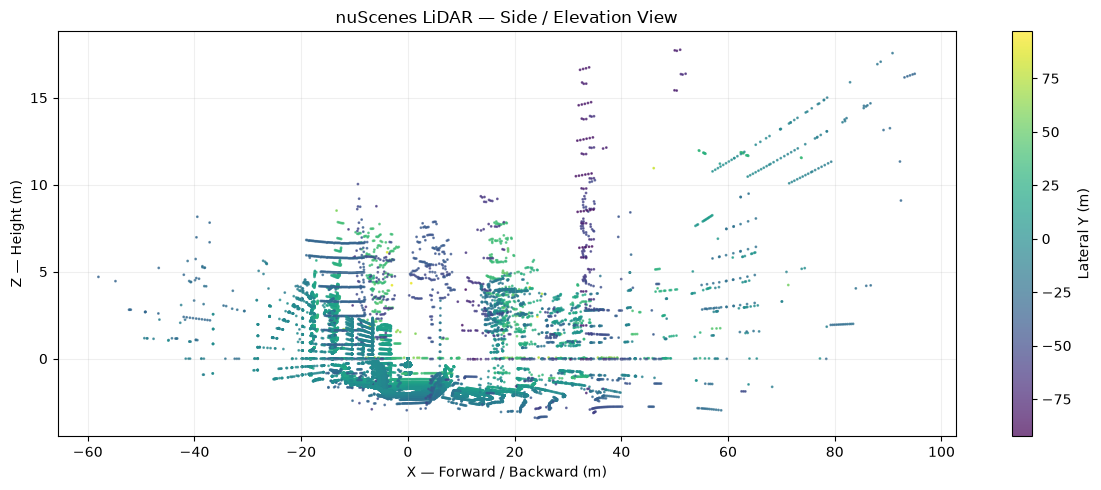

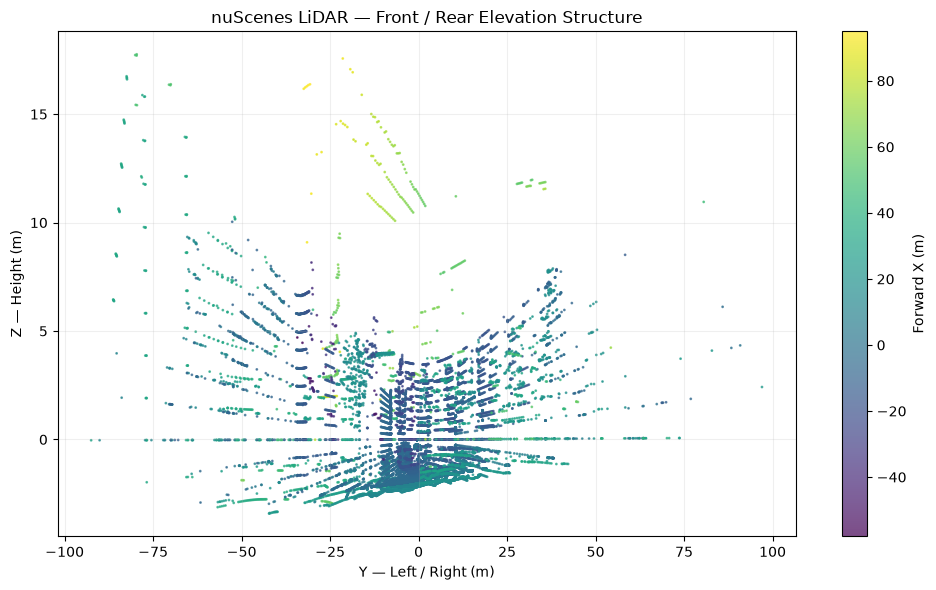

In [23]:
# Cell 10 — Visualize the raw nuScenes LiDAR scan

import matplotlib.pyplot as plt
import numpy as np

# ------------------------------------------------------------
# Use points within the SIH26053 operating range
# ------------------------------------------------------------

mask_100m = range_xy <= 100

x_plot = x[mask_100m]
y_plot = y[mask_100m]
z_plot = z[mask_100m]

print("Visualization dataset")
print("=" * 70)
print(f"Points used: {len(x_plot):,}")
print(f"Range     : <= 100 m")

# ------------------------------------------------------------
# 1. Top-down XY view
# ------------------------------------------------------------

plt.figure(figsize=(10, 8))

scatter = plt.scatter(
    x_plot,
    y_plot,
    c=z_plot,
    s=1,
    alpha=0.7
)

plt.colorbar(scatter, label="Height Z (m)")

plt.xlabel("X — Forward / Backward (m)")
plt.ylabel("Y — Left / Right (m)")

plt.title("nuScenes LiDAR — Top-Down View Colored by Height")

plt.axis("equal")
plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 2. XZ view
# ------------------------------------------------------------

plt.figure(figsize=(12, 5))

scatter = plt.scatter(
    x_plot,
    z_plot,
    c=y_plot,
    s=1,
    alpha=0.7
)

plt.colorbar(scatter, label="Lateral Y (m)")

plt.xlabel("X — Forward / Backward (m)")
plt.ylabel("Z — Height (m)")

plt.title("nuScenes LiDAR — Side / Elevation View")

plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# 3. YZ view
# ------------------------------------------------------------

plt.figure(figsize=(10, 6))

scatter = plt.scatter(
    y_plot,
    z_plot,
    c=x_plot,
    s=1,
    alpha=0.7
)

plt.colorbar(scatter, label="Forward X (m)")

plt.xlabel("Y — Left / Right (m)")
plt.ylabel("Z — Height (m)")

plt.title("nuScenes LiDAR — Front / Rear Elevation Structure")

plt.grid(alpha=0.2)
plt.tight_layout()
plt.show()

RAW LiDAR VISUALIZATION
Points displayed : 34,679
Operating range  : 0–100 m
Source scan      : ca9a282c9e77460f8360f564131a8af5


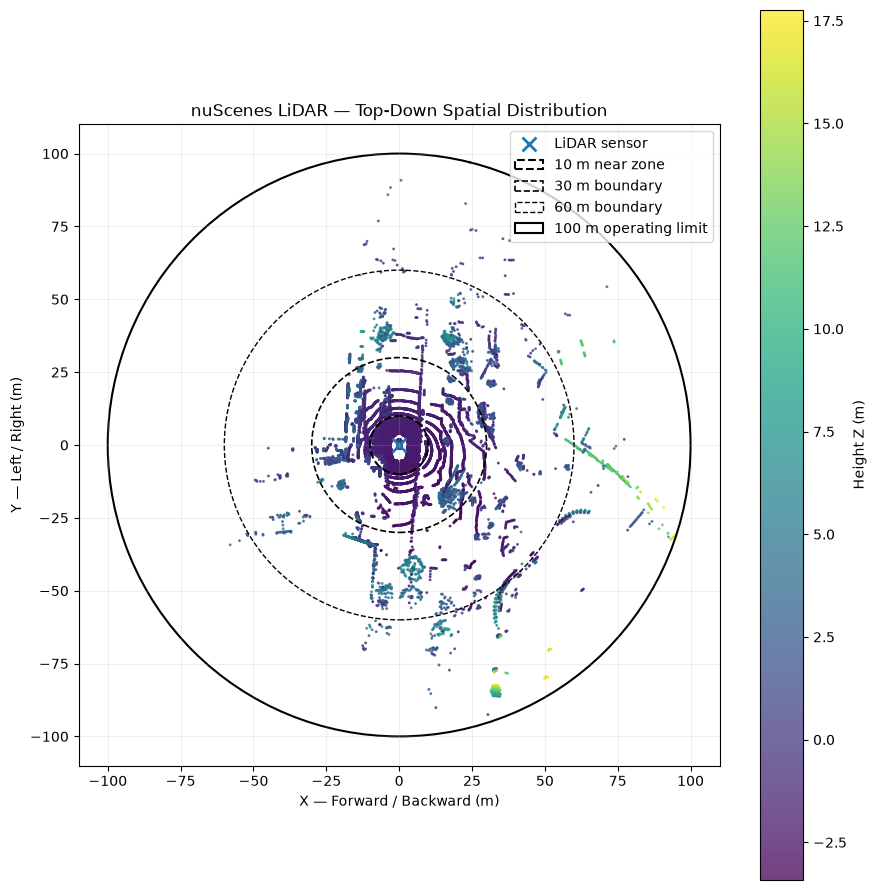

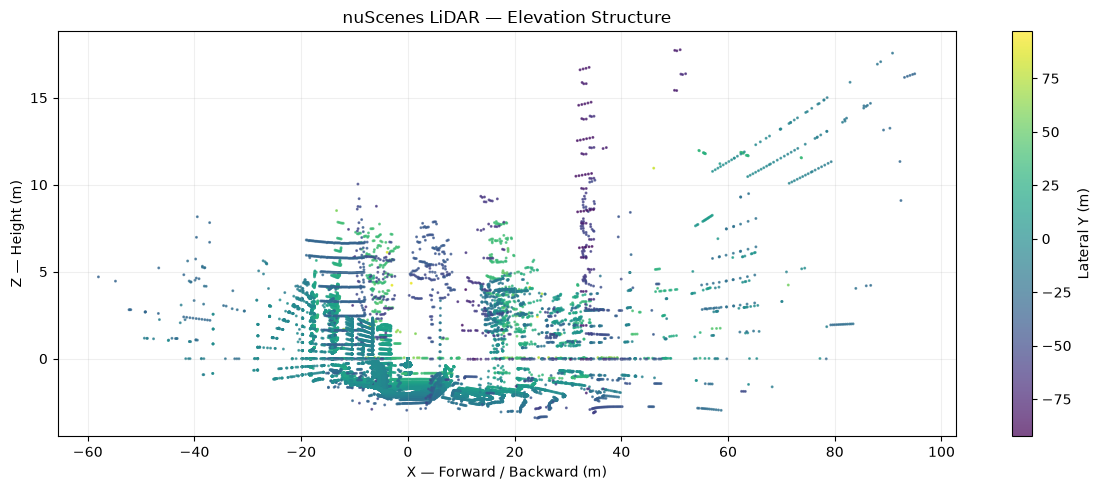

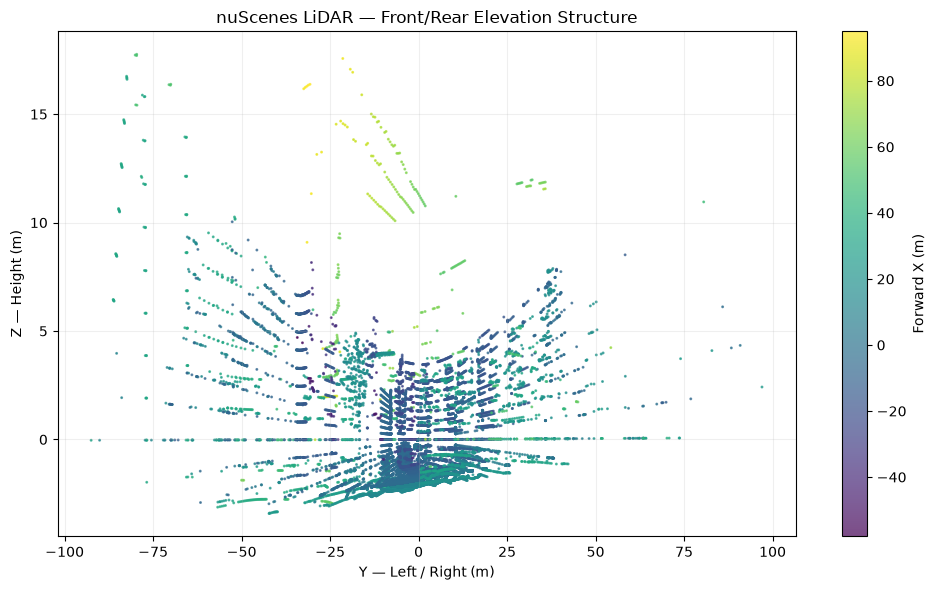


Visualization complete.


In [24]:
# Cell 10C — Visualize the raw nuScenes LiDAR scan

import matplotlib.pyplot as plt
import numpy as np

# ------------------------------------------------------------
# Verify required variables exist
# ------------------------------------------------------------

required = ["points", "x", "y", "z", "range_xy"]

missing = [name for name in required if name not in globals()]

if missing:
    raise RuntimeError(
        "Missing variables: " + ", ".join(missing) +
        ". The kernel was probably restarted. "
        "If this happens, tell me and I will restore the required cells."
    )

# ------------------------------------------------------------
# Keep only the SIH26053 operating range
# ------------------------------------------------------------

mask_100m = range_xy <= 100

x_plot = x[mask_100m]
y_plot = y[mask_100m]
z_plot = z[mask_100m]

print("RAW LiDAR VISUALIZATION")
print("=" * 70)
print(f"Points displayed : {len(x_plot):,}")
print(f"Operating range  : 0–100 m")
print(f"Source scan      : {nusc.sample[0]['token']}")

# ------------------------------------------------------------
# Figure 1 — Top-down point cloud
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(9, 9))

scatter = ax.scatter(
    x_plot,
    y_plot,
    c=z_plot,
    s=1.2,
    alpha=0.75
)

ax.scatter(
    0,
    0,
    marker="x",
    s=100,
    linewidths=2,
    label="LiDAR sensor"
)

circle = plt.Circle(
    (0, 0),
    10,
    fill=False,
    linewidth=1.5,
    linestyle="--",
    label="10 m near zone"
)

ax.add_patch(circle)

circle = plt.Circle(
    (0, 0),
    30,
    fill=False,
    linewidth=1.2,
    linestyle="--",
    label="30 m boundary"
)

ax.add_patch(circle)

circle = plt.Circle(
    (0, 0),
    60,
    fill=False,
    linewidth=1.0,
    linestyle="--",
    label="60 m boundary"
)

ax.add_patch(circle)

circle = plt.Circle(
    (0, 0),
    100,
    fill=False,
    linewidth=1.5,
    linestyle="-",
    label="100 m operating limit"
)

ax.add_patch(circle)

ax.set_xlabel("X — Forward / Backward (m)")
ax.set_ylabel("Y — Left / Right (m)")
ax.set_title("nuScenes LiDAR — Top-Down Spatial Distribution")

ax.set_aspect("equal")
ax.grid(alpha=0.2)
ax.legend(loc="upper right")

cbar = fig.colorbar(scatter, ax=ax)
cbar.set_label("Height Z (m)")

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# Figure 2 — Side elevation
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(12, 5))

scatter = ax.scatter(
    x_plot,
    z_plot,
    c=y_plot,
    s=1.2,
    alpha=0.7
)

ax.set_xlabel("X — Forward / Backward (m)")
ax.set_ylabel("Z — Height (m)")
ax.set_title("nuScenes LiDAR — Elevation Structure")

ax.grid(alpha=0.2)

cbar = fig.colorbar(scatter, ax=ax)
cbar.set_label("Lateral Y (m)")

plt.tight_layout()
plt.show()

# ------------------------------------------------------------
# Figure 3 — Front/rear elevation
# ------------------------------------------------------------

fig, ax = plt.subplots(figsize=(10, 6))

scatter = ax.scatter(
    y_plot,
    z_plot,
    c=x_plot,
    s=1.2,
    alpha=0.7
)

ax.set_xlabel("Y — Left / Right (m)")
ax.set_ylabel("Z — Height (m)")
ax.set_title("nuScenes LiDAR — Front/Rear Elevation Structure")

ax.grid(alpha=0.2)

cbar = fig.colorbar(scatter, ax=ax)
cbar.set_label("Forward X (m)")

plt.tight_layout()
plt.show()

print("\nVisualization complete.")

In [25]:
# Cell 11 — Inspect semantic labels in the first LiDAR scan

from collections import Counter

print("SEMANTIC LABEL ANALYSIS")
print("=" * 70)

# ------------------------------------------------------------
# Load lidarseg labels for the first LiDAR sample
# ------------------------------------------------------------

lidar_token = nusc.sample[0]["data"]["LIDAR_TOP"]

lidarseg_record = nusc.get("lidarseg", lidar_token)

label_path = DATASET_ROOT / lidarseg_record["filename"]

raw_labels = np.fromfile(label_path, dtype=np.uint8)

print(f"LiDAR points : {points.shape[0]:,}")
print(f"Labels       : {raw_labels.shape[0]:,}")

if len(raw_labels) != len(points):
    raise ValueError(
        f"Point/label mismatch: "
        f"{len(points):,} points vs {len(raw_labels):,} labels"
    )

print("Alignment    : MATCH")

# ------------------------------------------------------------
# Convert label IDs → nuScenes category names
# ------------------------------------------------------------

idx2name = nusc.lidarseg_idx2name_mapping

label_names = [
    idx2name[int(label)]
    for label in raw_labels
]

counts = Counter(label_names)

print("\nUnique semantic classes in this scan:")
print(f"  {len(counts)}")

print("\nClass distribution:")
print("-" * 75)

for name, count in counts.most_common():

    percentage = 100 * count / len(raw_labels)

    print(
        f"{name:45s} "
        f"{count:8,} "
        f"({percentage:6.2f}%)"
    )

SEMANTIC LABEL ANALYSIS
LiDAR points : 34,688
Labels       : 34,688
Alignment    : MATCH

Unique semantic classes in this scan:
  17

Class distribution:
---------------------------------------------------------------------------
flat.driveable_surface                          12,172 ( 35.09%)
vehicle.ego                                      8,526 ( 24.58%)
static.manmade                                   4,873 ( 14.05%)
static.vegetation                                4,034 ( 11.63%)
flat.terrain                                     2,602 (  7.50%)
flat.sidewalk                                      817 (  2.36%)
flat.other                                         629 (  1.81%)
vehicle.truck                                      494 (  1.42%)
movable_object.barrier                             312 (  0.90%)
human.pedestrian.adult                             113 (  0.33%)
vehicle.car                                         81 (  0.23%)
movable_object.trafficcone                          16 

In [26]:
# PROJECT STRUCTURE INSPECTION

from pathlib import Path

ROOT = Path(r"C:\Users\Akhila  Dogga\Desktop\Lidar")

print("=" * 80)
print("SIH26053 — PROJECT STRUCTURE")
print("=" * 80)

print(f"\nRoot: {ROOT}")
print(f"Exists: {ROOT.exists()}")
print(f"Is directory: {ROOT.is_dir()}")

if not ROOT.exists():
    raise FileNotFoundError(f"Project root not found: {ROOT}")

# ------------------------------------------------------------
# Show folders and files
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("DIRECT CONTENTS")
print("=" * 80)

for item in sorted(ROOT.iterdir(), key=lambda p: (not p.is_dir(), p.name.lower())):
    if item.is_dir():
        print(f"[DIR ]  {item.name}")
    else:
        size_mb = item.stat().st_size / (1024 * 1024)
        print(f"[FILE]  {item.name:<45} {size_mb:8.2f} MB")

# ------------------------------------------------------------
# Inspect important subdirectories
# ------------------------------------------------------------

IMPORTANT_DIRS = [
    "data",
    "src",
    "notebooks",
]

for dirname in IMPORTANT_DIRS:

    folder = ROOT / dirname

    print("\n" + "=" * 80)
    print(f"CONTENTS OF: {dirname}/")
    print("=" * 80)

    if not folder.exists():
        print("NOT FOUND")
        continue

    if not folder.is_dir():
        print("EXISTS BUT IS NOT A DIRECTORY")
        continue

    for item in sorted(
        folder.iterdir(),
        key=lambda p: (not p.is_dir(), p.name.lower())
    ):
        if item.is_dir():
            print(f"[DIR ]  {item.name}")
        else:
            size_mb = item.stat().st_size / (1024 * 1024)
            print(f"[FILE]  {item.name:<45} {size_mb:8.2f} MB")

# ------------------------------------------------------------
# Find Python project files
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("PYTHON FILES IN PROJECT")
print("=" * 80)

py_files = list(ROOT.rglob("*.py"))

if not py_files:
    print("No .py files found.")
else:
    for path in sorted(py_files):
        relative = path.relative_to(ROOT)
        print(relative)

# ------------------------------------------------------------
# Find Jupyter notebooks
# ------------------------------------------------------------

print("\n" + "=" * 80)
print("JUPYTER NOTEBOOKS")
print("=" * 80)

notebooks = list(ROOT.rglob("*.ipynb"))

if not notebooks:
    print("No notebooks found.")
else:
    for path in sorted(notebooks):
        relative = path.relative_to(ROOT)
        print(relative)

print("\n" + "=" * 80)
print("STRUCTURE INSPECTION COMPLETE")
print("=" * 80)

SIH26053 — PROJECT STRUCTURE

Root: C:\Users\Akhila  Dogga\Desktop\Lidar
Exists: True
Is directory: True

DIRECT CONTENTS
[DIR ]  .ipynb_checkpoints
[DIR ]  data

CONTENTS OF: data/
[DIR ]  .ipynb_checkpoints
[DIR ]  __pycache__
[DIR ]  lidarseg
[DIR ]  maps
[DIR ]  samples
[DIR ]  sweeps
[DIR ]  v1.0-mini
[FILE]  .v1.0-mini.txt                                    0.00 MB
[FILE]  nuScenes-lidarseg-mini-v1.0.tar.bz2               1.74 MB
[FILE]  nuscenes_adapter.py                               0.01 MB
[FILE]  nuscenes_class_mapping.py                         0.01 MB
[FILE]  Untitled.ipynb                                    0.06 MB
[FILE]  v1.0-mini.tgz                                  3974.62 MB

CONTENTS OF: src/
NOT FOUND

CONTENTS OF: notebooks/
NOT FOUND

PYTHON FILES IN PROJECT
data\.ipynb_checkpoints\nuscenes_adapter-checkpoint.py
data\.ipynb_checkpoints\nuscenes_class_mapping-checkpoint.py
data\nuscenes_adapter.py
data\nuscenes_class_mapping.py

JUPYTER NOTEBOOKS
data\.ipynb_chec

In [27]:
# ============================================================
# CELL 1 — SIH26053 CLASS MAPPING
# Environment and paths
# ============================================================

from pathlib import Path
import sys

PROJECT_DIR = Path.cwd()

# Your notebook and project .py files are directly inside data/
DATASET_ROOT = PROJECT_DIR

print("=" * 75)
print("SIH26053 — CLASS MAPPING")
print("=" * 75)

print("\nCurrent notebook directory:")
print(PROJECT_DIR)

print("\nPython executable:")
print(sys.executable)

print("\nDataset root:")
print(DATASET_ROOT)

print("\nRequired files:")
print(
    "  nuscenes_adapter.py       :",
    (PROJECT_DIR / "nuscenes_adapter.py").exists()
)

print(
    "  nuscenes_class_mapping.py :",
    (PROJECT_DIR / "nuscenes_class_mapping.py").exists()
)

if not (PROJECT_DIR / "nuscenes_adapter.py").exists():
    raise FileNotFoundError(
        f"Could not find:\n{PROJECT_DIR / 'nuscenes_adapter.py'}"
    )

if not (PROJECT_DIR / "nuscenes_class_mapping.py").exists():
    raise FileNotFoundError(
        f"Could not find:\n{PROJECT_DIR / 'nuscenes_class_mapping.py'}"
    )

# Make the CURRENT directory importable.
# There is intentionally NO src directory.
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))

print("\nPath configuration: OK")

SIH26053 — CLASS MAPPING

Current notebook directory:
C:\Users\Akhila  Dogga\Desktop\Lidar\data

Python executable:
C:\Users\24211\.conda\envs\lidar-nuscenes\python.exe

Dataset root:
C:\Users\Akhila  Dogga\Desktop\Lidar\data

Required files:
  nuscenes_adapter.py       : True
  nuscenes_class_mapping.py : True

Path configuration: OK


In [28]:
# ============================================================
# CELL 2 — Import project modules
# ============================================================

from nuscenes_adapter import NuScenesAdapter

from nuscenes_class_mapping import (
    NUSCENES_CATEGORY_TO_PROJECT_CLASS,
    project_class_for_category_name,
)

print("=" * 75)
print("PROJECT MODULE IMPORT")
print("=" * 75)

print("\nNuScenesAdapter:")
print("  OK")

print("\nClass mapping:")
print("  OK")

print(
    "\nNumber of mapping entries:",
    len(NUSCENES_CATEGORY_TO_PROJECT_CLASS)
)

print("\nAll project modules imported successfully.")

PROJECT MODULE IMPORT

NuScenesAdapter:
  OK

Class mapping:
  OK

Number of mapping entries: 32

All project modules imported successfully.


In [29]:
# ============================================================
# CELL 3 — Initialize nuScenes-mini through our adapter
# ============================================================

from pathlib import Path

# ------------------------------------------------------------
# Dataset configuration
# ------------------------------------------------------------

DATASET_ROOT = Path(
    r"C:\Users\Akhila  Dogga\Desktop\Lidar\data"
)

VERSION = "v1.0-mini"

print("=" * 75)
print("SIH26053 — nuScenes-mini ADAPTER INITIALIZATION")
print("=" * 75)

print("\nDataset root:")
print(DATASET_ROOT)

print("Exists:", DATASET_ROOT.exists())
print("Is directory:", DATASET_ROOT.is_dir())

print("\nDataset version:")
print(VERSION)

# ------------------------------------------------------------
# Initialize adapter
# ------------------------------------------------------------

adapter = NuScenesAdapter(
    dataroot=str(DATASET_ROOT),
    version=VERSION,
)

print("\n" + "=" * 75)
print("ADAPTER INITIALIZATION SUCCESSFUL")
print("=" * 75)

print("\nDataset summary:")

summary = adapter.summary()

for key, value in summary.items():
    print(f"{key:15s}: {value}")

SIH26053 — nuScenes-mini ADAPTER INITIALIZATION

Dataset root:
C:\Users\Akhila  Dogga\Desktop\Lidar\data
Exists: True
Is directory: True

Dataset version:
v1.0-mini

ADAPTER INITIALIZATION SUCCESSFUL

Dataset summary:
dataset        : nuScenes
version        : v1.0-mini
dataroot       : C:\Users\Akhila  Dogga\Desktop\Lidar\data
scenes         : 10
samples        : 404
sample_data    : 31206
annotations    : 18538
categories     : 32
sensors        : 12


In [30]:
# ============================================================
# CELL 4 — Inspect SIH26053 semantic class mapping
# ============================================================

from collections import defaultdict

print("=" * 75)
print("SIH26053 — NUSCENES → PROJECT CLASS MAPPING")
print("=" * 75)

# ------------------------------------------------------------
# Group nuScenes categories by project class
# ------------------------------------------------------------

by_project_class = defaultdict(list)

for category_name, project_class in (
    NUSCENES_CATEGORY_TO_PROJECT_CLASS.items()
):
    by_project_class[project_class].append(category_name)


# ------------------------------------------------------------
# Display mapping
# ------------------------------------------------------------

for project_class in [
    "drivable",
    "non_drivable",
    "static_obstacle",
    "dynamic_object",
    "unknown",
]:

    categories = sorted(
        by_project_class.get(
            project_class,
            []
        )
    )

    print("\n" + "-" * 75)
    print(
        f"{project_class.upper()} "
        f"({len(categories)} nuScenes categories)"
    )
    print("-" * 75)

    for category in categories:
        print(f"  {category}")


# ------------------------------------------------------------
# Validation
# ------------------------------------------------------------

mapped_categories = set(
    NUSCENES_CATEGORY_TO_PROJECT_CLASS.keys()
)

project_classes_used = set(
    NUSCENES_CATEGORY_TO_PROJECT_CLASS.values()
)

print("\n" + "=" * 75)
print("MAPPING VALIDATION")
print("=" * 75)

print(
    f"\nTotal mapping entries : "
    f"{len(mapped_categories)}"
)

print(
    f"Project classes used  : "
    f"{len(project_classes_used)}"
)

print("\nProject classes:")

for cls in sorted(project_classes_used):
    print(f"  ✓ {cls}")

if len(mapped_categories) == 32:
    print(
        "\n✓ All 32 nuScenes categories are represented."
    )
else:
    print(
        f"\n⚠ Expected 32 categories, "
        f"found {len(mapped_categories)}."
    )

print("\nCell 4 complete.")

SIH26053 — NUSCENES → PROJECT CLASS MAPPING

---------------------------------------------------------------------------
DRIVABLE (1 nuScenes categories)
---------------------------------------------------------------------------
  flat.driveable_surface

---------------------------------------------------------------------------
NON_DRIVABLE (4 nuScenes categories)
---------------------------------------------------------------------------
  flat.other
  flat.sidewalk
  flat.terrain
  static.vegetation

---------------------------------------------------------------------------
STATIC_OBSTACLE (4 nuScenes categories)
---------------------------------------------------------------------------
  movable_object.barrier
  movable_object.pushable_pullable
  movable_object.trafficcone
  static.manmade

---------------------------------------------------------------------------
DYNAMIC_OBJECT (16 nuScenes categories)
---------------------------------------------------------------------------

In [31]:
# ============================================================
# CELL 5 — Dataset-wide project class distribution
# ============================================================

from collections import Counter

print("=" * 75)
print("SIH26053 — DATASET-WIDE PROJECT CLASS DISTRIBUTION")
print("=" * 75)

# ------------------------------------------------------------
# Verify project classes represented by the mapping
# ------------------------------------------------------------

mapping_classes = set(
    NUSCENES_CATEGORY_TO_PROJECT_CLASS.values()
)

print("\nProject classes actually used by mapping:")

for cls in sorted(mapping_classes):
    print(f"  ✓ {cls}")


# ------------------------------------------------------------
# Create raw-label → project-class mapper
# ------------------------------------------------------------

label_mapper = adapter.label_mapper()

project_class_counts = Counter()

frames_processed = 0
frames_with_labels = 0
total_points = 0


# ------------------------------------------------------------
# Process every nuScenes-mini LiDAR frame
# ------------------------------------------------------------

print("\nProcessing dataset...")
print("-" * 75)

for frame in adapter.frames():

    frames_processed += 1

    if frame.raw_labels is None:
        continue

    frames_with_labels += 1

    total_points += len(frame.raw_labels)

    for raw_value in frame.raw_labels:
        project_class = label_mapper(raw_value)

        project_class_counts[project_class] += 1


# ------------------------------------------------------------
# Results
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("PROCESSING SUMMARY")
print("=" * 75)

print(f"\nFrames processed       : {frames_processed}")
print(f"Frames with labels     : {frames_with_labels}")
print(f"Total labeled points   : {total_points:,}")


# ------------------------------------------------------------
# Class distribution
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("PROJECT CLASS DISTRIBUTION")
print("=" * 75)

if total_points == 0:

    print("\nERROR: No labeled points were found.")

else:

    print(
        f"\n{'PROJECT CLASS':<20}"
        f"{'POINTS':>15}"
        f"{'PERCENT':>12}"
    )

    print("-" * 47)

    for cls, count in project_class_counts.most_common():

        percentage = (
            100.0 * count / total_points
        )

        print(
            f"{cls:<20}"
            f"{count:>15,}"
            f"{percentage:>11.2f}%"
        )


# ------------------------------------------------------------
# Check that percentages sum to approximately 100%
# ------------------------------------------------------------

percentage_sum = (
    100.0 * sum(project_class_counts.values())
    / total_points
    if total_points > 0
    else 0
)

print("-" * 47)

print(
    f"{'TOTAL':<20}"
    f"{sum(project_class_counts.values()):>15,}"
    f"{percentage_sum:>11.2f}%"
)

print("\nCell 5 complete.")

SIH26053 — DATASET-WIDE PROJECT CLASS DISTRIBUTION

Project classes actually used by mapping:
  ✓ drivable
  ✓ dynamic_object
  ✓ non_drivable
  ✓ static_obstacle
  ✓ unknown

Processing dataset...
---------------------------------------------------------------------------

PROCESSING SUMMARY

Frames processed       : 404
Frames with labels     : 404
Total labeled points   : 14,026,208

PROJECT CLASS DISTRIBUTION

PROJECT CLASS                POINTS     PERCENT
-----------------------------------------------
drivable                  4,069,879      29.02%
unknown                   3,664,609      26.13%
non_drivable              3,158,856      22.52%
static_obstacle           2,131,382      15.20%
dynamic_object            1,001,482       7.14%
-----------------------------------------------
TOTAL                    14,026,208     100.00%

Cell 5 complete.


In [32]:
# ============================================================
# CELL 6 — Class imbalance analysis and training weights
# ============================================================

import numpy as np

print("=" * 75)
print("SIH26053 — CLASS IMBALANCE ANALYSIS")
print("=" * 75)

# ------------------------------------------------------------
# Target classes
# ------------------------------------------------------------

TARGET_CLASSES = [
    "drivable",
    "non_drivable",
    "static_obstacle",
    "dynamic_object",
]

print("\nTraining target classes:")
for i, cls in enumerate(TARGET_CLASSES):
    print(f"  {i}: {cls}")


# ------------------------------------------------------------
# Extract counts
# ------------------------------------------------------------

target_counts = np.array(
    [
        project_class_counts.get(cls, 0)
        for cls in TARGET_CLASSES
    ],
    dtype=np.float64,
)

target_total = target_counts.sum()

print("\nTarget points:")
print("-" * 55)

for cls, count in zip(TARGET_CLASSES, target_counts):
    percentage = (
        100.0 * count / target_total
        if target_total > 0
        else 0.0
    )

    print(
        f"{cls:<20}"
        f"{int(count):>15,}"
        f"{percentage:>11.2f}%"
    )


# ------------------------------------------------------------
# Ignore / unknown points
# ------------------------------------------------------------

unknown_count = project_class_counts.get(
    "unknown",
    0
)

all_points = target_total + unknown_count

print("\n" + "-" * 55)

print(
    f"{'unknown / ignored':<20}"
    f"{unknown_count:>15,}"
    f"{100.0 * unknown_count / all_points:>11.2f}%"
)

print(
    f"{'all labeled points':<20}"
    f"{int(all_points):>15,}"
    f"{100.0:>11.2f}%"
)


# ------------------------------------------------------------
# Imbalance ratio
# ------------------------------------------------------------

largest = target_counts.max()
smallest = target_counts.min()

if smallest > 0:
    imbalance_ratio = largest / smallest
else:
    imbalance_ratio = np.inf

print("\n" + "=" * 75)
print("IMBALANCE METRICS")
print("=" * 75)

print(
    f"\nMost frequent target class : "
    f"{TARGET_CLASSES[int(np.argmax(target_counts))]}"
)

print(
    f"Least frequent target class : "
    f"{TARGET_CLASSES[int(np.argmin(target_counts))]}"
)

print(
    f"\nLargest / smallest ratio : "
    f"{imbalance_ratio:.2f}x"
)


# ------------------------------------------------------------
# Inverse-frequency weights
# ------------------------------------------------------------

# Normalized inverse-frequency weighting:
#
# weight_i = total / (number_of_classes × count_i)
#
# This gives an average class weight of approximately 1.

class_weights = (
    target_total
    / (
        len(TARGET_CLASSES)
        * target_counts
    )
)

print("\n" + "=" * 75)
print("INITIAL CLASS WEIGHTS")
print("=" * 75)

for cls, count, weight in zip(
    TARGET_CLASSES,
    target_counts,
    class_weights,
):

    print(
        f"{cls:<20}"
        f"count={int(count):>10,}   "
        f"weight={weight:.4f}"
    )


# ------------------------------------------------------------
# Save variables for later notebooks
# ------------------------------------------------------------

CLASS_TO_ID = {
    cls: i
    for i, cls in enumerate(TARGET_CLASSES)
}

ID_TO_CLASS = {
    i: cls
    for cls, i in CLASS_TO_ID.items()
}

print("\n" + "=" * 75)
print("TRAINING LABEL CONFIGURATION")
print("=" * 75)

print("\nCLASS_TO_ID:")

for cls, idx in CLASS_TO_ID.items():
    print(f"  {cls:<20} → {idx}")

print("\nCell 6 complete.")

SIH26053 — CLASS IMBALANCE ANALYSIS

Training target classes:
  0: drivable
  1: non_drivable
  2: static_obstacle
  3: dynamic_object

Target points:
-------------------------------------------------------
drivable                  4,069,879      39.28%
non_drivable              3,158,856      30.49%
static_obstacle           2,131,382      20.57%
dynamic_object            1,001,482       9.67%

-------------------------------------------------------
unknown / ignored         3,664,609      26.13%
all labeled points       14,026,208     100.00%

IMBALANCE METRICS

Most frequent target class : drivable
Least frequent target class : dynamic_object

Largest / smallest ratio : 4.06x

INITIAL CLASS WEIGHTS
drivable            count= 4,069,879   weight=0.6365
non_drivable        count= 3,158,856   weight=0.8200
static_obstacle     count= 2,131,382   weight=1.2154
dynamic_object      count= 1,001,482   weight=2.5866

TRAINING LABEL CONFIGURATION

CLASS_TO_ID:
  drivable             → 0
  non

In [33]:
# ============================================================
# CELL 7 — Raw label → project class sanity check
# ============================================================

print("=" * 75)
print("SIH26053 — RAW LABEL → PROJECT CLASS SANITY CHECK")
print("=" * 75)

# ------------------------------------------------------------
# Get nuScenes raw label-name mapping
# ------------------------------------------------------------

idx2name = adapter._nusc.lidarseg_idx2name_mapping

label_mapper = adapter.label_mapper()

print("\nnuScenes raw label mappings:")
print("-" * 75)

checked = 0

for raw_id in sorted(idx2name.keys()):

    raw_name = idx2name[raw_id]

    project_class = label_mapper(raw_id)

    print(
        f"raw_id={raw_id:2d}  "
        f"{raw_name:<45} → "
        f"{project_class}"
    )

    checked += 1


# ------------------------------------------------------------
# Validation
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("SANITY CHECK")
print("=" * 75)

print(
    f"\nRaw label IDs inspected : {checked}"
)

print(
    f"Expected nuScenes labels: "
    f"{len(NUSCENES_CATEGORY_TO_PROJECT_CLASS)}"
)

if checked == len(
    NUSCENES_CATEGORY_TO_PROJECT_CLASS
):
    print(
        "\n✓ Every mapped nuScenes category "
        "has a raw-label mapping."
    )
else:
    print(
        "\n⚠ Raw-label count and mapping count differ."
    )

print("\nCell 7 complete.")

SIH26053 — RAW LABEL → PROJECT CLASS SANITY CHECK

nuScenes raw label mappings:
---------------------------------------------------------------------------
raw_id= 0  noise                                         → unknown
raw_id= 1  animal                                        → unknown
raw_id= 2  human.pedestrian.adult                        → dynamic_object
raw_id= 3  human.pedestrian.child                        → dynamic_object
raw_id= 4  human.pedestrian.construction_worker          → dynamic_object
raw_id= 5  human.pedestrian.personal_mobility            → unknown
raw_id= 6  human.pedestrian.police_officer               → dynamic_object
raw_id= 7  human.pedestrian.stroller                     → dynamic_object
raw_id= 8  human.pedestrian.wheelchair                   → dynamic_object
raw_id= 9  movable_object.barrier                        → static_obstacle
raw_id=10  movable_object.debris                         → unknown
raw_id=11  movable_object.pushable_pullable              

In [34]:
# ============================================================
# CELL 1 — SIH26053 LiDAR Visualization Setup
# ============================================================

from pathlib import Path
import sys
import numpy as np
import matplotlib.pyplot as plt

# ------------------------------------------------------------
# Project paths
# ------------------------------------------------------------

PROJECT_ROOT = Path(r"C:\Users\Akhila  Dogga\Desktop\Lidar")
DATASET_ROOT = PROJECT_ROOT / "data"

print("=" * 75)
print("SIH26053 — LIDAR VISUALIZATION")
print("=" * 75)

print("\nProject root:")
print(PROJECT_ROOT)

print("Exists:", PROJECT_ROOT.exists())

print("\nDataset root:")
print(DATASET_ROOT)

print("Exists:", DATASET_ROOT.exists())

# ------------------------------------------------------------
# Make data directory importable
# ------------------------------------------------------------

DATA_DIR = str(DATASET_ROOT)

if DATA_DIR not in sys.path:
    sys.path.insert(0, DATA_DIR)

print("\nPython import path configured:")
print(DATA_DIR)

# ------------------------------------------------------------
# Visualization configuration
# ------------------------------------------------------------

FRAME_INDEX = 0
MAX_RANGE = 100.0

print("\nVisualization configuration:")
print("  Frame index :", FRAME_INDEX)
print("  Max range   :", MAX_RANGE, "m")

print("\nCell 1 complete.")

SIH26053 — LIDAR VISUALIZATION

Project root:
C:\Users\Akhila  Dogga\Desktop\Lidar
Exists: True

Dataset root:
C:\Users\Akhila  Dogga\Desktop\Lidar\data
Exists: True

Python import path configured:
C:\Users\Akhila  Dogga\Desktop\Lidar\data

Visualization configuration:
  Frame index : 0
  Max range   : 100.0 m

Cell 1 complete.


In [35]:
# ============================================================
# CELL 2 — Import nuScenes adapter and class mapping
# ============================================================

print("=" * 75)
print("SIH26053 — IMPORTING DATASET MODULES")
print("=" * 75)

from nuscenes_adapter import NuScenesAdapter
from nuscenes_class_mapping import (
    project_class_for_category_name,
    NUSCENES_CATEGORY_TO_PROJECT_CLASS,
)

print("\nNuScenesAdapter:")
print("  OK")

print("\nClass mapping:")
print("  OK")

print(
    "\nMapping entries:",
    len(NUSCENES_CATEGORY_TO_PROJECT_CLASS)
)

print("\nCell 2 complete.")

SIH26053 — IMPORTING DATASET MODULES

NuScenesAdapter:
  OK

Class mapping:
  OK

Mapping entries: 32

Cell 2 complete.


In [36]:
# ============================================================
# CELL 3 — Initialize nuScenes-mini and select frame
# ============================================================

print("=" * 75)
print("SIH26053 — FRAME SELECTION")
print("=" * 75)

# ------------------------------------------------------------
# Initialize adapter
# ------------------------------------------------------------

adapter = NuScenesAdapter(
    dataroot=str(DATASET_ROOT),
    version="v1.0-mini"
)

label_mapper = adapter.label_mapper()

# ------------------------------------------------------------
# Select requested frame
# ------------------------------------------------------------

frame = None

for i, candidate in enumerate(adapter.frames()):
    if i == FRAME_INDEX:
        frame = candidate
        break

if frame is None:
    raise IndexError(
        f"Frame index {FRAME_INDEX} does not exist."
    )

# ------------------------------------------------------------
# Extract data
# ------------------------------------------------------------

pts = np.asarray(frame.points)

raw_labels = (
    np.asarray(frame.raw_labels)
    if frame.raw_labels is not None
    else None
)

# ------------------------------------------------------------
# Validate
# ------------------------------------------------------------

print("\nDataset:")
print("  Version :", "v1.0-mini")
print("  Scenes  :", len(adapter._nusc.scene))
print("  Samples :", len(adapter._nusc.sample))

print("\nSelected frame:")
print("  Frame index :", FRAME_INDEX)
print("  Scene       :", frame.sequence_id)
print("  Frame ID    :", frame.frame_id)

print("\nPoint cloud:")
print("  Shape       :", pts.shape)
print("  Points      :", pts.shape[0])
print("  Dimensions  :", pts.shape[1])

if raw_labels is not None:
    print("\nSemantic labels:")
    print("  Labels      :", raw_labels.shape[0])
    print(
        "  Alignment   :",
        "MATCH" if len(raw_labels) == len(pts) else "ERROR"
    )
else:
    print("\nSemantic labels:")
    print("  NOT AVAILABLE")

if pts.shape[1] < 3:
    raise ValueError(
        "Point cloud must contain at least X, Y and Z."
    )

if raw_labels is None:
    raise ValueError(
        "Semantic labels are required for this visualization notebook."
    )

if len(raw_labels) != len(pts):
    raise ValueError(
        "Point/label count mismatch."
    )

print("\nCell 3 complete.")

SIH26053 — FRAME SELECTION

Dataset:
  Version : v1.0-mini
  Scenes  : 10
  Samples : 404

Selected frame:
  Frame index : 0
  Scene       : cc8c0bf57f984915a77078b10eb33198
  Frame ID    : ca9a282c9e77460f8360f564131a8af5

Point cloud:
  Shape       : (34688, 5)
  Points      : 34688
  Dimensions  : 5

Semantic labels:
  Labels      : 34688
  Alignment   : MATCH

Cell 3 complete.


In [37]:
# ============================================================
# CELL 4 — Convert labels to SIH26053 project classes
# ============================================================

print("=" * 75)
print("SIH26053 — PROJECT CLASS GENERATION")
print("=" * 75)

# ------------------------------------------------------------
# Convert every raw nuScenes label to project taxonomy
# ------------------------------------------------------------

project_classes = np.array(
    [label_mapper(label) for label in raw_labels],
    dtype=object
)

# ------------------------------------------------------------
# Validate
# ------------------------------------------------------------

unique_classes, class_counts = np.unique(
    project_classes,
    return_counts=True
)

print("\nClasses detected in selected frame:")
print("-" * 55)

for cls, count in zip(unique_classes, class_counts):

    percentage = 100.0 * count / len(project_classes)

    print(
        f"{cls:<20}"
        f"{count:>10,}"
        f" ({percentage:6.2f}%)"
    )

# ------------------------------------------------------------
# Basic validation
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("VALIDATION")
print("=" * 75)

print(
    "\nPoints:",
    len(project_classes)
)

print(
    "Labels:",
    len(raw_labels)
)

print(
    "Alignment:",
    "MATCH"
    if len(project_classes) == len(pts)
    else "ERROR"
)

print(
    "\nNumber of project classes:",
    len(unique_classes)
)

print("\nCell 4 complete.")

SIH26053 — PROJECT CLASS GENERATION

Classes detected in selected frame:
-------------------------------------------------------
drivable                12,172 ( 35.09%)
dynamic_object             697 (  2.01%)
non_drivable             8,082 ( 23.30%)
static_obstacle          5,210 ( 15.02%)
unknown                  8,527 ( 24.58%)

VALIDATION

Points: 34688
Labels: 34688
Alignment: MATCH

Number of project classes: 5

Cell 4 complete.


In [38]:
# ============================================================
# CELL 5 — Apply SIH26053 0–100 m operating region
# ============================================================

print("=" * 75)
print("SIH26053 — 0–100 m OPERATING REGION")
print("=" * 75)

# ------------------------------------------------------------
# Compute planar distance from LiDAR sensor
# ------------------------------------------------------------

x = pts[:, 0]
y = pts[:, 1]
z = pts[:, 2]

planar_range = np.sqrt(
    x ** 2 + y ** 2
)

# ------------------------------------------------------------
# Operating-region mask
# ------------------------------------------------------------

range_mask = (
    planar_range <= MAX_RANGE
)

# ------------------------------------------------------------
# Filter points
# ------------------------------------------------------------

vis_pts = pts[range_mask]
vis_classes = project_classes[range_mask]
vis_range = planar_range[range_mask]

# ------------------------------------------------------------
# Statistics
# ------------------------------------------------------------

total_points = len(pts)
visible_points = len(vis_pts)
excluded_points = total_points - visible_points

print("\nOriginal point count:")
print(f"  {total_points:,}")

print("\nPoints within 100 m:")
print(f"  {visible_points:,}")

print("\nPoints beyond 100 m:")
print(f"  {excluded_points:,}")

print(
    "\nPercentage retained:"
    f" {100.0 * visible_points / total_points:.2f}%"
)

print(
    "Percentage excluded:"
    f" {100.0 * excluded_points / total_points:.2f}%"
)

print("\nVisualization point bounds:")

print(
    f"  X: {vis_pts[:,0].min():.2f} → "
    f"{vis_pts[:,0].max():.2f} m"
)

print(
    f"  Y: {vis_pts[:,1].min():.2f} → "
    f"{vis_pts[:,1].max():.2f} m"
)

print(
    f"  Z: {vis_pts[:,2].min():.2f} → "
    f"{vis_pts[:,2].max():.2f} m"
)

print("\nCell 5 complete.")


SIH26053 — 0–100 m OPERATING REGION

Original point count:
  34,688

Points within 100 m:
  34,679

Points beyond 100 m:
  9

Percentage retained: 99.97%
Percentage excluded: 0.03%

Visualization point bounds:
  X: -58.00 → 94.98 m
  Y: -92.50 → 97.00 m
  Z: -3.42 → 17.76 m

Cell 5 complete.


SIH26053 — RAW LiDAR VISUALIZATION


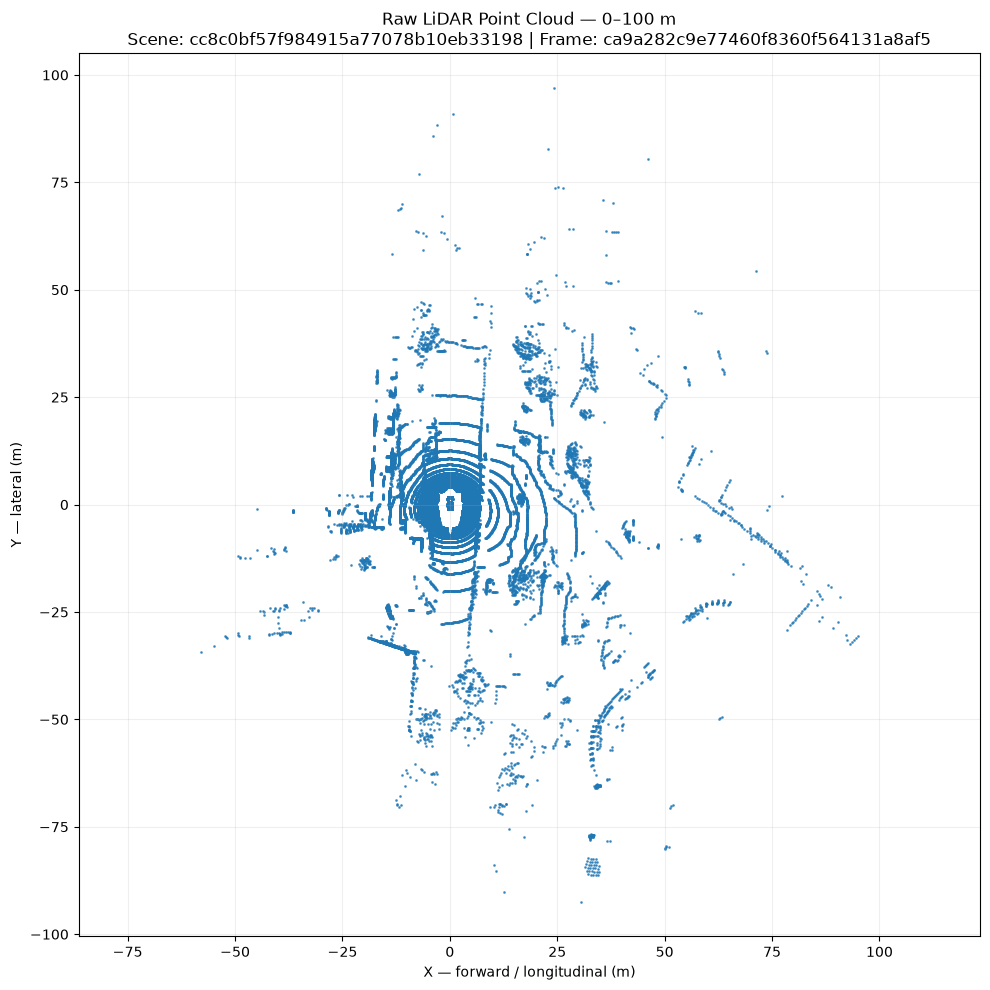


Visualization saved to:
C:\Users\Akhila  Dogga\Desktop\Lidar\fig_01_raw_lidar.png

Points displayed:
  34,679
Operating range:
  0–100 m

Cell 6 complete.


In [39]:
# ============================================================
# CELL 6 — Raw LiDAR top-down visualization
# ============================================================

print("=" * 75)
print("SIH26053 — RAW LiDAR VISUALIZATION")
print("=" * 75)

plt.figure(figsize=(10, 10))

plt.scatter(
    vis_pts[:, 0],
    vis_pts[:, 1],
    s=1,
    alpha=0.7
)

plt.xlabel("X — forward / longitudinal (m)")
plt.ylabel("Y — lateral (m)")

plt.title(
    f"Raw LiDAR Point Cloud — 0–100 m\n"
    f"Scene: {frame.sequence_id} | Frame: {frame.frame_id}"
)

plt.axis("equal")
plt.grid(alpha=0.2)
plt.tight_layout()

RAW_FIGURE = PROJECT_ROOT / "fig_01_raw_lidar.png"

plt.savefig(
    RAW_FIGURE,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("\nVisualization saved to:")
print(RAW_FIGURE)

print("\nPoints displayed:")
print(f"  {len(vis_pts):,}")

print("Operating range:")
print(f"  0–{MAX_RANGE:.0f} m")

print("\nCell 6 complete.")

SIH26053 — TERRAIN / GROUND VISUALIZATION

Terrain classification:
-------------------------------------------------------
Drivable terrain     : 12,172 (35.10%)
Non-drivable terrain : 8,081 (23.30%)
Other classes         : 14,426 (41.60%)


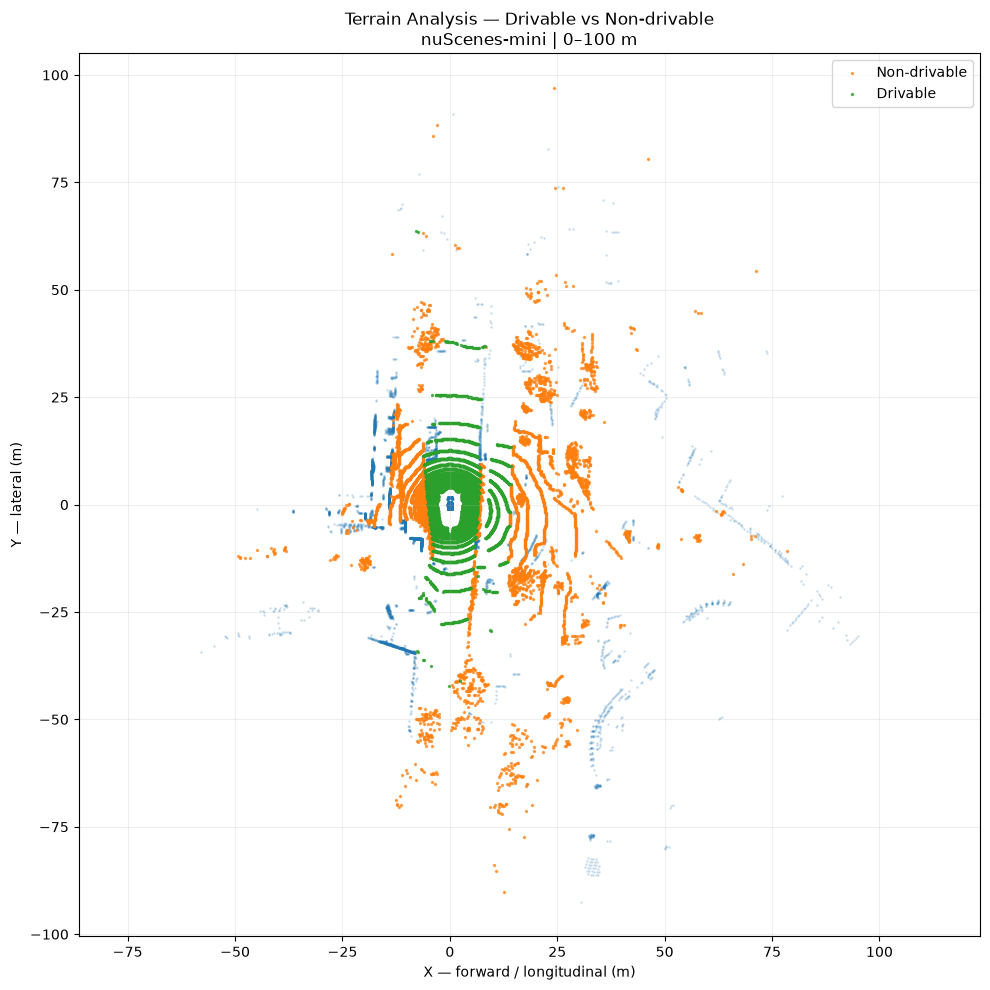


Visualization saved to:
C:\Users\Akhila  Dogga\Desktop\Lidar\fig_02_ground.png

Cell 7 complete.


In [40]:
# ============================================================
# CELL 7 — Ground / terrain semantic visualization
# ============================================================

print("=" * 75)
print("SIH26053 — TERRAIN / GROUND VISUALIZATION")
print("=" * 75)

# ------------------------------------------------------------
# Create masks
# ------------------------------------------------------------

drivable_mask = vis_classes == "drivable"
non_drivable_mask = vis_classes == "non_drivable"

ground_mask = (
    drivable_mask |
    non_drivable_mask
)

other_mask = ~ground_mask

# ------------------------------------------------------------
# Count points
# ------------------------------------------------------------

print("\nTerrain classification:")
print("-" * 55)

print(
    f"Drivable terrain     : "
    f"{drivable_mask.sum():,} "
    f"({100 * drivable_mask.mean():.2f}%)"
)

print(
    f"Non-drivable terrain : "
    f"{non_drivable_mask.sum():,} "
    f"({100 * non_drivable_mask.mean():.2f}%)"
)

print(
    f"Other classes         : "
    f"{other_mask.sum():,} "
    f"({100 * other_mask.mean():.2f}%)"
)

# ------------------------------------------------------------
# Visualization
# ------------------------------------------------------------

plt.figure(figsize=(10, 10))

# Other points — background
plt.scatter(
    vis_pts[other_mask, 0],
    vis_pts[other_mask, 1],
    s=1,
    alpha=0.15
)

# Non-drivable terrain
plt.scatter(
    vis_pts[non_drivable_mask, 0],
    vis_pts[non_drivable_mask, 1],
    s=2,
    alpha=0.65,
    label="Non-drivable"
)

# Drivable terrain
plt.scatter(
    vis_pts[drivable_mask, 0],
    vis_pts[drivable_mask, 1],
    s=2,
    alpha=0.75,
    label="Drivable"
)

plt.xlabel("X — forward / longitudinal (m)")
plt.ylabel("Y — lateral (m)")

plt.title(
    "Terrain Analysis — Drivable vs Non-drivable\n"
    "nuScenes-mini | 0–100 m"
)

plt.axis("equal")
plt.grid(alpha=0.2)
plt.legend()

plt.tight_layout()

GROUND_FIGURE = PROJECT_ROOT / "fig_02_ground.png"

plt.savefig(
    GROUND_FIGURE,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("\nVisualization saved to:")
print(GROUND_FIGURE)

print("\nCell 7 complete.")

SIH26053 — STATIC OBSTACLE VISUALIZATION

Static obstacle points:
  5,202 (15.00%)

Background / other points:
  29,477 (85.00%)


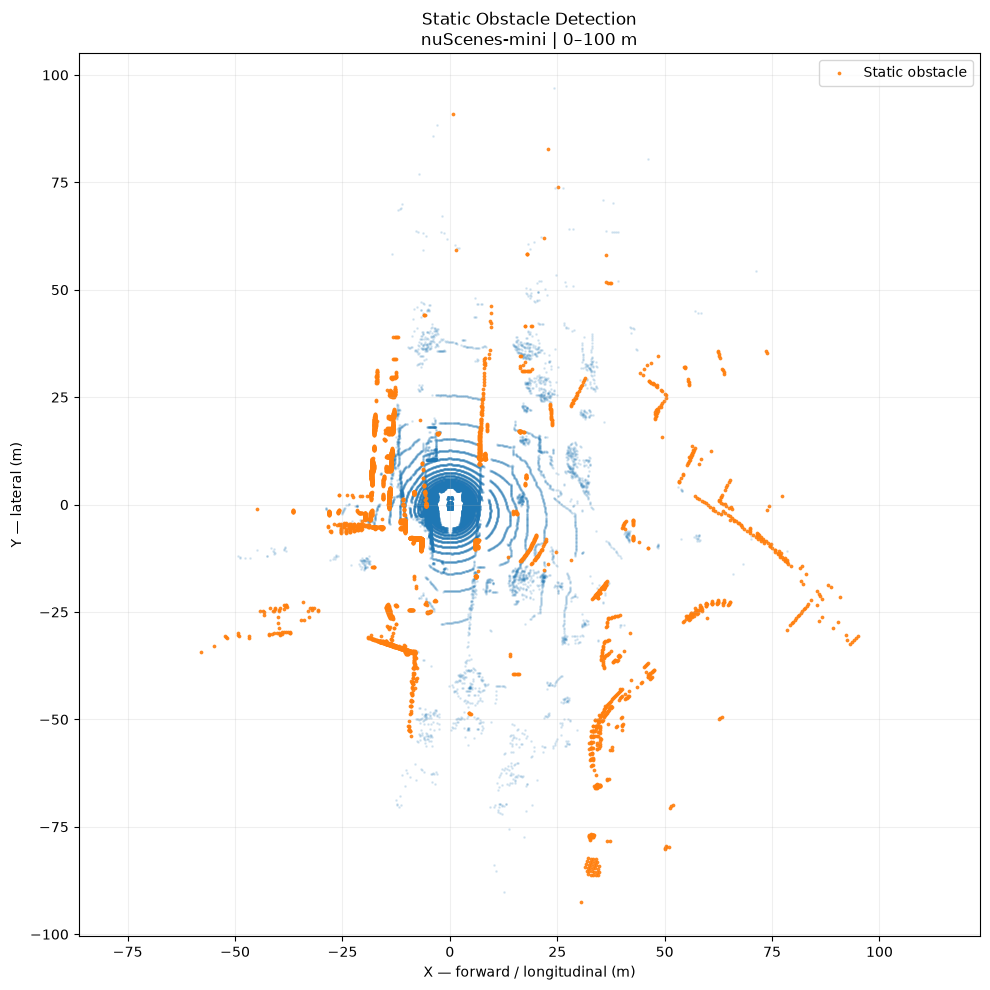


Visualization saved to:
C:\Users\Akhila  Dogga\Desktop\Lidar\fig_03_static.png

Cell 8 complete.


In [41]:
# ============================================================
# CELL 8 — Static obstacle visualization
# ============================================================

print("=" * 75)
print("SIH26053 — STATIC OBSTACLE VISUALIZATION")
print("=" * 75)

# ------------------------------------------------------------
# Static obstacle mask
# ------------------------------------------------------------

static_mask = (
    vis_classes == "static_obstacle"
)

background_mask = ~static_mask

# ------------------------------------------------------------
# Statistics
# ------------------------------------------------------------

print("\nStatic obstacle points:")
print(
    f"  {static_mask.sum():,} "
    f"({100 * static_mask.mean():.2f}%)"
)

print("\nBackground / other points:")
print(
    f"  {background_mask.sum():,} "
    f"({100 * background_mask.mean():.2f}%)"
)

# ------------------------------------------------------------
# Visualization
# ------------------------------------------------------------

plt.figure(figsize=(10, 10))

# Background
plt.scatter(
    vis_pts[background_mask, 0],
    vis_pts[background_mask, 1],
    s=1,
    alpha=0.12
)

# Static obstacles
plt.scatter(
    vis_pts[static_mask, 0],
    vis_pts[static_mask, 1],
    s=3,
    alpha=0.85,
    label="Static obstacle"
)

plt.xlabel("X — forward / longitudinal (m)")
plt.ylabel("Y — lateral (m)")

plt.title(
    "Static Obstacle Detection\n"
    "nuScenes-mini | 0–100 m"
)

plt.axis("equal")
plt.grid(alpha=0.2)
plt.legend()

plt.tight_layout()

STATIC_FIGURE = PROJECT_ROOT / "fig_03_static.png"

plt.savefig(
    STATIC_FIGURE,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("\nVisualization saved to:")
print(STATIC_FIGURE)

print("\nCell 8 complete.")

SIH26053 — DYNAMIC OBJECT VISUALIZATION

Dynamic object points:
  697 (2.01%)

Background / other points:
  33,982 (97.99%)


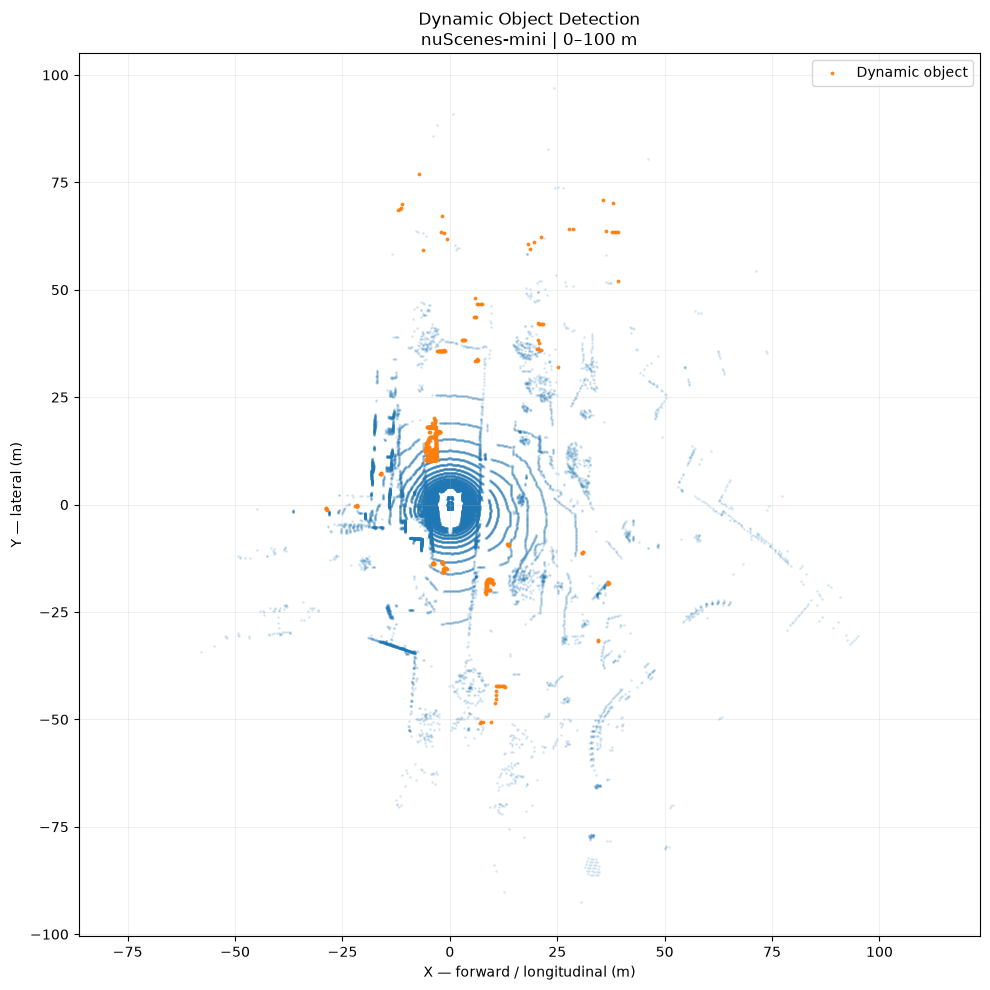


Visualization saved to:
C:\Users\Akhila  Dogga\Desktop\Lidar\fig_04_dynamic.png

Cell 9 complete.


In [42]:
# ============================================================
# CELL 9 — Dynamic object visualization
# ============================================================

print("=" * 75)
print("SIH26053 — DYNAMIC OBJECT VISUALIZATION")
print("=" * 75)

# ------------------------------------------------------------
# Dynamic object mask
# ------------------------------------------------------------

dynamic_mask = (
    vis_classes == "dynamic_object"
)

background_mask = ~dynamic_mask

# ------------------------------------------------------------
# Statistics
# ------------------------------------------------------------

print("\nDynamic object points:")
print(
    f"  {dynamic_mask.sum():,} "
    f"({100 * dynamic_mask.mean():.2f}%)"
)

print("\nBackground / other points:")
print(
    f"  {background_mask.sum():,} "
    f"({100 * background_mask.mean():.2f}%)"
)

# ------------------------------------------------------------
# Visualization
# ------------------------------------------------------------

plt.figure(figsize=(10, 10))

# Background
plt.scatter(
    vis_pts[background_mask, 0],
    vis_pts[background_mask, 1],
    s=1,
    alpha=0.12
)

# Dynamic objects
plt.scatter(
    vis_pts[dynamic_mask, 0],
    vis_pts[dynamic_mask, 1],
    s=3,
    alpha=0.9,
    label="Dynamic object"
)

plt.xlabel("X — forward / longitudinal (m)")
plt.ylabel("Y — lateral (m)")

plt.title(
    "Dynamic Object Detection\n"
    "nuScenes-mini | 0–100 m"
)

plt.axis("equal")
plt.grid(alpha=0.2)
plt.legend()

plt.tight_layout()

DYNAMIC_FIGURE = PROJECT_ROOT / "fig_04_dynamic.png"

plt.savefig(
    DYNAMIC_FIGURE,
    dpi=200,
    bbox_inches="tight"
)

plt.show()

print("\nVisualization saved to:")
print(DYNAMIC_FIGURE)

print("\nCell 9 complete.")

In [43]:
# ============================================================
# CELL 10 — Final verification
# ============================================================

print("=" * 75)
print("SIH26053 — 03_LIDAR_VISUALIZATION FINAL CHECK")
print("=" * 75)

figures = {
    "Raw LiDAR"        : RAW_FIGURE,
    "Ground / Terrain" : GROUND_FIGURE,
    "Static Obstacles" : STATIC_FIGURE,
    "Dynamic Objects"  : DYNAMIC_FIGURE,
}

print("\nRequired visualization files:")
print("-" * 75)

all_present = True

for name, path in figures.items():

    exists = path.exists()

    status = "✓ FOUND" if exists else "✗ MISSING"

    print(f"{status:10} | {name:<20} | {path}")

    if not exists:
        all_present = False

print("\n" + "=" * 75)

if all_present:
    print("✓ ALL FOUR VISUALIZATIONS GENERATED SUCCESSFULLY")
    print("✓ 03_lidar_visualization.ipynb COMPLETE")
else:
    print("✗ ONE OR MORE FIGURES ARE MISSING")
    print("03_lidar_visualization.ipynb is NOT complete.")

print("=" * 75)

print("\nVisualization summary:")
print(f"  Dataset       : nuScenes-mini")
print(f"  Frame index   : {FRAME_INDEX}")
print(f"  Frame ID      : {frame.frame_id}")
print(f"  Points used   : {len(vis_pts):,}")
print(f"  Operating     : 0–{MAX_RANGE:.0f} m")
print(f"  Classes       : {len(unique_classes)}")

print("\nCell 10 complete.")

SIH26053 — 03_LIDAR_VISUALIZATION FINAL CHECK

Required visualization files:
---------------------------------------------------------------------------
✓ FOUND    | Raw LiDAR            | C:\Users\Akhila  Dogga\Desktop\Lidar\fig_01_raw_lidar.png
✓ FOUND    | Ground / Terrain     | C:\Users\Akhila  Dogga\Desktop\Lidar\fig_02_ground.png
✓ FOUND    | Static Obstacles     | C:\Users\Akhila  Dogga\Desktop\Lidar\fig_03_static.png
✓ FOUND    | Dynamic Objects      | C:\Users\Akhila  Dogga\Desktop\Lidar\fig_04_dynamic.png

✓ ALL FOUR VISUALIZATIONS GENERATED SUCCESSFULLY
✓ 03_lidar_visualization.ipynb COMPLETE

Visualization summary:
  Dataset       : nuScenes-mini
  Frame index   : 0
  Frame ID      : ca9a282c9e77460f8360f564131a8af5
  Points used   : 34,679
  Operating     : 0–100 m
  Classes       : 5

Cell 10 complete.


In [44]:
# ============================================================
# CELL 1 — PREPROCESSING CONFIGURATION
# ============================================================

from pathlib import Path
import sys
import json

import numpy as np

print("=" * 75)
print("SIH26053 — 04 PREPROCESSING")
print("=" * 75)

# ------------------------------------------------------------
# Project paths
# ------------------------------------------------------------

PROJECT_ROOT = Path(
    r"C:\Users\Akhila  Dogga\Desktop\Lidar"
)

DATASET_ROOT = PROJECT_ROOT / "data"

OUTPUT_DIR = PROJECT_ROOT / "preprocessed"

# SIH26053 operating range
MAX_RANGE_M = 100.0

# ------------------------------------------------------------
# Create output directory
# ------------------------------------------------------------

OUTPUT_DIR.mkdir(
    parents=True,
    exist_ok=True
)

# ------------------------------------------------------------
# Validate paths
# ------------------------------------------------------------

print("\nProject root:")
print(f"  {PROJECT_ROOT}")
print(f"  Exists: {PROJECT_ROOT.exists()}")

print("\nDataset root:")
print(f"  {DATASET_ROOT}")
print(f"  Exists: {DATASET_ROOT.exists()}")

print("\nPreprocessed output:")
print(f"  {OUTPUT_DIR}")
print(f"  Exists: {OUTPUT_DIR.exists()}")

print("\nConfiguration:")
print(f"  Dataset       : nuScenes-mini v1.0")
print(f"  Maximum range : {MAX_RANGE_M:.1f} m")

if not PROJECT_ROOT.is_dir():
    raise FileNotFoundError(
        f"Project root not found:\n{PROJECT_ROOT}"
    )

if not DATASET_ROOT.is_dir():
    raise FileNotFoundError(
        f"Dataset root not found:\n{DATASET_ROOT}"
    )

print("\nCell 1 complete.")

SIH26053 — 04 PREPROCESSING

Project root:
  C:\Users\Akhila  Dogga\Desktop\Lidar
  Exists: True

Dataset root:
  C:\Users\Akhila  Dogga\Desktop\Lidar\data
  Exists: True

Preprocessed output:
  C:\Users\Akhila  Dogga\Desktop\Lidar\preprocessed
  Exists: True

Configuration:
  Dataset       : nuScenes-mini v1.0
  Maximum range : 100.0 m

Cell 1 complete.


In [45]:
# ============================================================
# CELL 2 — IMPORT DATASET MODULES
# ============================================================

print("=" * 75)
print("SIH26053 — PREPROCESSING MODULE IMPORT")
print("=" * 75)

# Make the data directory importable
DATA_DIR = str(DATASET_ROOT)

if DATA_DIR not in sys.path:
    sys.path.insert(0, DATA_DIR)

# Import the adapter
from nuscenes_adapter import NuScenesAdapter

# Import the project class mapping
from nuscenes_class_mapping import (
    project_class_for_category_name,
    NUSCENES_CATEGORY_TO_PROJECT_CLASS,
)

print("\nNuScenesAdapter:")
print("  OK")

print("\nClass mapping:")
print("  OK")

print(
    "\nMapping entries:",
    len(NUSCENES_CATEGORY_TO_PROJECT_CLASS)
)

print("\nCell 2 complete.")

SIH26053 — PREPROCESSING MODULE IMPORT

NuScenesAdapter:
  OK

Class mapping:
  OK

Mapping entries: 32

Cell 2 complete.


In [46]:
# ============================================================
# CELL 3 — INITIALIZE DATASET
# ============================================================

print("=" * 75)
print("SIH26053 — PREPROCESSING DATASET INITIALIZATION")
print("=" * 75)

adapter = NuScenesAdapter(
    dataroot=str(DATASET_ROOT),
    version="v1.0-mini"
)

label_mapper = adapter.label_mapper()

# Materialize the frame list once.
# This makes the later preprocessing deterministic.
frames = list(adapter.frames())

print("\nDataset:")
print("  Name       : nuScenes")
print("  Version    : v1.0-mini")
print(f"  Scenes     : {len(adapter._nusc.scene)}")
print(f"  Samples    : {len(adapter._nusc.sample)}")

print("\nLiDAR frames:")
print(f"  Total      : {len(frames)}")

if len(frames) == 0:
    raise RuntimeError(
        "No LiDAR frames were returned by NuScenesAdapter."
    )

# ------------------------------------------------------------
# Inspect first frame
# ------------------------------------------------------------

first_frame = frames[0]

print("\nFirst frame:")
print(f"  Scene      : {first_frame.sequence_id}")
print(f"  Frame ID   : {first_frame.frame_id}")
print(f"  Points     : {first_frame.points.shape[0]}")
print(f"  Dimensions : {first_frame.points.shape[1]}")

if first_frame.raw_labels is None:
    raise RuntimeError(
        "First frame does not contain semantic LiDAR labels."
    )

print(f"  Labels     : {len(first_frame.raw_labels)}")

if len(first_frame.points) != len(first_frame.raw_labels):
    raise RuntimeError(
        "Point/label alignment failed."
    )

print("  Alignment  : MATCH")

print("\nCell 3 complete.")

SIH26053 — PREPROCESSING DATASET INITIALIZATION

Dataset:
  Name       : nuScenes
  Version    : v1.0-mini
  Scenes     : 10
  Samples    : 404

LiDAR frames:
  Total      : 404

First frame:
  Scene      : cc8c0bf57f984915a77078b10eb33198
  Frame ID   : ca9a282c9e77460f8360f564131a8af5
  Points     : 34688
  Dimensions : 5
  Labels     : 34688
  Alignment  : MATCH

Cell 3 complete.


In [47]:
# ============================================================
# CELL 4 — PREPROCESSING RULES
# ============================================================

print("=" * 75)
print("SIH26053 — PREPROCESSING RULES")
print("=" * 75)

# ------------------------------------------------------------
# Target training classes
# ------------------------------------------------------------

CLASS_TO_ID = {
    "drivable": 0,
    "non_drivable": 1,
    "static_obstacle": 2,
    "dynamic_object": 3,
}

ID_TO_CLASS = {
    value: key
    for key, value in CLASS_TO_ID.items()
}

IGNORE_CLASS = "unknown"
IGNORE_ID = 255

# ------------------------------------------------------------
# Input feature definition
# ------------------------------------------------------------

FEATURE_NAMES = [
    "x",
    "y",
    "z",
    "intensity",
    "range",
]

FEATURE_DIM = len(FEATURE_NAMES)

# ------------------------------------------------------------
# Preprocessing policy
# ------------------------------------------------------------

PREPROCESSING_RULES = {
    "max_range_m": MAX_RANGE_M,
    "remove_nan": True,
    "remove_inf": True,
    "keep_unknown": True,
    "unknown_label_id": IGNORE_ID,
    "normalize_intensity": True,
    "preserve_xyz": True,
    "compute_range": True,
}

print("\nTarget classes:")
for class_name, class_id in CLASS_TO_ID.items():
    print(f"  {class_id}: {class_name}")

print(f"\nIgnored class:")
print(f"  {IGNORE_CLASS} → {IGNORE_ID}")

print("\nInput features:")
for i, name in enumerate(FEATURE_NAMES):
    print(f"  [{i}] {name}")

print("\nPreprocessing rules:")
for key, value in PREPROCESSING_RULES.items():
    print(f"  {key:<22}: {value}")

print("\nCell 4 complete.")

SIH26053 — PREPROCESSING RULES

Target classes:
  0: drivable
  1: non_drivable
  2: static_obstacle
  3: dynamic_object

Ignored class:
  unknown → 255

Input features:
  [0] x
  [1] y
  [2] z
  [3] intensity
  [4] range

Preprocessing rules:
  max_range_m           : 100.0
  remove_nan            : True
  remove_inf            : True
  keep_unknown          : True
  unknown_label_id      : 255
  normalize_intensity   : True
  preserve_xyz          : True
  compute_range         : True

Cell 4 complete.


In [48]:
# ============================================================
# CELL 5 — SINGLE-FRAME PREPROCESSING TEST
# ============================================================

print("=" * 75)
print("SIH26053 — SINGLE FRAME PREPROCESSING TEST")
print("=" * 75)

# ------------------------------------------------------------
# Select first frame
# ------------------------------------------------------------

test_frame = frames[0]

raw_points = np.asarray(
    test_frame.points,
    dtype=np.float32
)

raw_labels = np.asarray(
    test_frame.raw_labels
)

print("\nInput:")
print(f"  Scene       : {test_frame.sequence_id}")
print(f"  Frame       : {test_frame.frame_id}")
print(f"  Points      : {len(raw_points):,}")
print(f"  Point fields: {raw_points.shape[1]}")
print(f"  Labels      : {len(raw_labels):,}")

# ------------------------------------------------------------
# Validate raw alignment
# ------------------------------------------------------------

if len(raw_points) != len(raw_labels):
    raise ValueError(
        "Raw point/label count mismatch."
    )

# ------------------------------------------------------------
# Extract XYZ + intensity
# ------------------------------------------------------------

xyz = raw_points[:, :3]

intensity = raw_points[:, 3]

# ------------------------------------------------------------
# Remove invalid values
# ------------------------------------------------------------

finite_mask = np.isfinite(
    raw_points[:, :4]
).all(axis=1)

points_finite = raw_points[finite_mask]
labels_finite = raw_labels[finite_mask]

dropped_invalid = (
    len(raw_points) - len(points_finite)
)

# ------------------------------------------------------------
# Compute planar range
# ------------------------------------------------------------

planar_range = np.sqrt(
    points_finite[:, 0] ** 2 +
    points_finite[:, 1] ** 2
)

# ------------------------------------------------------------
# Apply 100 m operating range
# ------------------------------------------------------------

range_mask = (
    planar_range <= MAX_RANGE_M
)

points_range = points_finite[range_mask]
labels_range = labels_finite[range_mask]
range_values = planar_range[range_mask]

dropped_range = (
    len(points_finite) - len(points_range)
)

# ------------------------------------------------------------
# Normalize intensity
# ------------------------------------------------------------

processed_intensity = (
    points_range[:, 3] / 255.0
).astype(np.float32)

processed_intensity = np.clip(
    processed_intensity,
    0.0,
    1.0
)

# ------------------------------------------------------------
# Convert semantic labels
# ------------------------------------------------------------

processed_labels = np.empty(
    len(labels_range),
    dtype=np.uint8
)

for i, raw_label in enumerate(labels_range):

    project_class = label_mapper(
        int(raw_label)
    )

    processed_labels[i] = CLASS_TO_ID.get(
        project_class,
        IGNORE_ID
    )

# ------------------------------------------------------------
# Build final feature matrix
# ------------------------------------------------------------

processed_points = np.column_stack(
    [
        points_range[:, 0],   # x
        points_range[:, 1],   # y
        points_range[:, 2],   # z
        processed_intensity,  # intensity [0,1]
        range_values,         # planar range
    ]
).astype(np.float32)

# ------------------------------------------------------------
# Validation
# ------------------------------------------------------------

if len(processed_points) != len(processed_labels):
    raise ValueError(
        "Processed point/label alignment failed."
    )

if not np.isfinite(processed_points).all():
    raise ValueError(
        "Processed features contain NaN or Inf."
    )

print("\nPreprocessing result:")
print("-" * 60)

print(
    f"  Original points       : {len(raw_points):,}"
)

print(
    f"  Invalid removed       : {dropped_invalid:,}"
)

print(
    f"  Out-of-range removed  : {dropped_range:,}"
)

print(
    f"  Final points          : {len(processed_points):,}"
)

print(
    f"  Final feature shape   : {processed_points.shape}"
)

print(
    f"  Final label shape     : {processed_labels.shape}"
)

print(
    "  Point/label alignment : "
    + (
        "MATCH"
        if len(processed_points) == len(processed_labels)
        else "ERROR"
    )
)

print("\nFeature ranges:")

for i, name in enumerate(FEATURE_NAMES):
    print(
        f"  {name:<10}: "
        f"{processed_points[:, i].min():.4f}"
        f" → "
        f"{processed_points[:, i].max():.4f}"
    )

print("\nLabel IDs present:")

unique_ids, counts = np.unique(
    processed_labels,
    return_counts=True
)

for label_id, count in zip(unique_ids, counts):

    if label_id == IGNORE_ID:
        name = "unknown / ignore"
    else:
        name = ID_TO_CLASS[int(label_id)]

    print(
        f"  {int(label_id):>3} "
        f"{name:<20} "
        f"{count:>8,} "
        f"({100 * count / len(processed_labels):6.2f}%)"
    )

print("\nCell 5 complete.")

SIH26053 — SINGLE FRAME PREPROCESSING TEST

Input:
  Scene       : cc8c0bf57f984915a77078b10eb33198
  Frame       : ca9a282c9e77460f8360f564131a8af5
  Points      : 34,688
  Point fields: 5
  Labels      : 34,688

Preprocessing result:
------------------------------------------------------------
  Original points       : 34,688
  Invalid removed       : 0
  Out-of-range removed  : 9
  Final points          : 34,679
  Final feature shape   : (34679, 5)
  Final label shape     : (34679,)
  Point/label alignment : MATCH

Feature ranges:
  x         : -57.9958 → 94.9848
  y         : -92.5005 → 97.0032
  z         : -3.4167 → 17.7606
  intensity : 0.0000 → 1.0000
  range     : 0.0000 → 99.9925

Label IDs present:
    0 drivable               12,172 ( 35.10%)
    1 non_drivable            8,081 ( 23.30%)
    2 static_obstacle         5,202 ( 15.00%)
    3 dynamic_object            697 (  2.01%)
  255 unknown / ignore        8,527 ( 24.59%)

Cell 5 complete.


In [49]:
# ============================================================
# CELL 6 — FULL DATASET PREPROCESSING
# ============================================================

print("=" * 75)
print("SIH26053 — FULL DATASET PREPROCESSING")
print("=" * 75)

total_original = 0
total_kept = 0
total_dropped_invalid = 0
total_dropped_range = 0

processed_frames = 0
processed_scenes = set()

# ------------------------------------------------------------
# Process every frame
# ------------------------------------------------------------

for frame_index, frame in enumerate(frames):

    raw_points = np.asarray(
        frame.points,
        dtype=np.float32
    )

    raw_labels = np.asarray(
        frame.raw_labels
    )

    total_original += len(raw_points)

    # --------------------------------------------------------
    # Remove NaN / Inf
    # --------------------------------------------------------

    finite_mask = np.isfinite(
        raw_points[:, :4]
    ).all(axis=1)

    points_finite = raw_points[finite_mask]
    labels_finite = raw_labels[finite_mask]

    dropped_invalid = (
        len(raw_points) - len(points_finite)
    )

    # --------------------------------------------------------
    # Compute planar range
    # --------------------------------------------------------

    planar_range = np.sqrt(
        points_finite[:, 0] ** 2 +
        points_finite[:, 1] ** 2
    )

    # --------------------------------------------------------
    # Apply operating range
    # --------------------------------------------------------

    range_mask = (
        planar_range <= MAX_RANGE_M
    )

    points_range = points_finite[range_mask]
    labels_range = labels_finite[range_mask]
    range_values = planar_range[range_mask]

    dropped_range = (
        len(points_finite) - len(points_range)
    )

    # --------------------------------------------------------
    # Normalize intensity
    # --------------------------------------------------------

    processed_intensity = (
        points_range[:, 3] / 255.0
    ).astype(np.float32)

    processed_intensity = np.clip(
        processed_intensity,
        0.0,
        1.0
    )

    # --------------------------------------------------------
    # Convert labels to project IDs
    # --------------------------------------------------------

    processed_labels = np.empty(
        len(labels_range),
        dtype=np.uint8
    )

    for i, raw_label in enumerate(labels_range):

        project_class = label_mapper(
            int(raw_label)
        )

        processed_labels[i] = CLASS_TO_ID.get(
            project_class,
            IGNORE_ID
        )

    # --------------------------------------------------------
    # Build feature matrix
    # --------------------------------------------------------

    processed_points = np.column_stack(
        [
            points_range[:, 0],   # x
            points_range[:, 1],   # y
            points_range[:, 2],   # z
            processed_intensity,  # intensity
            range_values,         # planar range
        ]
    ).astype(np.float32)

    # --------------------------------------------------------
    # Validate
    # --------------------------------------------------------

    if len(processed_points) != len(processed_labels):
        raise ValueError(
            f"Point/label mismatch at frame {frame_index}: "
            f"{len(processed_points)} vs "
            f"{len(processed_labels)}"
        )

    if not np.isfinite(processed_points).all():
        raise ValueError(
            f"NaN/Inf detected after preprocessing "
            f"at frame {frame_index}"
        )

    # --------------------------------------------------------
    # Scene output directory
    # --------------------------------------------------------

    scene_dir = OUTPUT_DIR / str(
        frame.sequence_id
    )

    scene_dir.mkdir(
        parents=True,
        exist_ok=True
    )

    # --------------------------------------------------------
    # Save frame
    # --------------------------------------------------------

    output_file = (
        scene_dir /
        f"{frame_index:06d}_{frame.frame_id}.npz"
    )

    np.savez_compressed(
        output_file,
        points=processed_points,
        labels=processed_labels,
        sequence_id=np.array(
            frame.sequence_id
        ),
        frame_id=np.array(
            frame.frame_id
        ),
    )

    # --------------------------------------------------------
    # Update statistics
    # --------------------------------------------------------

    total_kept += len(processed_points)
    total_dropped_invalid += dropped_invalid
    total_dropped_range += dropped_range

    processed_frames += 1
    processed_scenes.add(
        frame.sequence_id
    )

    # --------------------------------------------------------
    # Progress
    # --------------------------------------------------------

    if (
        (frame_index + 1) % 25 == 0
        or frame_index == 0
        or frame_index == len(frames) - 1
    ):
        print(
            f"  [{frame_index + 1:3d}/{len(frames)}] "
            f"frames processed | "
            f"points kept: {total_kept:,}"
        )

# ------------------------------------------------------------
# Final summary
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("FULL PREPROCESSING COMPLETE")
print("=" * 75)

print(f"\nFrames processed        : {processed_frames:,}")
print(f"Scenes processed        : {len(processed_scenes):,}")
print(f"Original points         : {total_original:,}")
print(f"Points retained         : {total_kept:,}")
print(f"Invalid points removed  : {total_dropped_invalid:,}")
print(f"Out-of-range removed    : {total_dropped_range:,}")

retention = (
    100.0 * total_kept / total_original
    if total_original > 0
    else 0.0
)

print(f"Overall retention       : {retention:.2f}%")

print(f"\nOutput directory:")
print(f"  {OUTPUT_DIR}")

print("\nCell 6 complete.")

SIH26053 — FULL DATASET PREPROCESSING
  [  1/404] frames processed | points kept: 34,679
  [ 25/404] frames processed | points kept: 867,743
  [ 50/404] frames processed | points kept: 1,735,686
  [ 75/404] frames processed | points kept: 2,603,692
  [100/404] frames processed | points kept: 3,471,265
  [125/404] frames processed | points kept: 4,338,965
  [150/404] frames processed | points kept: 5,207,050
  [175/404] frames processed | points kept: 6,074,546
  [200/404] frames processed | points kept: 6,942,732
  [225/404] frames processed | points kept: 7,810,721
  [250/404] frames processed | points kept: 8,678,386
  [275/404] frames processed | points kept: 9,546,450
  [300/404] frames processed | points kept: 10,414,417
  [325/404] frames processed | points kept: 11,282,219
  [350/404] frames processed | points kept: 12,149,919
  [375/404] frames processed | points kept: 13,017,614
  [400/404] frames processed | points kept: 13,885,577
  [404/404] frames processed | points kept: 

In [50]:
# ============================================================
# CELL 7 — VERIFY PREPROCESSED DATASET
# ============================================================

print("=" * 75)
print("SIH26053 — PREPROCESSED DATASET VERIFICATION")
print("=" * 75)

# ------------------------------------------------------------
# Find all generated NPZ files
# ------------------------------------------------------------

npz_files = sorted(
    OUTPUT_DIR.rglob("*.npz")
)

print("\nGenerated files:")
print(f"  NPZ files : {len(npz_files):,}")

if len(npz_files) != len(frames):
    raise RuntimeError(
        f"Expected {len(frames)} NPZ files, "
        f"but found {len(npz_files)}."
    )

# ------------------------------------------------------------
# Check scene distribution
# ------------------------------------------------------------

scene_file_counts = {}

for file_path in npz_files:

    scene_name = file_path.parent.name

    scene_file_counts[scene_name] = (
        scene_file_counts.get(scene_name, 0) + 1
    )

print("\nScene distribution:")
for scene_name, count in sorted(
    scene_file_counts.items()
):
    print(
        f"  {scene_name} : {count:3d} files"
    )

if len(scene_file_counts) != 10:
    raise RuntimeError(
        f"Expected 10 scenes, "
        f"found {len(scene_file_counts)}."
    )

# ------------------------------------------------------------
# Inspect first generated file
# ------------------------------------------------------------

test_file = npz_files[0]

print("\nFirst preprocessed file:")
print(f"  {test_file}")

with np.load(
    test_file,
    allow_pickle=False
) as data:

    required_keys = {
        "points",
        "labels",
        "sequence_id",
        "frame_id",
    }

    actual_keys = set(data.files)

    print("\nStored arrays:")
    for key in data.files:
        print(
            f"  {key:<12} "
            f"shape={data[key].shape} "
            f"dtype={data[key].dtype}"
        )

    missing_keys = (
        required_keys - actual_keys
    )

    if missing_keys:
        raise RuntimeError(
            f"Missing required arrays: {missing_keys}"
        )

    test_points = data["points"]
    test_labels = data["labels"]

# ------------------------------------------------------------
# Validate first file
# ------------------------------------------------------------

if test_points.ndim != 2:
    raise RuntimeError(
        "Points array must be 2-dimensional."
    )

if test_points.shape[1] != FEATURE_DIM:
    raise RuntimeError(
        f"Expected {FEATURE_DIM} features, "
        f"found {test_points.shape[1]}."
    )

if len(test_points) != len(test_labels):
    raise RuntimeError(
        "Point/label alignment failed."
    )

if not np.isfinite(test_points).all():
    raise RuntimeError(
        "Preprocessed points contain NaN or Inf."
    )

# ------------------------------------------------------------
# Validate label IDs
# ------------------------------------------------------------

valid_label_ids = set(
    CLASS_TO_ID.values()
)

valid_label_ids.add(
    IGNORE_ID
)

actual_label_ids = set(
    np.unique(test_labels).tolist()
)

unexpected_labels = (
    actual_label_ids - valid_label_ids
)

if unexpected_labels:
    raise RuntimeError(
        f"Unexpected label IDs: {unexpected_labels}"
    )

print("\nValidation:")
print("  File count              : MATCH")
print("  Scene count             : MATCH")
print("  Required arrays         : PRESENT")
print("  Feature dimension      : MATCH")
print("  Point/label alignment   : MATCH")
print("  NaN / Inf check         : PASS")
print("  Label ID check          : PASS")

print("\n" + "=" * 75)
print("✓ PREPROCESSED DATASET VERIFIED")
print("=" * 75)

print("\nCell 7 complete.")

SIH26053 — PREPROCESSED DATASET VERIFICATION

Generated files:
  NPZ files : 404

Scene distribution:
  2fc3753772e241f2ab2cd16a784cc680 :  41 files
  325cef682f064c55a255f2625c533b75 :  41 files
  6f83169d067343658251f72e1dd17dbc :  41 files
  bebf5f5b2a674631ab5c88fd1aa9e87a :  41 files
  c5224b9b454b4ded9b5d2d2634bbda8a :  40 files
  cc8c0bf57f984915a77078b10eb33198 :  39 files
  d25718445d89453381c659b9c8734939 :  41 files
  de7d80a1f5fb4c3e82ce8a4f213b450a :  40 files
  e233467e827140efa4b42d2b4c435855 :  40 files
  fcbccedd61424f1b85dcbf8f897f9754 :  40 files

First preprocessed file:
  C:\Users\Akhila  Dogga\Desktop\Lidar\preprocessed\2fc3753772e241f2ab2cd16a784cc680\000161_cd9964f8c3d34383b16e9c2997de1ed0.npz

Stored arrays:
  points       shape=(34656, 5) dtype=float32
  labels       shape=(34656,) dtype=uint8
  sequence_id  shape=() dtype=<U32
  frame_id     shape=() dtype=<U32

Validation:
  File count              : MATCH
  Scene count             : MATCH
  Required arrays 

In [51]:
# ============================================================
# CELL 8 — SAVE PREPROCESSING CONFIGURATION
# ============================================================

print("=" * 75)
print("SIH26053 — PREPROCESSING CONFIGURATION")
print("=" * 75)

# ------------------------------------------------------------
# Calculate final dataset statistics
# ------------------------------------------------------------

total_preprocessed_points = 0

label_totals = {
    class_id: 0
    for class_id in CLASS_TO_ID.values()
}

label_totals[IGNORE_ID] = 0

for npz_file in npz_files:

    with np.load(
        npz_file,
        allow_pickle=False
    ) as data:

        points = data["points"]
        labels = data["labels"]

        total_preprocessed_points += len(points)

        unique_ids, counts = np.unique(
            labels,
            return_counts=True
        )

        for label_id, count in zip(
            unique_ids,
            counts
        ):
            label_totals[int(label_id)] += int(count)

# ------------------------------------------------------------
# Build configuration
# ------------------------------------------------------------

config = {
    "project": "SIH26053",
    "source_dataset": "nuScenes-mini",
    "dataset_version": "v1.0-mini",

    "max_range_m": MAX_RANGE_M,

    "feature_names": FEATURE_NAMES,
    "feature_dimension": FEATURE_DIM,

    "target_classes": CLASS_TO_ID,

    "ignore_class": IGNORE_CLASS,
    "ignore_label_id": IGNORE_ID,

    "preprocessing": {
        "remove_nan": True,
        "remove_inf": True,
        "range_filter": True,
        "intensity_normalized": True,
        "planar_range_added": True,
    },

    "dataset": {
        "scenes": len(processed_scenes),
        "frames": processed_frames,
        "original_points": total_original,
        "retained_points": total_preprocessed_points,
        "dropped_invalid": total_dropped_invalid,
        "dropped_out_of_range": total_dropped_range,
    },

    "label_counts": {
        str(label_id): count
        for label_id, count in sorted(
            label_totals.items()
        )
    },
}

# ------------------------------------------------------------
# Save configuration
# ------------------------------------------------------------

config_file = (
    OUTPUT_DIR /
    "preprocessing_config.json"
)

with open(
    config_file,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        config,
        f,
        indent=2
    )

# ------------------------------------------------------------
# Print summary
# ------------------------------------------------------------

print("\nConfiguration saved:")
print(f"  {config_file}")

print("\nDataset summary:")
print(f"  Scenes             : {processed_scenes.__len__()}")
print(f"  Frames             : {processed_frames:,}")
print(f"  Original points    : {total_original:,}")
print(f"  Retained points    : {total_preprocessed_points:,}")
print(f"  Invalid removed    : {total_dropped_invalid:,}")
print(f"  Range removed      : {total_dropped_range:,}")

print("\nLabel totals:")

for label_id, count in sorted(
    label_totals.items()
):

    if label_id == IGNORE_ID:
        name = "unknown / ignore"
    else:
        name = ID_TO_CLASS[label_id]

    percentage = (
        100.0 * count / total_preprocessed_points
    )

    print(
        f"  {label_id:>3} "
        f"{name:<20} "
        f"{count:>10,} "
        f"({percentage:6.2f}%)"
    )

print("\n" + "=" * 75)
print("✓ PREPROCESSING CONFIGURATION SAVED")
print("✓ 04_preprocessing.ipynb COMPLETE")
print("=" * 75)

print("\nCell 8 complete.")

SIH26053 — PREPROCESSING CONFIGURATION

Configuration saved:
  C:\Users\Akhila  Dogga\Desktop\Lidar\preprocessed\preprocessing_config.json

Dataset summary:
  Scenes             : 10
  Frames             : 404
  Original points    : 14,026,208
  Retained points    : 14,024,485
  Invalid removed    : 0
  Range removed      : 1,723

Label totals:
    0 drivable              4,069,869 ( 29.02%)
    1 non_drivable          3,158,624 ( 22.52%)
    2 static_obstacle       2,129,967 ( 15.19%)
    3 dynamic_object        1,001,432 (  7.14%)
  255 unknown / ignore      3,664,593 ( 26.13%)

✓ PREPROCESSING CONFIGURATION SAVED
✓ 04_preprocessing.ipynb COMPLETE

Cell 8 complete.


In [52]:
# ============================================================
# CELL 1 — DATASET STATISTICS CONFIGURATION
# ============================================================

from pathlib import Path
from collections import Counter

import numpy as np

print("=" * 75)
print("SIH26053 — 05 DATASET STATISTICS")
print("=" * 75)

# ------------------------------------------------------------
# Project paths
# ------------------------------------------------------------

PROJECT_ROOT = Path(
    r"C:\Users\Akhila  Dogga\Desktop\Lidar"
)

PREPROCESSED_DIR = (
    PROJECT_ROOT / "preprocessed"
)

# ------------------------------------------------------------
# Distance bands
# ------------------------------------------------------------

BANDS = [
    (0, 10),
    (10, 30),
    (30, 60),
    (60, 100),
]

# ------------------------------------------------------------
# Target classes
# ------------------------------------------------------------

CLASS_TO_ID = {
    "drivable": 0,
    "non_drivable": 1,
    "static_obstacle": 2,
    "dynamic_object": 3,
}

ID_TO_CLASS = {
    value: key
    for key, value in CLASS_TO_ID.items()
}

IGNORE_ID = 255
IGNORE_NAME = "unknown / ignore"

# ------------------------------------------------------------
# Validate directory
# ------------------------------------------------------------

print("\nProject root:")
print(f"  {PROJECT_ROOT}")
print(f"  Exists: {PROJECT_ROOT.exists()}")

print("\nPreprocessed directory:")
print(f"  {PREPROCESSED_DIR}")
print(f"  Exists: {PREPROCESSED_DIR.exists()}")

if not PREPROCESSED_DIR.is_dir():
    raise FileNotFoundError(
        f"Preprocessed directory not found:\n"
        f"{PREPROCESSED_DIR}"
    )

# ------------------------------------------------------------
# Locate preprocessed files
# ------------------------------------------------------------

NPZ_FILES = sorted(
    PREPROCESSED_DIR.rglob("*.npz")
)

print("\nPreprocessed files:")
print(f"  NPZ files: {len(NPZ_FILES):,}")

if len(NPZ_FILES) == 0:
    raise RuntimeError(
        "No preprocessed .npz files were found."
    )

print("\nDistance bands:")
for lo, hi in BANDS:
    print(f"  {lo:3d}–{hi:3d} m")

print("\nCell 1 complete.")

SIH26053 — 05 DATASET STATISTICS

Project root:
  C:\Users\Akhila  Dogga\Desktop\Lidar
  Exists: True

Preprocessed directory:
  C:\Users\Akhila  Dogga\Desktop\Lidar\preprocessed
  Exists: True

Preprocessed files:
  NPZ files: 404

Distance bands:
    0– 10 m
   10– 30 m
   30– 60 m
   60–100 m

Cell 1 complete.


In [53]:
# ============================================================
# CELL 2 — CLASS DISTRIBUTION BY DISTANCE BAND
# ============================================================

print("=" * 75)
print("SIH26053 — CLASS DISTRIBUTION BY DISTANCE BAND")
print("=" * 75)

# ------------------------------------------------------------
# Initialize counters
# ------------------------------------------------------------

band_class_counts = {
    f"{lo}-{hi}m": Counter()
    for lo, hi in BANDS
}

band_total_counts = {
    f"{lo}-{hi}m": 0
    for lo, hi in BANDS
}

total_frames = 0
total_points = 0

# ------------------------------------------------------------
# Process every preprocessed frame
# ------------------------------------------------------------

for file_index, npz_path in enumerate(NPZ_FILES):

    with np.load(
        npz_path,
        allow_pickle=False
    ) as data:

        points = data["points"]
        labels = data["labels"]

    # --------------------------------------------------------
    # Validate feature / label alignment
    # --------------------------------------------------------

    if len(points) != len(labels):
        raise RuntimeError(
            f"Point/label mismatch:\n{npz_path}"
        )

    # --------------------------------------------------------
    # Range is already stored as feature 4
    # --------------------------------------------------------

    ranges = points[:, 4]

    if not np.isfinite(ranges).all():
        raise RuntimeError(
            f"Invalid range values:\n{npz_path}"
        )

    # --------------------------------------------------------
    # Aggregate each distance band
    # --------------------------------------------------------

    for lo, hi in BANDS:

        band_name = f"{lo}-{hi}m"

        mask = (
            (ranges >= lo) &
            (ranges < hi)
        )

        band_labels = labels[mask]

        band_class_counts[
            band_name
        ].update(
            band_labels.tolist()
        )

        band_total_counts[
            band_name
        ] += int(mask.sum())

    total_frames += 1
    total_points += len(points)

    # --------------------------------------------------------
    # Progress
    # --------------------------------------------------------

    if (
        (file_index + 1) % 50 == 0
        or file_index == len(NPZ_FILES) - 1
    ):
        print(
            f"  [{file_index + 1:3d}/{len(NPZ_FILES)}] "
            f"frames processed | "
            f"points: {total_points:,}"
        )

# ------------------------------------------------------------
# Print results
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("DISTANCE-BAND CLASS DISTRIBUTION")
print("=" * 75)

print(
    f"\nAggregated over {total_frames:,} frames"
)

print(
    f"Total points: {total_points:,}"
)

for band_name in band_class_counts:

    counts = band_class_counts[band_name]
    total = band_total_counts[band_name]

    print(f"\n{band_name}:")
    print(f"  Points: {total:,}")

    if total == 0:
        print("  No points in this distance band.")
        continue

    for label_id, count in counts.most_common():

        if label_id == IGNORE_ID:
            class_name = IGNORE_NAME
        else:
            class_name = ID_TO_CLASS.get(
                int(label_id),
                f"unknown_id_{label_id}"
            )

        percentage = (
            100.0 * count / total
        )

        print(
            f"  {class_name:<20} "
            f"{count:>10,} "
            f"({percentage:6.2f}%)"
        )

print("\nCell 2 complete.")

SIH26053 — CLASS DISTRIBUTION BY DISTANCE BAND
  [ 50/404] frames processed | points: 1,735,818
  [100/404] frames processed | points: 3,471,438
  [150/404] frames processed | points: 5,207,085
  [200/404] frames processed | points: 6,942,773
  [250/404] frames processed | points: 8,678,441
  [300/404] frames processed | points: 10,414,134
  [350/404] frames processed | points: 12,149,576
  [400/404] frames processed | points: 13,885,545
  [404/404] frames processed | points: 14,024,485

DISTANCE-BAND CLASS DISTRIBUTION

Aggregated over 404 frames
Total points: 14,024,485

0-10m:
  Points: 9,644,511
  unknown / ignore      3,648,505 ( 37.83%)
  drivable              3,312,798 ( 34.35%)
  non_drivable          1,550,996 ( 16.08%)
  dynamic_object          737,032 (  7.64%)
  static_obstacle         395,180 (  4.10%)

10-30m:
  Points: 3,271,849
  static_obstacle       1,190,154 ( 36.38%)
  non_drivable          1,087,628 ( 33.24%)
  drivable                740,534 ( 22.63%)
  dynamic_ob

In [54]:
# ============================================================
# CELL 3 — OVERALL DATASET CLASS DISTRIBUTION
# ============================================================

print("=" * 75)
print("SIH26053 — OVERALL DATASET CLASS DISTRIBUTION")
print("=" * 75)

# ------------------------------------------------------------
# Aggregate labels across all frames
# ------------------------------------------------------------

overall_class_counts = Counter()

total_points_check = 0

for file_index, npz_path in enumerate(NPZ_FILES):

    with np.load(
        npz_path,
        allow_pickle=False
    ) as data:

        labels = data["labels"]

    overall_class_counts.update(
        labels.tolist()
    )

    total_points_check += len(labels)

# ------------------------------------------------------------
# Validate against Cell 2 total
# ------------------------------------------------------------

if total_points_check != total_points:
    raise RuntimeError(
        "Total point count mismatch between "
        "dataset aggregation stages."
    )

# ------------------------------------------------------------
# Print distribution
# ------------------------------------------------------------

print(f"\nTotal frames : {total_frames:,}")
print(f"Total points : {total_points_check:,}")

print("\nClass distribution:")
print("-" * 60)

for label_id, count in overall_class_counts.most_common():

    if label_id == IGNORE_ID:
        class_name = IGNORE_NAME
    else:
        class_name = ID_TO_CLASS.get(
            int(label_id),
            f"unknown_id_{label_id}"
        )

    percentage = (
        100.0 * count / total_points_check
    )

    print(
        f"{class_name:<20} "
        f"{count:>12,} "
        f"({percentage:6.2f}%)"
    )

print("-" * 60)

print(
    f"{'TOTAL':<20} "
    f"{total_points_check:>12,} "
    f"(100.00%)"
)

print("\nCell 3 complete.")

SIH26053 — OVERALL DATASET CLASS DISTRIBUTION

Total frames : 404
Total points : 14,024,485

Class distribution:
------------------------------------------------------------
drivable                4,069,869 ( 29.02%)
unknown / ignore        3,664,593 ( 26.13%)
non_drivable            3,158,624 ( 22.52%)
static_obstacle         2,129,967 ( 15.19%)
dynamic_object          1,001,432 (  7.14%)
------------------------------------------------------------
TOTAL                  14,024,485 (100.00%)

Cell 3 complete.


In [55]:
# ============================================================
# CELL 4 — DISTANCE-BAND SUMMARY
# ============================================================

print("=" * 75)
print("SIH26053 — DISTANCE-BAND SUMMARY")
print("=" * 75)

# ------------------------------------------------------------
# Define display order
# ------------------------------------------------------------

DISPLAY_CLASSES = [
    "drivable",
    "non_drivable",
    "static_obstacle",
    "dynamic_object",
    IGNORE_NAME,
]

# ------------------------------------------------------------
# Print table header
# ------------------------------------------------------------

header = (
    f"{'Distance':<12}"
    f"{'Points':>12}"
    f"{'Drivable':>12}"
    f"{'Non-drive':>12}"
    f"{'Static':>12}"
    f"{'Dynamic':>12}"
    f"{'Unknown':>12}"
)

print("\n" + header)
print("-" * len(header))

# ------------------------------------------------------------
# Generate summary
# ------------------------------------------------------------

for lo, hi in BANDS:

    band_name = f"{lo}-{hi}m"

    counts = band_class_counts[band_name]
    band_total = band_total_counts[band_name]

    percentages = {}

    for label_id, count in counts.items():

        if label_id == IGNORE_ID:
            class_name = IGNORE_NAME
        else:
            class_name = ID_TO_CLASS.get(
                int(label_id),
                f"unknown_id_{label_id}"
            )

        percentages[class_name] = (
            100.0 * count / band_total
            if band_total > 0
            else 0.0
        )

    print(
        f"{band_name:<12}"
        f"{band_total:>12,}"
        f"{percentages.get('drivable', 0):>11.2f}%"
        f"{percentages.get('non_drivable', 0):>11.2f}%"
        f"{percentages.get('static_obstacle', 0):>11.2f}%"
        f"{percentages.get('dynamic_object', 0):>11.2f}%"
        f"{percentages.get(IGNORE_NAME, 0):>11.2f}%"
    )

print("\n" + "=" * 75)

# ------------------------------------------------------------
# Identify dominant class in each band
# ------------------------------------------------------------

print("\nDominant class by distance band:")

for lo, hi in BANDS:

    band_name = f"{lo}-{hi}m"
    counts = band_class_counts[band_name]

    # Ignore unknown when determining the dominant project class
    target_counts = {
        label_id: count
        for label_id, count in counts.items()
        if label_id != IGNORE_ID
    }

    if target_counts:

        dominant_id = max(
            target_counts,
            key=target_counts.get
        )

        dominant_name = ID_TO_CLASS[
            int(dominant_id)
        ]

        dominant_count = target_counts[
            dominant_id
        ]

        band_total = band_total_counts[
            band_name
        ]

        dominant_pct = (
            100.0 * dominant_count / band_total
        )

        print(
            f"  {band_name:<10} → "
            f"{dominant_name:<18} "
            f"{dominant_pct:5.2f}%"
        )

print("\nCell 4 complete.")

SIH26053 — DISTANCE-BAND SUMMARY

Distance          Points    Drivable   Non-drive      Static     Dynamic     Unknown
------------------------------------------------------------------------------------
0-10m          9,644,511      34.35%      16.08%       4.10%       7.64%      37.83%
10-30m         3,271,849      22.63%      33.24%      36.38%       7.38%       0.37%
30-60m           956,696       1.71%      46.84%      48.87%       2.20%       0.38%
60-100m          151,429       0.13%      47.48%      50.91%       1.29%       0.20%


Dominant class by distance band:
  0-10m      → drivable           34.35%
  10-30m     → static_obstacle    36.38%
  30-60m     → static_obstacle    48.87%
  60-100m    → static_obstacle    50.91%

Cell 4 complete.


SIH26053 — CLASS MIX BY DISTANCE BAND


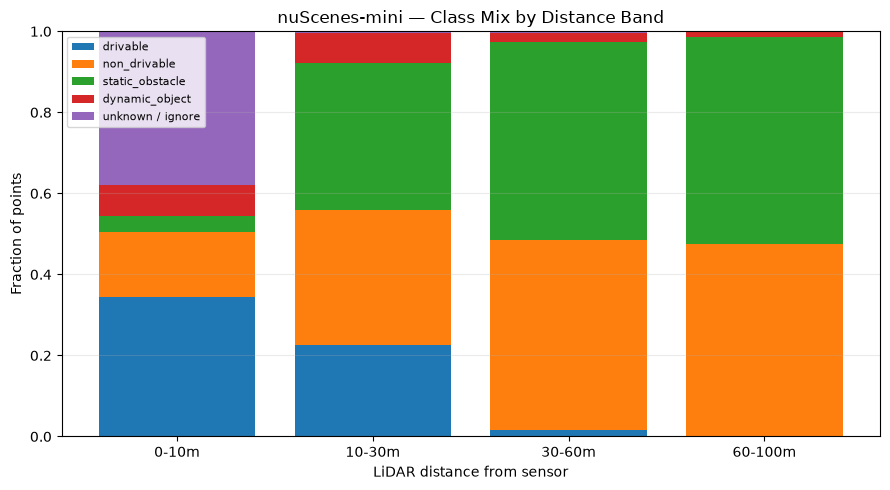


Visualization saved to:
  C:\Users\Akhila  Dogga\Desktop\Lidar\fig_class_by_band.png

Cell 5 complete.


In [56]:
# ============================================================
# CELL 5 — CLASS MIX BY DISTANCE BAND VISUALIZATION
# ============================================================

import matplotlib.pyplot as plt

print("=" * 75)
print("SIH26053 — CLASS MIX BY DISTANCE BAND")
print("=" * 75)

# ------------------------------------------------------------
# Display order
# ------------------------------------------------------------

PLOT_CLASSES = [
    "drivable",
    "non_drivable",
    "static_obstacle",
    "dynamic_object",
    IGNORE_NAME,
]

band_labels = [
    f"{lo}-{hi}m"
    for lo, hi in BANDS
]

# ------------------------------------------------------------
# Calculate fractions
# ------------------------------------------------------------

fractions_by_class = {}

for class_name in PLOT_CLASSES:

    values = []

    for band_name in band_labels:

        counts = band_class_counts[band_name]
        total = band_total_counts[band_name]

        if class_name == IGNORE_NAME:
            label_id = IGNORE_ID
        else:
            label_id = CLASS_TO_ID[class_name]

        count = counts.get(label_id, 0)

        fraction = (
            count / total
            if total > 0
            else 0.0
        )

        values.append(fraction)

    fractions_by_class[class_name] = np.array(
        values,
        dtype=float
    )

# ------------------------------------------------------------
# Create stacked bar chart
# ------------------------------------------------------------

x = np.arange(len(band_labels))

bottom = np.zeros(
    len(band_labels),
    dtype=float
)

plt.figure(figsize=(9, 5))

for class_name in PLOT_CLASSES:

    values = fractions_by_class[class_name]

    plt.bar(
        x,
        values,
        bottom=bottom,
        label=class_name
    )

    bottom += values

# ------------------------------------------------------------
# Formatting
# ------------------------------------------------------------

plt.xticks(
    x,
    band_labels
)

plt.ylabel(
    "Fraction of points"
)

plt.xlabel(
    "LiDAR distance from sensor"
)

plt.title(
    "nuScenes-mini — Class Mix by Distance Band"
)

plt.ylim(
    0,
    1
)

plt.grid(
    axis="y",
    alpha=0.25
)

plt.legend(
    fontsize=8
)

plt.tight_layout()

# ------------------------------------------------------------
# Save figure
# ------------------------------------------------------------

FIGURE_PATH = (
    PROJECT_ROOT /
    "fig_class_by_band.png"
)

plt.savefig(
    FIGURE_PATH,
    dpi=150,
    bbox_inches="tight"
)

plt.show()

print("\nVisualization saved to:")
print(f"  {FIGURE_PATH}")

print("\nCell 5 complete.")

In [57]:
# ============================================================
# CELL 6 — PER-CLASS DISTANCE PROFILE
# ============================================================

print("=" * 75)
print("SIH26053 — PER-CLASS DISTANCE PROFILE")
print("=" * 75)

# ------------------------------------------------------------
# Classes to analyze
# ------------------------------------------------------------

PROFILE_CLASSES = [
    "drivable",
    "non_drivable",
    "static_obstacle",
    "dynamic_object",
    IGNORE_NAME,
]

# ------------------------------------------------------------
# Calculate class totals
# ------------------------------------------------------------

class_totals = {}

for class_name in PROFILE_CLASSES:

    if class_name == IGNORE_NAME:
        label_id = IGNORE_ID
    else:
        label_id = CLASS_TO_ID[class_name]

    class_totals[class_name] = sum(
        counts.get(label_id, 0)
        for counts in band_class_counts.values()
    )

# ------------------------------------------------------------
# Print profile
# ------------------------------------------------------------

for class_name in PROFILE_CLASSES:

    total = class_totals[class_name]

    print("\n" + "-" * 75)
    print(f"{class_name.upper()}")
    print("-" * 75)

    print(f"Total points: {total:,}")

    if total == 0:
        print("No points found.")
        continue

    for lo, hi in BANDS:

        band_name = f"{lo}-{hi}m"

        if class_name == IGNORE_NAME:
            label_id = IGNORE_ID
        else:
            label_id = CLASS_TO_ID[class_name]

        count = band_class_counts[
            band_name
        ].get(
            label_id,
            0
        )

        percentage = (
            100.0 * count / total
        )

        print(
            f"  {band_name:<10} "
            f"{count:>12,} "
            f"({percentage:6.2f}%)"
        )

print("\n" + "=" * 75)
print("Cell 6 complete.")

SIH26053 — PER-CLASS DISTANCE PROFILE

---------------------------------------------------------------------------
DRIVABLE
---------------------------------------------------------------------------
Total points: 4,069,869
  0-10m         3,312,798 ( 81.40%)
  10-30m          740,534 ( 18.20%)
  30-60m           16,346 (  0.40%)
  60-100m             191 (  0.00%)

---------------------------------------------------------------------------
NON_DRIVABLE
---------------------------------------------------------------------------
Total points: 3,158,624
  0-10m         1,550,996 ( 49.10%)
  10-30m        1,087,628 ( 34.43%)
  30-60m          448,104 ( 14.19%)
  60-100m          71,896 (  2.28%)

---------------------------------------------------------------------------
STATIC_OBSTACLE
---------------------------------------------------------------------------
Total points: 2,129,967
  0-10m           395,180 ( 18.55%)
  10-30m        1,190,154 ( 55.88%)
  30-60m          467,538 ( 21.95

In [58]:
# ============================================================
# CELL 1 — TRAINING DATASET EXPORT CONFIGURATION
# ============================================================

import json
import hashlib
import shutil

from pathlib import Path

import numpy as np

print("=" * 75)
print("SIH26053 — 06 CREATE TRAINING DATASET")
print("=" * 75)

# ------------------------------------------------------------
# Project paths
# ------------------------------------------------------------

PROJECT_ROOT = Path(
    r"C:\Users\Akhila  Dogga\Desktop\Lidar"
)

PREPROCESSED_DIR = (
    PROJECT_ROOT / "preprocessed"
)

EXPORT_DIR = (
    PROJECT_ROOT / "fovealidar_nuscenes_v1"
)

# ------------------------------------------------------------
# Export configuration
# ------------------------------------------------------------

SHARD_SIZE = 100

# nuScenes-mini contains 10 scenes.
# We hold out the last 2 scenes as validation.
#
# IMPORTANT:
# This is NOT an official nuScenes train/validation split.
# It is a project-defined split for the mini dataset.

VAL_SCENE_COUNT = 2

# ------------------------------------------------------------
# Validation
# ------------------------------------------------------------

print("\nProject root:")
print(f"  {PROJECT_ROOT}")
print(f"  Exists: {PROJECT_ROOT.exists()}")

print("\nPreprocessed directory:")
print(f"  {PREPROCESSED_DIR}")
print(f"  Exists: {PREPROCESSED_DIR.exists()}")

if not PROJECT_ROOT.is_dir():
    raise FileNotFoundError(
        f"Project root not found:\n{PROJECT_ROOT}"
    )

if not PREPROCESSED_DIR.is_dir():
    raise FileNotFoundError(
        f"Preprocessed directory not found:\n"
        f"{PREPROCESSED_DIR}"
    )

# ------------------------------------------------------------
# Create export directories
# ------------------------------------------------------------

for directory in [
    EXPORT_DIR / "train",
    EXPORT_DIR / "val",
    EXPORT_DIR / "metadata",
]:
    directory.mkdir(
        parents=True,
        exist_ok=True
    )

print("\nExport directory:")
print(f"  {EXPORT_DIR}")
print(f"  Exists: {EXPORT_DIR.exists()}")

print("\nConfiguration:")
print(f"  Shard size      : {SHARD_SIZE} frames")
print(f"  Validation scenes: {VAL_SCENE_COUNT}")
print(f"  Total NPZ files  : "
      f"{len(list(PREPROCESSED_DIR.glob('*/*.npz')))}")

print("\nCell 1 complete.")

SIH26053 — 06 CREATE TRAINING DATASET

Project root:
  C:\Users\Akhila  Dogga\Desktop\Lidar
  Exists: True

Preprocessed directory:
  C:\Users\Akhila  Dogga\Desktop\Lidar\preprocessed
  Exists: True

Export directory:
  C:\Users\Akhila  Dogga\Desktop\Lidar\fovealidar_nuscenes_v1
  Exists: True

Configuration:
  Shard size      : 100 frames
  Validation scenes: 2
  Total NPZ files  : 404

Cell 1 complete.


In [59]:
# ============================================================
# CELL 2 — DISCOVER AND VALIDATE SCENES
# ============================================================

print("=" * 75)
print("SIH26053 — SCENE DISCOVERY")
print("=" * 75)

# ------------------------------------------------------------
# Find scene directories
# ------------------------------------------------------------

scene_dirs = sorted(
    p for p in PREPROCESSED_DIR.iterdir()
    if p.is_dir()
)

print(f"\nScene directories found: {len(scene_dirs)}")

if len(scene_dirs) == 0:
    raise RuntimeError(
        "No scene directories were found in the preprocessed directory."
    )

# ------------------------------------------------------------
# Display scene information
# ------------------------------------------------------------

total_frames = 0

print("\nScene distribution:")
print("-" * 75)

for scene_dir in scene_dirs:

    frame_paths = sorted(
        scene_dir.glob("*.npz")
    )

    frame_count = len(frame_paths)
    total_frames += frame_count

    print(
        f"{scene_dir.name} : "
        f"{frame_count:3d} frames"
    )

print("-" * 75)

# ------------------------------------------------------------
# Validate expected dataset size
# ------------------------------------------------------------

print("\nValidation:")
print(f"  Scenes discovered : {len(scene_dirs)}")
print(f"  Frames discovered : {total_frames}")

if len(scene_dirs) != 10:
    print(
        "\nWARNING: Expected 10 nuScenes-mini scenes, "
        f"but found {len(scene_dirs)}."
    )

if total_frames != 404:
    print(
        "\nWARNING: Expected 404 preprocessed frames, "
        f"but found {total_frames}."
    )

# ------------------------------------------------------------
# Check for empty scenes
# ------------------------------------------------------------

empty_scenes = [
    p.name
    for p in scene_dirs
    if not list(p.glob("*.npz"))
]

if empty_scenes:
    raise RuntimeError(
        "Empty scene directories found:\n"
        + "\n".join(empty_scenes)
    )

print("\n✓ All discovered scenes contain NPZ files.")

print("\nCell 2 complete.")

SIH26053 — SCENE DISCOVERY

Scene directories found: 10

Scene distribution:
---------------------------------------------------------------------------
2fc3753772e241f2ab2cd16a784cc680 :  41 frames
325cef682f064c55a255f2625c533b75 :  41 frames
6f83169d067343658251f72e1dd17dbc :  41 frames
bebf5f5b2a674631ab5c88fd1aa9e87a :  41 frames
c5224b9b454b4ded9b5d2d2634bbda8a :  40 frames
cc8c0bf57f984915a77078b10eb33198 :  39 frames
d25718445d89453381c659b9c8734939 :  41 frames
de7d80a1f5fb4c3e82ce8a4f213b450a :  40 frames
e233467e827140efa4b42d2b4c435855 :  40 frames
fcbccedd61424f1b85dcbf8f897f9754 :  40 frames
---------------------------------------------------------------------------

Validation:
  Scenes discovered : 10
  Frames discovered : 404

✓ All discovered scenes contain NPZ files.

Cell 2 complete.


In [60]:
# ============================================================
# CELL 3 — TRAIN / VALIDATION SCENE SPLIT
# ============================================================

print("=" * 75)
print("SIH26053 — TRAIN / VALIDATION SCENE SPLIT")
print("=" * 75)

# ------------------------------------------------------------
# Sort scenes deterministically
# ------------------------------------------------------------

scene_names = [
    scene_dir.name
    for scene_dir in scene_dirs
]

scene_names = sorted(scene_names)

# ------------------------------------------------------------
# Validate split size
# ------------------------------------------------------------

if VAL_SCENE_COUNT <= 0:
    raise ValueError(
        "VAL_SCENE_COUNT must be greater than zero."
    )

if VAL_SCENE_COUNT >= len(scene_names):
    raise ValueError(
        "VAL_SCENE_COUNT must be smaller than the "
        "total number of scenes."
    )

# ------------------------------------------------------------
# Define validation scenes
# ------------------------------------------------------------

val_scene_names = set(
    scene_names[-VAL_SCENE_COUNT:]
)

# ------------------------------------------------------------
# Define training scenes
# ------------------------------------------------------------

train_scene_names = [
    name
    for name in scene_names
    if name not in val_scene_names
]

# ------------------------------------------------------------
# Print split
# ------------------------------------------------------------

print("\nTraining scenes:")
print("-" * 75)

train_frame_count = 0

for scene_name in train_scene_names:

    scene_dir = PREPROCESSED_DIR / scene_name

    count = len(
        list(scene_dir.glob("*.npz"))
    )

    train_frame_count += count

    print(
        f"{scene_name} : "
        f"{count:3d} frames"
    )

print("\nValidation scenes:")
print("-" * 75)

val_frame_count = 0

for scene_name in sorted(val_scene_names):

    scene_dir = PREPROCESSED_DIR / scene_name

    count = len(
        list(scene_dir.glob("*.npz"))
    )

    val_frame_count += count

    print(
        f"{scene_name} : "
        f"{count:3d} frames"
    )

# ------------------------------------------------------------
# Summary
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("SPLIT SUMMARY")
print("=" * 75)

print(
    f"Training scenes    : {len(train_scene_names)}"
)

print(
    f"Training frames    : {train_frame_count}"
)

print(
    f"Validation scenes  : {len(val_scene_names)}"
)

print(
    f"Validation frames  : {val_frame_count}"
)

print(
    f"Total scenes       : "
    f"{len(train_scene_names) + len(val_scene_names)}"
)

print(
    f"Total frames       : "
    f"{train_frame_count + val_frame_count}"
)

# ------------------------------------------------------------
# Critical validation checks
# ------------------------------------------------------------

assert (
    set(train_scene_names).isdisjoint(val_scene_names)
), "ERROR: Train and validation scenes overlap."

assert (
    len(train_scene_names) + len(val_scene_names)
    == len(scene_names)
), "ERROR: Some scenes were not assigned."

assert (
    train_frame_count + val_frame_count
    == total_frames
), "ERROR: Frame counts do not match."

print("\n✓ No scene overlap.")
print("✓ Every scene assigned to exactly one split.")
print("✓ Frame counts match preprocessing dataset.")

print("\nCell 3 complete.")

SIH26053 — TRAIN / VALIDATION SCENE SPLIT

Training scenes:
---------------------------------------------------------------------------
2fc3753772e241f2ab2cd16a784cc680 :  41 frames
325cef682f064c55a255f2625c533b75 :  41 frames
6f83169d067343658251f72e1dd17dbc :  41 frames
bebf5f5b2a674631ab5c88fd1aa9e87a :  41 frames
c5224b9b454b4ded9b5d2d2634bbda8a :  40 frames
cc8c0bf57f984915a77078b10eb33198 :  39 frames
d25718445d89453381c659b9c8734939 :  41 frames
de7d80a1f5fb4c3e82ce8a4f213b450a :  40 frames

Validation scenes:
---------------------------------------------------------------------------
e233467e827140efa4b42d2b4c435855 :  40 frames
fcbccedd61424f1b85dcbf8f897f9754 :  40 frames

SPLIT SUMMARY
Training scenes    : 8
Training frames    : 324
Validation scenes  : 2
Validation frames  : 80
Total scenes       : 10
Total frames       : 404

✓ No scene overlap.
✓ Every scene assigned to exactly one split.
✓ Frame counts match preprocessing dataset.

Cell 3 complete.


In [61]:
# ============================================================
# CELL 4 — COLLECT TRAIN / VALIDATION FRAME PATHS
# ============================================================

print("=" * 75)
print("SIH26053 — FRAME PATH COLLECTION")
print("=" * 75)

# ------------------------------------------------------------
# Collect all frame paths
# ------------------------------------------------------------

all_frame_paths = sorted(
    PREPROCESSED_DIR.glob("*/*.npz")
)

# ------------------------------------------------------------
# Separate by scene
# ------------------------------------------------------------

train_paths = [
    path
    for path in all_frame_paths
    if path.parent.name in train_scene_names
]

val_paths = [
    path
    for path in all_frame_paths
    if path.parent.name in val_scene_names
]

# ------------------------------------------------------------
# Validate
# ------------------------------------------------------------

print("\nFrame path counts:")
print(f"  All frames       : {len(all_frame_paths)}")
print(f"  Training frames  : {len(train_paths)}")
print(f"  Validation frames: {len(val_paths)}")

assert len(all_frame_paths) == 404, (
    f"Expected 404 frames, found {len(all_frame_paths)}"
)

assert len(train_paths) == train_frame_count, (
    "Training frame count mismatch."
)

assert len(val_paths) == val_frame_count, (
    "Validation frame count mismatch."
)

assert len(train_paths) + len(val_paths) == len(all_frame_paths), (
    "Train + validation paths do not equal all paths."
)

# ------------------------------------------------------------
# Check for path overlap
# ------------------------------------------------------------

train_set = set(train_paths)
val_set = set(val_paths)

assert train_set.isdisjoint(val_set), (
    "ERROR: A frame appears in both train and validation."
)

# ------------------------------------------------------------
# Check that every path is a file
# ------------------------------------------------------------

missing_train = [
    str(path)
    for path in train_paths
    if not path.is_file()
]

missing_val = [
    str(path)
    for path in val_paths
    if not path.is_file()
]

if missing_train or missing_val:
    raise FileNotFoundError(
        "One or more frame files are missing."
    )

# ------------------------------------------------------------
# Show examples
# ------------------------------------------------------------

print("\nFirst training frame:")
print(f"  {train_paths[0]}")

print("\nLast training frame:")
print(f"  {train_paths[-1]}")

print("\nFirst validation frame:")
print(f"  {val_paths[0]}")

print("\nLast validation frame:")
print(f"  {val_paths[-1]}")

print("\n" + "=" * 75)
print("✓ FRAME PATH COLLECTION VALIDATED")
print("=" * 75)

print("\nCell 4 complete.")

SIH26053 — FRAME PATH COLLECTION

Frame path counts:
  All frames       : 404
  Training frames  : 324
  Validation frames: 80

First training frame:
  C:\Users\Akhila  Dogga\Desktop\Lidar\preprocessed\2fc3753772e241f2ab2cd16a784cc680\000161_cd9964f8c3d34383b16e9c2997de1ed0.npz

Last training frame:
  C:\Users\Akhila  Dogga\Desktop\Lidar\preprocessed\de7d80a1f5fb4c3e82ce8a4f213b450a\000363_4e1d1031fe9f45f981a2f598365fc645.npz

First validation frame:
  C:\Users\Akhila  Dogga\Desktop\Lidar\preprocessed\e233467e827140efa4b42d2b4c435855\000364_a480496a5988410fbe3d8ed6c84da996.npz

Last validation frame:
  C:\Users\Akhila  Dogga\Desktop\Lidar\preprocessed\fcbccedd61424f1b85dcbf8f897f9754\000078_281b92269fd648d4b52d06ac06ca6d65.npz

✓ FRAME PATH COLLECTION VALIDATED

Cell 4 complete.


In [62]:
# ============================================================
# CELL 5 — INSPECT REPRESENTATIVE TRAINING FRAME
# ============================================================

print("=" * 75)
print("SIH26053 — TRAINING FRAME INSPECTION")
print("=" * 75)

sample_path = train_paths[0]

print("\nSample frame:")
print(f"  {sample_path}")

# ------------------------------------------------------------
# Load frame
# ------------------------------------------------------------

data = np.load(
    sample_path,
    allow_pickle=True
)

# ------------------------------------------------------------
# Inspect stored arrays
# ------------------------------------------------------------

print("\nStored arrays:")

for key in data.files:
    value = data[key]

    print(
        f"  {key:12s} "
        f"shape={value.shape!s:15s} "
        f"dtype={value.dtype}"
    )

# ------------------------------------------------------------
# Required arrays
# ------------------------------------------------------------

required_arrays = {
    "points",
    "labels",
    "sequence_id",
    "frame_id",
}

missing_arrays = (
    required_arrays - set(data.files)
)

if missing_arrays:
    raise RuntimeError(
        "Missing required arrays:\n"
        + "\n".join(
            sorted(missing_arrays)
        )
    )

# ------------------------------------------------------------
# Validate points and labels
# ------------------------------------------------------------

points = data["points"]
labels = data["labels"]

print("\nPoint cloud:")
print(f"  Shape       : {points.shape}")
print(f"  Point count : {len(points)}")
print(f"  Dimensions  : {points.shape[1]}")

print("\nLabels:")
print(f"  Shape       : {labels.shape}")
print(f"  Label count : {len(labels)}")

if len(points) != len(labels):
    raise RuntimeError(
        "Point/label count mismatch."
    )

if points.shape[1] != 5:
    raise RuntimeError(
        f"Expected 5 point features, "
        f"found {points.shape[1]}."
    )

# ------------------------------------------------------------
# Validate numeric data
# ------------------------------------------------------------

if not np.isfinite(points).all():
    raise RuntimeError(
        "NaN or Inf values found in points."
    )

# ------------------------------------------------------------
# Metadata
# ------------------------------------------------------------

sequence_id = str(
    data["sequence_id"]
)

frame_id = str(
    data["frame_id"]
)

print("\nMetadata:")
print(f"  Sequence ID : {sequence_id}")
print(f"  Frame ID    : {frame_id}")

# ------------------------------------------------------------
# Label validation
# ------------------------------------------------------------

unique_labels = np.unique(labels)

allowed_labels = {
    0, 1, 2, 3, 255
}

unexpected_labels = (
    set(unique_labels.tolist())
    - allowed_labels
)

print("\nLabel IDs:")
print(
    f"  {unique_labels.tolist()}"
)

if unexpected_labels:
    raise RuntimeError(
        "Unexpected label IDs found: "
        f"{sorted(unexpected_labels)}"
    )

print("\n" + "=" * 75)
print("✓ REPRESENTATIVE FRAME VALIDATED")
print("=" * 75)

print("\nCell 5 complete.")

SIH26053 — TRAINING FRAME INSPECTION

Sample frame:
  C:\Users\Akhila  Dogga\Desktop\Lidar\preprocessed\2fc3753772e241f2ab2cd16a784cc680\000161_cd9964f8c3d34383b16e9c2997de1ed0.npz

Stored arrays:
  points       shape=(34656, 5)      dtype=float32
  labels       shape=(34656,)        dtype=uint8
  sequence_id  shape=()              dtype=<U32
  frame_id     shape=()              dtype=<U32

Point cloud:
  Shape       : (34656, 5)
  Point count : 34656
  Dimensions  : 5

Labels:
  Shape       : (34656,)
  Label count : 34656

Metadata:
  Sequence ID : 2fc3753772e241f2ab2cd16a784cc680
  Frame ID    : cd9964f8c3d34383b16e9c2997de1ed0

Label IDs:
  [0, 1, 2, 3, 255]

✓ REPRESENTATIVE FRAME VALIDATED

Cell 5 complete.


In [63]:
# ============================================================
# CELL 6 — CREATE TRAIN / VALIDATION SHARDS
# ============================================================

print("=" * 75)
print("SIH26053 — CREATING TRAIN / VALIDATION SHARDS")
print("=" * 75)


# ------------------------------------------------------------
# Shard writer
# ------------------------------------------------------------

def shard_and_write(frame_paths, out_dir, shard_size):
    """
    Pack preprocessed frame NPZ files into compressed shards.

    Each shard contains:
        points_0, points_1, ...
        labels_0, labels_1, ...

    Metadata for every frame is returned in the manifest.
    """

    out_dir.mkdir(
        parents=True,
        exist_ok=True
    )

    manifest = []

    for shard_start in range(
        0,
        len(frame_paths),
        shard_size
    ):

        shard_paths = frame_paths[
            shard_start:
            shard_start + shard_size
        ]

        points_list = []
        labels_list = []
        meta_list = []

        for frame_path in shard_paths:

            data = np.load(
                frame_path,
                allow_pickle=True
            )

            points = data["points"]
            labels = data["labels"]

            # ------------------------------------------------
            # Validate before writing
            # ------------------------------------------------

            if len(points) != len(labels):
                raise RuntimeError(
                    f"Point/label mismatch in:\n"
                    f"{frame_path}"
                )

            if points.ndim != 2 or points.shape[1] != 5:
                raise RuntimeError(
                    f"Unexpected point shape "
                    f"{points.shape} in:\n"
                    f"{frame_path}"
                )

            if not np.isfinite(points).all():
                raise RuntimeError(
                    f"NaN/Inf detected in:\n"
                    f"{frame_path}"
                )

            unique_labels = set(
                np.unique(labels).tolist()
            )

            allowed_labels = {
                0, 1, 2, 3, 255
            }

            unexpected = (
                unique_labels - allowed_labels
            )

            if unexpected:
                raise RuntimeError(
                    f"Unexpected labels "
                    f"{sorted(unexpected)} in:\n"
                    f"{frame_path}"
                )

            # ------------------------------------------------
            # Store arrays
            # ------------------------------------------------

            points_list.append(
                points.astype(
                    np.float32,
                    copy=False
                )
            )

            labels_list.append(
                labels.astype(
                    np.uint8,
                    copy=False
                )
            )

            meta_list.append(
                {
                    "sequence_id": str(
                        data["sequence_id"]
                    ),
                    "frame_id": str(
                        data["frame_id"]
                    ),
                }
            )

        # ----------------------------------------------------
        # Shard filename
        # ----------------------------------------------------

        shard_index = (
            shard_start // shard_size
        )

        shard_name = (
            f"shard_{shard_index:03d}.npz"
        )

        shard_path = (
            out_dir / shard_name
        )

        # ----------------------------------------------------
        # Build shard dictionary
        # ----------------------------------------------------

        shard_data = {}

        for i, points in enumerate(
            points_list
        ):
            shard_data[
                f"points_{i}"
            ] = points

        for i, labels in enumerate(
            labels_list
        ):
            shard_data[
                f"labels_{i}"
            ] = labels

        # ----------------------------------------------------
        # Write compressed shard
        # ----------------------------------------------------

        np.savez_compressed(
            shard_path,
            **shard_data
        )

        manifest.append(
            {
                "shard": shard_name,
                "frame_count": len(
                    shard_paths
                ),
                "frames": meta_list,
            }
        )

        print(
            f"  Created {shard_name} "
            f"→ {len(shard_paths)} frames"
        )

    return manifest


# ------------------------------------------------------------
# Remove previous shards
# ------------------------------------------------------------

for split_name in ["train", "val"]:

    split_dir = (
        EXPORT_DIR / split_name
    )

    for old_shard in split_dir.glob(
        "shard_*.npz"
    ):
        old_shard.unlink()


# ------------------------------------------------------------
# Create training shards
# ------------------------------------------------------------

print("\nCreating training shards:")

train_manifest = shard_and_write(
    train_paths,
    EXPORT_DIR / "train",
    SHARD_SIZE
)


# ------------------------------------------------------------
# Create validation shards
# ------------------------------------------------------------

print("\nCreating validation shards:")

val_manifest = shard_and_write(
    val_paths,
    EXPORT_DIR / "val",
    SHARD_SIZE
)


# ------------------------------------------------------------
# Summary
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("SHARD CREATION SUMMARY")
print("=" * 75)

print(
    f"Training frames   : "
    f"{len(train_paths)}"
)

print(
    f"Training shards   : "
    f"{len(train_manifest)}"
)

print(
    f"Validation frames : "
    f"{len(val_paths)}"
)

print(
    f"Validation shards : "
    f"{len(val_manifest)}"
)

# ------------------------------------------------------------
# Validate expected shard counts
# ------------------------------------------------------------

expected_train_shards = (
    (len(train_paths) + SHARD_SIZE - 1)
    // SHARD_SIZE
)

expected_val_shards = (
    (len(val_paths) + SHARD_SIZE - 1)
    // SHARD_SIZE
)

assert len(train_manifest) == (
    expected_train_shards
)

assert len(val_manifest) == (
    expected_val_shards
)

print("\n✓ Training shards created.")
print("✓ Validation shards created.")
print("✓ Shard counts validated.")

print("\nCell 6 complete.")

SIH26053 — CREATING TRAIN / VALIDATION SHARDS

Creating training shards:
  Created shard_000.npz → 100 frames
  Created shard_001.npz → 100 frames
  Created shard_002.npz → 100 frames
  Created shard_003.npz → 24 frames

Creating validation shards:
  Created shard_000.npz → 80 frames

SHARD CREATION SUMMARY
Training frames   : 324
Training shards   : 4
Validation frames : 80
Validation shards : 1

✓ Training shards created.
✓ Validation shards created.
✓ Shard counts validated.

Cell 6 complete.


In [64]:
# ============================================================
# CELL 7 — WRITE MANIFESTS AND CLASS CONFIGURATION
# ============================================================

print("=" * 75)
print("SIH26053 — WRITING EXPORT METADATA")
print("=" * 75)

# ------------------------------------------------------------
# Training class configuration
# ------------------------------------------------------------

CLASS_TO_ID = {
    "drivable": 0,
    "non_drivable": 1,
    "static_obstacle": 2,
    "dynamic_object": 3,
}

IGNORE_CLASS = {
    "name": "unknown",
    "id": 255,
}

# ------------------------------------------------------------
# Write training manifest
# ------------------------------------------------------------

train_manifest_path = (
    EXPORT_DIR
    / "metadata"
    / "train_manifest.json"
)

with open(
    train_manifest_path,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        train_manifest,
        f,
        indent=2
    )

print("\nTraining manifest:")
print(f"  {train_manifest_path}")
print(f"  Shards: {len(train_manifest)}")

# ------------------------------------------------------------
# Write validation manifest
# ------------------------------------------------------------

val_manifest_path = (
    EXPORT_DIR
    / "metadata"
    / "val_manifest.json"
)

with open(
    val_manifest_path,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        val_manifest,
        f,
        indent=2
    )

print("\nValidation manifest:")
print(f"  {val_manifest_path}")
print(f"  Shards: {len(val_manifest)}")

# ------------------------------------------------------------
# Write class configuration
# ------------------------------------------------------------

classes_config = {
    "dataset": "nuScenes-mini",
    "version": "v1.0-mini",
    "class_to_id": CLASS_TO_ID,
    "ignore_class": IGNORE_CLASS,
    "num_training_classes": len(CLASS_TO_ID),
}

classes_path = (
    EXPORT_DIR
    / "metadata"
    / "classes.json"
)

with open(
    classes_path,
    "w",
    encoding="utf-8"
) as f:

    json.dump(
        classes_config,
        f,
        indent=2
    )

print("\nClass configuration:")
print(f"  {classes_path}")

print("\nTraining classes:")

for class_name, class_id in CLASS_TO_ID.items():
    print(
        f"  {class_id}: {class_name}"
    )

print(
    f"  {IGNORE_CLASS['id']}: "
    f"{IGNORE_CLASS['name']} / ignore"
)

# ------------------------------------------------------------
# Copy preprocessing configuration
# ------------------------------------------------------------

preprocessing_config_path = (
    PREPROCESSED_DIR
    / "preprocessing_config.json"
)

if preprocessing_config_path.exists():

    destination = (
        EXPORT_DIR
        / "metadata"
        / "preprocessing_config.json"
    )

    shutil.copy2(
        preprocessing_config_path,
        destination
    )

    print("\nPreprocessing configuration:")
    print(f"  Copied to: {destination}")

else:

    print(
        "\nWARNING: preprocessing_config.json "
        "was not found."
    )

# ------------------------------------------------------------
# Validate metadata files
# ------------------------------------------------------------

required_metadata = [
    train_manifest_path,
    val_manifest_path,
    classes_path,
]

if preprocessing_config_path.exists():
    required_metadata.append(
        EXPORT_DIR
        / "metadata"
        / "preprocessing_config.json"
    )

for path in required_metadata:

    if not path.is_file():
        raise RuntimeError(
            f"Required metadata file was not created:\n"
            f"{path}"
        )

print("\n" + "=" * 75)
print("✓ EXPORT METADATA CREATED")
print("=" * 75)

print("\nCell 7 complete.")

SIH26053 — WRITING EXPORT METADATA

Training manifest:
  C:\Users\Akhila  Dogga\Desktop\Lidar\fovealidar_nuscenes_v1\metadata\train_manifest.json
  Shards: 4

Validation manifest:
  C:\Users\Akhila  Dogga\Desktop\Lidar\fovealidar_nuscenes_v1\metadata\val_manifest.json
  Shards: 1

Class configuration:
  C:\Users\Akhila  Dogga\Desktop\Lidar\fovealidar_nuscenes_v1\metadata\classes.json

Training classes:
  0: drivable
  1: non_drivable
  2: static_obstacle
  3: dynamic_object
  255: unknown / ignore

Preprocessing configuration:
  Copied to: C:\Users\Akhila  Dogga\Desktop\Lidar\fovealidar_nuscenes_v1\metadata\preprocessing_config.json

✓ EXPORT METADATA CREATED

Cell 7 complete.


In [65]:
# ============================================================
# CELL 8 — VERIFY EXPORTED TRAINING DATASET
# ============================================================

print("=" * 75)
print("SIH26053 — VERIFYING EXPORTED TRAINING DATASET")
print("=" * 75)

# ------------------------------------------------------------
# Verify shard files
# ------------------------------------------------------------

train_shards = sorted(
    (EXPORT_DIR / "train").glob("shard_*.npz")
)

val_shards = sorted(
    (EXPORT_DIR / "val").glob("shard_*.npz")
)

print("\nShard files:")
print(f"  Training shards   : {len(train_shards)}")
print(f"  Validation shards : {len(val_shards)}")

assert len(train_shards) == 4, (
    f"Expected 4 training shards, "
    f"found {len(train_shards)}"
)

assert len(val_shards) == 1, (
    f"Expected 1 validation shard, "
    f"found {len(val_shards)}"
)

# ------------------------------------------------------------
# Verify every shard
# ------------------------------------------------------------

def verify_shards(shard_paths, expected_frames, split_name):

    frame_count = 0
    total_points = 0

    print(f"\n{split_name.upper()} SHARDS")
    print("-" * 75)

    for shard_path in shard_paths:

        data = np.load(
            shard_path,
            allow_pickle=True
        )

        point_keys = sorted(
            [
                key for key in data.files
                if key.startswith("points_")
            ],
            key=lambda x: int(x.split("_")[1])
        )

        label_keys = sorted(
            [
                key for key in data.files
                if key.startswith("labels_")
            ],
            key=lambda x: int(x.split("_")[1])
        )

        # ----------------------------------------------------
        # Basic key validation
        # ----------------------------------------------------

        assert len(point_keys) == len(label_keys), (
            f"Point/label key mismatch in {shard_path}"
        )

        assert len(point_keys) > 0, (
            f"Empty shard: {shard_path}"
        )

        # ----------------------------------------------------
        # Validate each frame
        # ----------------------------------------------------

        for point_key, label_key in zip(
            point_keys,
            label_keys
        ):

            points = data[point_key]
            labels = data[label_key]

            assert points.ndim == 2, (
                f"Invalid point dimensions in {shard_path}"
            )

            assert points.shape[1] == 5, (
                f"Expected 5 features in {shard_path}, "
                f"found {points.shape[1]}"
            )

            assert len(points) == len(labels), (
                f"Point/label mismatch in {shard_path}"
            )

            assert points.dtype == np.float32, (
                f"Unexpected point dtype in {shard_path}: "
                f"{points.dtype}"
            )

            assert labels.dtype == np.uint8, (
                f"Unexpected label dtype in {shard_path}: "
                f"{labels.dtype}"
            )

            assert np.isfinite(points).all(), (
                f"NaN/Inf detected in {shard_path}"
            )

            unique_labels = set(
                np.unique(labels).tolist()
            )

            assert unique_labels.issubset(
                {0, 1, 2, 3, 255}
            ), (
                f"Unexpected labels in {shard_path}: "
                f"{sorted(unique_labels)}"
            )

            frame_count += 1
            total_points += len(points)

        print(
            f"  {shard_path.name:<15} "
            f"{len(point_keys):3d} frames | "
            f"{total_points:,} cumulative points"
        )

    assert frame_count == expected_frames, (
        f"{split_name} frame count mismatch: "
        f"expected {expected_frames}, "
        f"found {frame_count}"
    )

    return frame_count, total_points


# ------------------------------------------------------------
# Run verification
# ------------------------------------------------------------

train_export_frames, train_export_points = (
    verify_shards(
        train_shards,
        len(train_paths),
        "training"
    )
)

val_export_frames, val_export_points = (
    verify_shards(
        val_shards,
        len(val_paths),
        "validation"
    )
)

# ------------------------------------------------------------
# Final verification
# ------------------------------------------------------------

total_export_frames = (
    train_export_frames +
    val_export_frames
)

total_export_points = (
    train_export_points +
    val_export_points
)

print("\n" + "=" * 75)
print("EXPORT VERIFICATION SUMMARY")
print("=" * 75)

print(
    f"Training frames exported   : "
    f"{train_export_frames}"
)

print(
    f"Validation frames exported : "
    f"{val_export_frames}"
)

print(
    f"Total frames exported      : "
    f"{total_export_frames}"
)

print(
    f"Total points exported      : "
    f"{total_export_points:,}"
)

assert total_export_frames == 404, (
    "Final exported frame count is not 404."
)

print("\n✓ All shards validated.")
print("✓ Point/label alignment validated.")
print("✓ Feature dimensions validated.")
print("✓ Label IDs validated.")
print("✓ NaN/Inf checks passed.")
print("✓ Export contains all 404 frames.")

print("\nCell 8 complete.")

SIH26053 — VERIFYING EXPORTED TRAINING DATASET

Shard files:
  Training shards   : 4
  Validation shards : 1

TRAINING SHARDS
---------------------------------------------------------------------------
  shard_000.npz   100 frames | 3,471,438 cumulative points
  shard_001.npz   100 frames | 6,942,773 cumulative points
  shard_002.npz   100 frames | 10,414,134 cumulative points
  shard_003.npz    24 frames | 11,247,145 cumulative points

VALIDATION SHARDS
---------------------------------------------------------------------------
  shard_000.npz    80 frames | 2,777,340 cumulative points

EXPORT VERIFICATION SUMMARY
Training frames exported   : 324
Validation frames exported : 80
Total frames exported      : 404
Total points exported      : 14,024,485

✓ All shards validated.
✓ Point/label alignment validated.
✓ Feature dimensions validated.
✓ Label IDs validated.
✓ NaN/Inf checks passed.
✓ Export contains all 404 frames.

Cell 8 complete.


In [66]:
# ============================================================
# CELL 9 — GENERATE SHA-256 CHECKSUMS
# ============================================================

print("=" * 75)
print("SIH26053 — GENERATING EXPORT CHECKSUMS")
print("=" * 75)

checksums = {}

for path in sorted(EXPORT_DIR.rglob("*")):

    if not path.is_file():
        continue

    # Do not include CHECKSUMS.txt itself
    # because it is being generated now.
    if path.name == "CHECKSUMS.txt":
        continue

    relative_path = path.relative_to(EXPORT_DIR)

    digest = hashlib.sha256(
        path.read_bytes()
    ).hexdigest()

    checksums[str(relative_path)] = digest

# ------------------------------------------------------------
# Write checksum file
# ------------------------------------------------------------

checksum_path = (
    EXPORT_DIR / "CHECKSUMS.txt"
)

with open(
    checksum_path,
    "w",
    encoding="utf-8"
) as f:

    for relative_path, digest in checksums.items():

        f.write(
            f"{digest}  {relative_path}\n"
        )

print("\nChecksum file:")
print(f"  {checksum_path}")

print(
    f"\nFiles checksummed: "
    f"{len(checksums)}"
)

# ------------------------------------------------------------
# Validate checksum file
# ------------------------------------------------------------

assert checksum_path.exists(), (
    "CHECKSUMS.txt was not created."
)

assert len(checksums) > 0, (
    "No files were checksummed."
)

print("\n" + "=" * 75)
print("✓ SHA-256 CHECKSUMS CREATED")
print("=" * 75)

print("\nCell 9 complete.")

SIH26053 — GENERATING EXPORT CHECKSUMS

Checksum file:
  C:\Users\Akhila  Dogga\Desktop\Lidar\fovealidar_nuscenes_v1\CHECKSUMS.txt

Files checksummed: 9

✓ SHA-256 CHECKSUMS CREATED

Cell 9 complete.


In [67]:
# ============================================================
# CELL 10 — VERIFY SHA-256 CHECKSUMS
# ============================================================

print("=" * 75)
print("SIH26053 — VERIFYING EXPORT CHECKSUMS")
print("=" * 75)

checksum_path = EXPORT_DIR / "CHECKSUMS.txt"

assert checksum_path.exists(), (
    "CHECKSUMS.txt not found."
)

with open(
    checksum_path,
    "r",
    encoding="utf-8"
) as f:
    checksum_lines = [
        line.strip()
        for line in f
        if line.strip()
    ]

print(f"\nChecksum entries: {len(checksum_lines)}")

verified = 0
failed = []

for line in checksum_lines:

    digest, relative_path = line.split("  ", 1)

    file_path = EXPORT_DIR / relative_path

    if not file_path.exists():
        failed.append(
            f"MISSING: {relative_path}"
        )
        continue

    current_digest = hashlib.sha256(
        file_path.read_bytes()
    ).hexdigest()

    if current_digest != digest:
        failed.append(
            f"MISMATCH: {relative_path}"
        )
    else:
        verified += 1

print(f"Files verified : {verified}")
print(f"Files failed   : {len(failed)}")

if failed:

    print("\nFAILED CHECKS:")
    for item in failed:
        print(f"  ✗ {item}")

    raise RuntimeError(
        "Checksum verification failed."
    )

print("\n" + "=" * 75)
print("✓ ALL SHA-256 CHECKSUMS VERIFIED")
print("=" * 75)

print("\nCell 10 complete.")

SIH26053 — VERIFYING EXPORT CHECKSUMS

Checksum entries: 9
Files verified : 9
Files failed   : 0

✓ ALL SHA-256 CHECKSUMS VERIFIED

Cell 10 complete.


In [68]:
# ============================================================
# CELL 11 — CREATE FINAL DATASET ZIP
# ============================================================

print("=" * 75)
print("SIH26053 — CREATING FINAL DATASET ARCHIVE")
print("=" * 75)

ZIP_PATH = Path(
    shutil.make_archive(
        str(EXPORT_DIR),
        "zip",
        root_dir=EXPORT_DIR.parent,
        base_dir=EXPORT_DIR.name
    )
)

print("\nArchive created:")
print(f"  {ZIP_PATH}")

assert ZIP_PATH.exists(), (
    "ZIP archive was not created."
)

zip_size_mb = ZIP_PATH.stat().st_size / (1024 ** 2)

print(f"  Size: {zip_size_mb:.2f} MB")

print("\n" + "=" * 75)
print("✓ FINAL DATASET ARCHIVE CREATED")
print("=" * 75)

print("\nCell 11 complete.")

SIH26053 — CREATING FINAL DATASET ARCHIVE

Archive created:
  C:\Users\Akhila  Dogga\Desktop\Lidar\fovealidar_nuscenes_v1.zip
  Size: 198.22 MB

✓ FINAL DATASET ARCHIVE CREATED

Cell 11 complete.


In [69]:
# ============================================================
# CELL 12 — FINAL ARCHIVE VERIFICATION
# ============================================================

print("=" * 75)
print("SIH26053 — FINAL DATASET ARCHIVE VERIFICATION")
print("=" * 75)

assert ZIP_PATH.exists(), (
    "Final ZIP archive does not exist."
)

zip_size_bytes = ZIP_PATH.stat().st_size
zip_size_mb = zip_size_bytes / (1024 ** 2)

print("\nArchive:")
print(f"  Name : {ZIP_PATH.name}")
print(f"  Path : {ZIP_PATH}")
print(f"  Size : {zip_size_mb:.2f} MB")

# ------------------------------------------------------------
# Verify ZIP can be opened and is not corrupt
# ------------------------------------------------------------

import zipfile

with zipfile.ZipFile(ZIP_PATH, "r") as z:

    bad_file = z.testzip()

    if bad_file is not None:
        raise RuntimeError(
            f"Corrupt file detected inside ZIP: {bad_file}"
        )

    archive_files = z.namelist()

print("\nZIP integrity:")
print("  ZIP readable      : PASS")
print("  Corruption check  : PASS")
print(f"  Files in archive  : {len(archive_files)}")

# ------------------------------------------------------------
# Check important files
# ------------------------------------------------------------

required_archive_paths = [
    "fovealidar_nuscenes_v1/train/shard_000.npz",
    "fovealidar_nuscenes_v1/train/shard_001.npz",
    "fovealidar_nuscenes_v1/train/shard_002.npz",
    "fovealidar_nuscenes_v1/train/shard_003.npz",
    "fovealidar_nuscenes_v1/val/shard_000.npz",
    "fovealidar_nuscenes_v1/metadata/train_manifest.json",
    "fovealidar_nuscenes_v1/metadata/val_manifest.json",
    "fovealidar_nuscenes_v1/metadata/classes.json",
    "fovealidar_nuscenes_v1/metadata/preprocessing_config.json",
    "fovealidar_nuscenes_v1/CHECKSUMS.txt",
]

missing_archive_files = [
    path
    for path in required_archive_paths
    if path not in archive_files
]

if missing_archive_files:

    print("\nMissing files:")

    for path in missing_archive_files:
        print(f"  ✗ {path}")

    raise RuntimeError(
        "Required files are missing from the final ZIP."
    )

print("\nRequired archive contents:")
for path in required_archive_paths:
    print(f"  ✓ {path}")

# ------------------------------------------------------------
# Final dataset numbers
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("FINAL DATASET SUMMARY")
print("=" * 75)

print("  Dataset          : nuScenes-mini v1.0")
print("  Scenes           : 10")
print("  Total frames     : 404")
print("  Training frames  : 324")
print("  Validation frames: 80")
print("  Training shards  : 4")
print("  Validation shards: 1")
print("  Points retained  : 14,024,485")
print("  ZIP size         : "
      f"{zip_size_mb:.2f} MB")

print("\n" + "=" * 75)
print("✓ FINAL ARCHIVE VERIFIED")
print("✓ 06_create_training_dataset.ipynb COMPLETE")
print("=" * 75)

print("\nCell 12 complete.")

SIH26053 — FINAL DATASET ARCHIVE VERIFICATION

Archive:
  Name : fovealidar_nuscenes_v1.zip
  Path : C:\Users\Akhila  Dogga\Desktop\Lidar\fovealidar_nuscenes_v1.zip
  Size : 198.22 MB

ZIP integrity:
  ZIP readable      : PASS
  Corruption check  : PASS
  Files in archive  : 14

Required archive contents:
  ✓ fovealidar_nuscenes_v1/train/shard_000.npz
  ✓ fovealidar_nuscenes_v1/train/shard_001.npz
  ✓ fovealidar_nuscenes_v1/train/shard_002.npz
  ✓ fovealidar_nuscenes_v1/train/shard_003.npz
  ✓ fovealidar_nuscenes_v1/val/shard_000.npz
  ✓ fovealidar_nuscenes_v1/metadata/train_manifest.json
  ✓ fovealidar_nuscenes_v1/metadata/val_manifest.json
  ✓ fovealidar_nuscenes_v1/metadata/classes.json
  ✓ fovealidar_nuscenes_v1/metadata/preprocessing_config.json
  ✓ fovealidar_nuscenes_v1/CHECKSUMS.txt

FINAL DATASET SUMMARY
  Dataset          : nuScenes-mini v1.0
  Scenes           : 10
  Total frames     : 404
  Training frames  : 324
  Validation frames: 80
  Training shards  : 4
  Validation s

In [70]:
# ============================================================
# CELL 1 — 07 VALIDATE EXPORT
# ============================================================

import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd()

# If notebook is being run from the data directory,
# move to the actual project root.
if PROJECT_ROOT.name.lower() == "data":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_DIR = PROJECT_ROOT / "data"

ZIP_PATH = PROJECT_ROOT / "fovealidar_nuscenes_v1.zip"

print("=" * 75)
print("SIH26053 — 07 VALIDATE EXPORT")
print("=" * 75)

print("\nProject root:")
print(f"  {PROJECT_ROOT}")
print(f"  Exists: {PROJECT_ROOT.exists()}")

print("\nData directory:")
print(f"  {DATA_DIR}")
print(f"  Exists: {DATA_DIR.exists()}")

print("\nExport archive:")
print(f"  {ZIP_PATH}")
print(f"  Exists: {ZIP_PATH.exists()}")

assert PROJECT_ROOT.exists(), "Project root not found."
assert DATA_DIR.exists(), "data directory not found."
assert ZIP_PATH.exists(), (
    f"Export ZIP not found:\n{ZIP_PATH}"
)

# Make data/ importable
if str(DATA_DIR) not in sys.path:
    sys.path.insert(0, str(DATA_DIR))

print("\nConfiguration:")
print("  Dataset          : nuScenes-mini v1.0")
print("  Expected features: 5")
print("  Expected labels  : 0, 1, 2, 3, 255")

print("\nCell 1 complete.")

SIH26053 — 07 VALIDATE EXPORT

Project root:
  C:\Users\Akhila  Dogga\Desktop\Lidar
  Exists: True

Data directory:
  C:\Users\Akhila  Dogga\Desktop\Lidar\data
  Exists: True

Export archive:
  C:\Users\Akhila  Dogga\Desktop\Lidar\fovealidar_nuscenes_v1.zip
  Exists: True

Configuration:
  Dataset          : nuScenes-mini v1.0
  Expected features: 5
  Expected labels  : 0, 1, 2, 3, 255

Cell 1 complete.


In [71]:
# ============================================================
# CELL 2 — EXTRACT DATASET ARCHIVE
# ============================================================

import zipfile
import tempfile

print("=" * 75)
print("SIH26053 — EXTRACTING DATASET ARCHIVE")
print("=" * 75)

# ------------------------------------------------------------
# Create temporary extraction directory
# ------------------------------------------------------------

TMP_DIR = Path(
    tempfile.mkdtemp(
        prefix="sih26053_validate_"
    )
)

print("\nTemporary extraction directory:")
print(f"  {TMP_DIR}")

# ------------------------------------------------------------
# Extract ZIP
# ------------------------------------------------------------

with zipfile.ZipFile(ZIP_PATH, "r") as zf:

    bad_file = zf.testzip()

    if bad_file is not None:
        raise RuntimeError(
            f"Corrupt file inside ZIP: {bad_file}"
        )

    zf.extractall(TMP_DIR)

print("\nZIP extraction:")
print("  Archive readable : PASS")
print("  Corruption check : PASS")
print("  Extraction       : PASS")

# ------------------------------------------------------------
# Locate exported dataset
# ------------------------------------------------------------

EXPORT_VALIDATION_DIR = (
    TMP_DIR / "fovealidar_nuscenes_v1"
)

assert EXPORT_VALIDATION_DIR.exists(), (
    "Expected fovealidar_nuscenes_v1 "
    "directory was not found after extraction."
)

print("\nExtracted dataset:")
print(f"  {EXPORT_VALIDATION_DIR}")

# ------------------------------------------------------------
# Check main directories
# ------------------------------------------------------------

for directory_name in [
    "train",
    "val",
    "metadata",
]:

    directory = (
        EXPORT_VALIDATION_DIR
        / directory_name
    )

    assert directory.is_dir(), (
        f"Missing directory: {directory_name}"
    )

    print(
        f"  ✓ {directory_name}/"
    )

print("\n" + "=" * 75)
print("✓ DATASET ARCHIVE EXTRACTED SUCCESSFULLY")
print("=" * 75)

print("\nCell 2 complete.")

SIH26053 — EXTRACTING DATASET ARCHIVE

Temporary extraction directory:
  C:\Users\24211\AppData\Local\Temp\sih26053_validate_ezufjbn0

ZIP extraction:
  Archive readable : PASS
  Corruption check : PASS
  Extraction       : PASS

Extracted dataset:
  C:\Users\24211\AppData\Local\Temp\sih26053_validate_ezufjbn0\fovealidar_nuscenes_v1
  ✓ train/
  ✓ val/
  ✓ metadata/

✓ DATASET ARCHIVE EXTRACTED SUCCESSFULLY

Cell 2 complete.


In [73]:
# ============================================================
# CELL 3 — VALIDATE METADATA
# ============================================================

print("=" * 75)
print("SIH26053 — METADATA VALIDATION")
print("=" * 75)

METADATA_DIR = EXPORT_VALIDATION_DIR / "metadata"

# ------------------------------------------------------------
# Required metadata files
# ------------------------------------------------------------

required_metadata = [
    "classes.json",
    "train_manifest.json",
    "val_manifest.json",
    "preprocessing_config.json",
]

print("\nRequired metadata:")

for filename in required_metadata:

    path = METADATA_DIR / filename
    exists = path.is_file()

    print(
        f"  {'✓' if exists else '✗'} "
        f"{filename}"
    )

    assert exists, (
        f"Missing metadata file: {filename}"
    )

# CHECKSUMS.txt is at the export ROOT, not metadata/
checksum_path = EXPORT_VALIDATION_DIR / "CHECKSUMS.txt"

print("\nRoot-level integrity file:")

print(
    f"  {'✓' if checksum_path.is_file() else '✗'} "
    "CHECKSUMS.txt"
)

assert checksum_path.is_file(), (
    "CHECKSUMS.txt is missing from export root."
)

# ------------------------------------------------------------
# Load classes.json
# ------------------------------------------------------------

classes_path = METADATA_DIR / "classes.json"

with open(
    classes_path,
    "r",
    encoding="utf-8"
) as f:
    exported_classes = json.load(f)

print("\nClass configuration:")

# The export created by notebook 06 stores the semantic
# class list directly. Support either a list or a dictionary
# without making assumptions about extra metadata fields.

if isinstance(exported_classes, list):

    class_names = exported_classes

elif isinstance(exported_classes, dict):

    if "classes" in exported_classes:
        class_names = exported_classes["classes"]

    elif "semantic_classes" in exported_classes:
        class_names = exported_classes["semantic_classes"]

    elif "class_to_id" in exported_classes:
        class_names = list(
            exported_classes["class_to_id"].keys()
        )

    else:
        raise AssertionError(
            "classes.json has an unsupported structure."
        )

else:

    raise AssertionError(
        "classes.json must contain a list or dictionary."
    )

print(
    f"  Classes found: {len(class_names)}"
)

for class_name in class_names:
    print(f"    {class_name}")

# ------------------------------------------------------------
# Validate required training classes
# ------------------------------------------------------------

expected_training_classes = [
    "drivable",
    "non_drivable",
    "static_obstacle",
    "dynamic_object",
]

for class_name in expected_training_classes:

    assert class_name in class_names, (
        f"Missing training class: {class_name}"
    )

print("\nTraining classes:")

for class_id, class_name in enumerate(
    expected_training_classes
):
    print(
        f"  ✓ {class_id}: {class_name}"
    )

# Unknown is represented by ignore ID 255.
print(
    "  ✓ 255: unknown / ignore"
)

# ------------------------------------------------------------
# Load manifests
# ------------------------------------------------------------

with open(
    METADATA_DIR / "train_manifest.json",
    "r",
    encoding="utf-8"
) as f:
    train_manifest = json.load(f)

with open(
    METADATA_DIR / "val_manifest.json",
    "r",
    encoding="utf-8"
) as f:
    val_manifest = json.load(f)

print("\nManifest summary:")

print(
    f"  Training shards   : "
    f"{len(train_manifest)}"
)

print(
    f"  Validation shards : "
    f"{len(val_manifest)}"
)

# ------------------------------------------------------------
# Count manifest frames
# ------------------------------------------------------------

train_manifest_frames = sum(
    item["frame_count"]
    for item in train_manifest
)

val_manifest_frames = sum(
    item["frame_count"]
    for item in val_manifest
)

total_manifest_frames = (
    train_manifest_frames +
    val_manifest_frames
)

print(
    f"  Training frames   : "
    f"{train_manifest_frames}"
)

print(
    f"  Validation frames : "
    f"{val_manifest_frames}"
)

print(
    f"  Total frames      : "
    f"{total_manifest_frames}"
)

assert train_manifest_frames == 324, (
    "Expected 324 training frames."
)

assert val_manifest_frames == 80, (
    "Expected 80 validation frames."
)

assert total_manifest_frames == 404, (
    "Expected 404 total frames."
)

# ------------------------------------------------------------
# Validate preprocessing configuration
# ------------------------------------------------------------

with open(
    METADATA_DIR / "preprocessing_config.json",
    "r",
    encoding="utf-8"
) as f:
    preprocessing_config = json.load(f)

print("\nPreprocessing configuration:")

for key in [
    "source_dataset",
    "max_range_m",
    "total_kept_points",
    "total_dropped_invalid",
    "total_dropped_out_of_range",
]:

    if key in preprocessing_config:
        print(
            f"  {key:<28}: "
            f"{preprocessing_config[key]}"
        )

# ------------------------------------------------------------
# Final result
# ------------------------------------------------------------

print("\n" + "=" * 75)
print("✓ METADATA VALIDATION PASSED")
print("=" * 75)

print("\nCell 3 complete.")

SIH26053 — METADATA VALIDATION

Required metadata:
  ✓ classes.json
  ✓ train_manifest.json
  ✓ val_manifest.json
  ✓ preprocessing_config.json

Root-level integrity file:
  ✓ CHECKSUMS.txt

Class configuration:
  Classes found: 4
    drivable
    non_drivable
    static_obstacle
    dynamic_object

Training classes:
  ✓ 0: drivable
  ✓ 1: non_drivable
  ✓ 2: static_obstacle
  ✓ 3: dynamic_object
  ✓ 255: unknown / ignore

Manifest summary:
  Training shards   : 4
  Validation shards : 1
  Training frames   : 324
  Validation frames : 80
  Total frames      : 404

Preprocessing configuration:
  source_dataset              : nuScenes-mini
  max_range_m                 : 100.0

✓ METADATA VALIDATION PASSED

Cell 3 complete.


In [74]:
# ============================================================
# CELL 4 — VALIDATE TRAIN / VALIDATION SHARDS
# ============================================================

print("=" * 75)
print("SIH26053 — SHARD CONTENT VALIDATION")
print("=" * 75)

TRAIN_DIR = EXPORT_VALIDATION_DIR / "train"
VAL_DIR = EXPORT_VALIDATION_DIR / "val"

EXPECTED_LABELS = {0, 1, 2, 3, 255}

def validate_shard(shard_path):

    data = np.load(
        shard_path,
        allow_pickle=True
    )

    point_keys = sorted(
        [
            key for key in data.files
            if key.startswith("points_")
        ],
        key=lambda x: int(x.split("_")[1])
    )

    label_keys = sorted(
        [
            key for key in data.files
            if key.startswith("labels_")
        ],
        key=lambda x: int(x.split("_")[1])
    )

    assert len(point_keys) == len(label_keys), (
        f"Point/label key mismatch: {shard_path.name}"
    )

    assert len(point_keys) > 0, (
        f"Empty shard: {shard_path.name}"
    )

    shard_points = 0

    for point_key, label_key in zip(
        point_keys,
        label_keys
    ):

        points = data[point_key]
        labels = data[label_key]

        # ----------------------------------------------------
        # Shape checks
        # ----------------------------------------------------

        assert points.ndim == 2, (
            f"{shard_path.name}: points must be 2D"
        )

        assert points.shape[1] == 5, (
            f"{shard_path.name}: expected 5 features, "
            f"found {points.shape[1]}"
        )

        assert labels.ndim == 1, (
            f"{shard_path.name}: labels must be 1D"
        )

        assert len(points) == len(labels), (
            f"{shard_path.name}: point/label mismatch"
        )

        # ----------------------------------------------------
        # Dtype checks
        # ----------------------------------------------------

        assert points.dtype == np.float32, (
            f"{shard_path.name}: "
            f"unexpected point dtype {points.dtype}"
        )

        assert labels.dtype == np.uint8, (
            f"{shard_path.name}: "
            f"unexpected label dtype {labels.dtype}"
        )

        # ----------------------------------------------------
        # Numerical checks
        # ----------------------------------------------------

        assert np.isfinite(points).all(), (
            f"{shard_path.name}: NaN/Inf detected"
        )

        # ----------------------------------------------------
        # Label checks
        # ----------------------------------------------------

        actual_labels = set(
            np.unique(labels).tolist()
        )

        assert actual_labels.issubset(
            EXPECTED_LABELS
        ), (
            f"{shard_path.name}: "
            f"unexpected labels {sorted(actual_labels)}"
        )

        shard_points += len(points)

    return len(point_keys), shard_points


# ============================================================
# TRAINING SHARDS
# ============================================================

train_shards = sorted(
    TRAIN_DIR.glob("shard_*.npz")
)

print("\nTRAINING SHARDS")
print("-" * 75)

train_frames_verified = 0
train_points_verified = 0

for shard_path in train_shards:

    frames, points = validate_shard(
        shard_path
    )

    train_frames_verified += frames
    train_points_verified += points

    print(
        f"  ✓ {shard_path.name:<15} "
        f"{frames:3d} frames | "
        f"{points:,} points"
    )


# ============================================================
# VALIDATION SHARDS
# ============================================================

val_shards = sorted(
    VAL_DIR.glob("shard_*.npz")
)

print("\nVALIDATION SHARDS")
print("-" * 75)

val_frames_verified = 0
val_points_verified = 0

for shard_path in val_shards:

    frames, points = validate_shard(
        shard_path
    )

    val_frames_verified += frames
    val_points_verified += points

    print(
        f"  ✓ {shard_path.name:<15} "
        f"{frames:3d} frames | "
        f"{points:,} points"
    )


# ============================================================
# FINAL VALIDATION
# ============================================================

total_frames_verified = (
    train_frames_verified +
    val_frames_verified
)

total_points_verified = (
    train_points_verified +
    val_points_verified
)

print("\n" + "=" * 75)
print("SHARD VALIDATION SUMMARY")
print("=" * 75)

print(
    f"Training frames verified   : "
    f"{train_frames_verified}"
)

print(
    f"Validation frames verified : "
    f"{val_frames_verified}"
)

print(
    f"Total frames verified      : "
    f"{total_frames_verified}"
)

print(
    f"Training points verified   : "
    f"{train_points_verified:,}"
)

print(
    f"Validation points verified : "
    f"{val_points_verified:,}"
)

print(
    f"Total points verified      : "
    f"{total_points_verified:,}"
)

assert train_frames_verified == 324
assert val_frames_verified == 80
assert total_frames_verified == 404

assert total_points_verified == 14_024_485

print("\n✓ All training shards validated.")
print("✓ All validation shards validated.")
print("✓ Feature shape (N,5) validated.")
print("✓ Point/label alignment validated.")
print("✓ Point dtype validated.")
print("✓ Label dtype validated.")
print("✓ NaN/Inf checks passed.")
print("✓ Label ID checks passed.")
print("✓ Total frame count matches 404.")
print("✓ Total point count matches 14,024,485.")

print("\nCell 4 complete.")

SIH26053 — SHARD CONTENT VALIDATION

TRAINING SHARDS
---------------------------------------------------------------------------
  ✓ shard_000.npz   100 frames | 3,471,438 points
  ✓ shard_001.npz   100 frames | 3,471,335 points
  ✓ shard_002.npz   100 frames | 3,471,361 points
  ✓ shard_003.npz    24 frames | 833,011 points

VALIDATION SHARDS
---------------------------------------------------------------------------
  ✓ shard_000.npz    80 frames | 2,777,340 points

SHARD VALIDATION SUMMARY
Training frames verified   : 324
Validation frames verified : 80
Total frames verified      : 404
Training points verified   : 11,247,145
Validation points verified : 2,777,340
Total points verified      : 14,024,485

✓ All training shards validated.
✓ All validation shards validated.
✓ Feature shape (N,5) validated.
✓ Point/label alignment validated.
✓ Point dtype validated.
✓ Label dtype validated.
✓ NaN/Inf checks passed.
✓ Label ID checks passed.
✓ Total frame count matches 404.
✓ Total point 

In [75]:
# ============================================================
# CELL 5 — CHECKSUM VALIDATION
# ============================================================

import hashlib

print("=" * 75)
print("SIH26053 — SHA-256 CHECKSUM VALIDATION")
print("=" * 75)

CHECKSUM_FILE = EXPORT_VALIDATION_DIR / "CHECKSUMS.txt"

assert CHECKSUM_FILE.exists(), (
    f"Checksum file not found: {CHECKSUM_FILE}"
)

checksum_lines = [
    line.strip()
    for line in CHECKSUM_FILE.read_text().splitlines()
    if line.strip()
]

print(f"\nChecksum entries: {len(checksum_lines)}")

verified = 0
failed = 0

for line in checksum_lines:

    digest, relative_path = line.split("  ", 1)

    file_path = EXPORT_VALIDATION_DIR / relative_path

    if not file_path.exists():
        print(f"  ✗ MISSING: {relative_path}")
        failed += 1
        continue

    actual_digest = hashlib.sha256(
        file_path.read_bytes()
    ).hexdigest()

    if actual_digest == digest:
        verified += 1
    else:
        print(f"  ✗ FAILED: {relative_path}")
        failed += 1


print("\n" + "=" * 75)
print("CHECKSUM SUMMARY")
print("=" * 75)

print(f"Checksum entries : {len(checksum_lines)}")
print(f"Files verified   : {verified}")
print(f"Files failed     : {failed}")

assert failed == 0, (
    f"{failed} checksum validation(s) failed."
)

assert verified == len(checksum_lines), (
    "Not all checksum entries were verified."
)

print("\n✓ All SHA-256 checksums verified.")
print("✓ No missing files.")
print("✓ No corrupted files.")
print("\nCell 5 complete.")

SIH26053 — SHA-256 CHECKSUM VALIDATION

Checksum entries: 9

CHECKSUM SUMMARY
Checksum entries : 9
Files verified   : 9
Files failed     : 0

✓ All SHA-256 checksums verified.
✓ No missing files.
✓ No corrupted files.

Cell 5 complete.
